# Análisis multitemporal y predicción de la superficie hídrica del humedal Laguna Torca
**Proyecto de Data Science – Magíster** · Juan Pablo Maureira

Esta versión reemplaza el clima de estación (107 meses de precipitación, 57 de temperatura) por **CR2MET v2.0** (grilla 0.05°, 1979-2019, 492 meses completos) y corrige los problemas metodológicos de la versión anterior (imputación circular, suavizado con información futura, métricas dentro de la muestra, cambio de sensor sin controlar).

| Sección | Contenido | Pregunta de investigación |
|---|---|---|
| 0 | Configuración e imports | – |
| 1 | Descarga de la serie Landsat de Torca con Google Earth Engine | – |
| 2 | Curación de la serie satelital y diagnóstico del cambio de sensor | – |
| 3 | Clima: CR2MET (histórico) y proyecciones CR2 (RCP 2.6 / 8.5) | – |
| 4 | Base mensual para análisis y modelos (sin imputación) | – |
| 5 | Variación neta, estacionalidad, quiebres y anomalías | P1, P2 |
| 6 | Correlación con precipitación y temperatura | P3 |
| 7 | Modelos con validación cruzada temporal (clásicos vs ML) | P5 |
| 8 | Proyección 2025-2095 (RCP 2.6 vs RCP 8.5) | P4 |
| 9 | Comparación: datos observados vs imputación MICE | P5 |
| 10 | Modelo anual con MICE (el del notebook original): reconstrucción, correcciones y diagnóstico | P4, P5 |
| 11 | Exportación y notas metodológicas | – |
| 12 | Modelo anual: lluvia acumulada y SPEI, calibración de sensores, agua vs vegetación, proyección | P3, P4, P5 |

## 0. Configuración e imports

In [1]:
import io
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy.signal import savgol_filter
from scipy.stats import kendalltau, kruskal, spearmanr, theilslopes
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import IterativeImputer
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

try:
    from xgboost import XGBRegressor
except ImportError:
    XGBRegressor = None

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (14, 5)

In [2]:
# ----------------------------- Parámetros del proyecto -----------------------------
SEMILLA = 42
GEE_PROYECTO = "master-chess-412203"

FECHA_INICIO, FECHA_FIN = "1984-01-01", "2024-12-31"   # ventana de descarga Landsat
PERIODO_INFORME = ("2004", "2023")                      # periodo de las preguntas de investigación (área satelital)
NUBOSIDAD_MAX = 20                                      # % CLOUD_COVER máximo por escena
AREA_MIN_HA = 44.0                                      # Torca: menos que esto = nube total
FALLA_SLC_L7 = "2003-05-31"                             # Landsat 7 SLC-off
QUIEBRE_SENSOR = "2012-06-01"                           # 2012 no tiene escenas válidas: antes L5/L7, después L8/L9
FECHAS_AUDITADAS = ["2011-10-07", "2018-05-12", "2018-06-13",
                    "2019-05-22", "2019-06-07", "2018-07-22"]   # nubes confirmadas visualmente en GEE (solo Torca)

FORZAR_DESCARGA = False          # True = vuelve a bajar las series desde GEE (ignora la caché)
COL_AREA = "area_hectareas"

# ----------------------------- Rutas -----------------------------
def resolver_base():
    """Colab: carpeta del proyecto en Drive. Local: busca una carpeta 'data' junto al notebook."""
    if "google.colab" in sys.modules:
        from google.colab import drive
        drive.mount("/content/drive")
        return Path("/content/drive/MyDrive/Predicción laguna torca/data")
    for candidata in (Path("data"), Path("../data"), Path("../../data")):
        if candidata.exists():
            return candidata
    return Path("data")


BASE = resolver_base()
DIR_RAW, DIR_PROC = BASE / "raw", BASE / "processed"
DIR_PROC.mkdir(parents=True, exist_ok=True)


def buscar_archivo(patron, carpetas=(DIR_PROC, DIR_RAW)):
    """Primer archivo que coincide con el patrón (tolera diferencias de espacios/guiones en los nombres)."""
    for carpeta in carpetas:
        hallados = sorted(carpeta.glob(patron))
        if hallados:
            return hallados[0]
    return None


print("Carpeta de datos:", BASE.resolve())

Carpeta de datos: /home/claude/work/data


## 1. Google Earth Engine: serie de área de agua

Las cuatro misiones Landsat se procesan con **una sola función** parametrizada por las bandas (verde, NIR). La descarga se cachea en `data/processed`; si el CSV ya existe, **no se necesita GEE** para ejecutar el resto del notebook.

El polígono es el de tu proyecto.

In [3]:
COORDENADAS_TORCA = [
    [-72.0410805, -34.7577721], [-72.0367228, -34.7582617], [-72.0387713, -34.7682978],
    [-72.0319554, -34.7684813], [-72.0291981, -34.7765296], [-72.0353063, -34.7784569],
    [-72.0422712, -34.777172],  [-72.0449901, -34.7868999], [-72.0516198, -34.7914269],
    [-72.0545995, -34.786961],  [-72.0502045, -34.7824032], [-72.0491989, -34.7747858],
    [-72.0469641, -34.7673474], [-72.0410805, -34.7577721],
]
CUERPOS = {
    "torca": {"coords": COORDENADAS_TORCA, "cache": "serie_laguna_torca_bruta.csv"},
}

# colección -> (banda verde, banda NIR)
MISIONES = {
    "LANDSAT/LT05/C02/T1_L2": ("SR_B2", "SR_B4"),
    "LANDSAT/LE07/C02/T1_L2": ("SR_B2", "SR_B4"),
    "LANDSAT/LC08/C02/T1_L2": ("SR_B3", "SR_B5"),
    "LANDSAT/LC09/C02/T1_L2": ("SR_B3", "SR_B5"),
}


def iniciar_gee():
    import ee
    try:
        ee.Initialize(project=GEE_PROYECTO)
    except Exception:
        # modo 'notebook': muestra un enlace y una casilla para pegar el código (el modo por defecto de Colab abre una ventana emergente)
        ee.Authenticate(auth_mode="notebook")
        ee.Initialize(project=GEE_PROYECTO)
    return ee


def geometria(ee, cuerpo):
    return ee.Geometry.Polygon(CUERPOS[cuerpo]["coords"])


def descargar_serie_landsat(cuerpo):
    """NDWI > 0 (agua) por escena dentro del polígono; devuelve fecha, satélite y área en hectáreas."""
    ee = iniciar_gee()
    geom = geometria(ee, cuerpo)

    def enmascarar_nubes(img):
        qa = img.select("QA_PIXEL")   # bit 3 = nube, bit 4 = sombra de nube (USGS C2; comentario corregido 2026-11-08)
        return img.updateMask(qa.bitwiseAnd(1 << 3).eq(0).And(qa.bitwiseAnd(1 << 4).eq(0)))

    def coleccion(id_coleccion, verde, nir):
        return (ee.ImageCollection(id_coleccion).filterBounds(geom).filterDate(FECHA_INICIO, FECHA_FIN)
                .filter(ee.Filter.lt("CLOUD_COVER", NUBOSIDAD_MAX)).map(enmascarar_nubes)
                .map(lambda img: img.addBands(img.normalizedDifference([verde, nir]).rename("NDWI"))))

    def extraer_area(img):
        area = (img.select("NDWI").gt(0).multiply(ee.Image.pixelArea())
                .reduceRegion(reducer=ee.Reducer.sum(), geometry=geom, scale=30, maxPixels=1e9).get("NDWI"))
        return ee.Feature(None, {"fecha": img.date().format("YYYY-MM-dd"), "area_m2": area,
                                 "satelite": img.get("SPACECRAFT_ID")})

    cols = [coleccion(i, *b) for i, b in MISIONES.items()]
    todas = cols[0]
    for c in cols[1:]:
        todas = todas.merge(c)
    feats = todas.map(extraer_area).getInfo()["features"]
    df = pd.DataFrame([f["properties"] for f in feats]).dropna(subset=["area_m2"])
    df["fecha"] = pd.to_datetime(df["fecha"])
    df[COL_AREA] = df["area_m2"] / 10_000
    return df.sort_values("fecha").reset_index(drop=True)


def cargar_serie_bruta(cuerpo):
    ruta = buscar_archivo(CUERPOS[cuerpo]["cache"])
    if ruta is not None and not FORZAR_DESCARGA:
        df = pd.read_csv(ruta, parse_dates=["fecha"])
        print(f"[{cuerpo}] serie cargada desde caché: {ruta.name}")
    else:
        print(f"[{cuerpo}] descargando desde Google Earth Engine (puede tardar varios minutos)...")
        df = descargar_serie_landsat(cuerpo)
        df.to_csv(DIR_PROC / CUERPOS[cuerpo]["cache"], index=False)
    df = (df.drop_duplicates(subset=["fecha", "satelite", COL_AREA])
            .sort_values("fecha").reset_index(drop=True))
    print(f"[{cuerpo}] {len(df)} observaciones | {df['fecha'].min().date()} → {df['fecha'].max().date()}")
    return df


df_sat = cargar_serie_bruta("torca")
print(df_sat["satelite"].value_counts().to_string())
display(df_sat.head())

[torca] serie cargada desde caché: serie_laguna_torca_bruta.csv
[torca] 959 observaciones | 1985-01-25 → 2024-12-30
satelite
LANDSAT_7    433
LANDSAT_8    234
LANDSAT_5    220
LANDSAT_9     72


,area_m2,fecha,satelite,area_hectareas
0,1.252311e+06,1985-01-25,LANDSAT_5,125.231138
1,1.171401e+06,1986-01-28,LANDSAT_5,117.140116
2,1.345043e+06,1986-08-15,LANDSAT_5,134.504254
3,1.344010e+06,1986-10-11,LANDSAT_5,134.400965
4,1.300987e+06,1986-11-03,LANDSAT_5,130.098692


## 2. Curación de la serie satelital

1. Landsat 7 posterior a la falla del SLC (31-may-2003) → se anula (en varias escenas el SLC-off corta la laguna).
2. Área bajo el umbral físico (nube total) → se anula.
3. Caída > 15 % respecto de la mediana móvil local (nube parcial) → se anula.
4. "Valles" abruptos de corta duración (< 45 días a cada lado) → se anulan.
5. Fechas auditadas manualmente en GEE → se anulan.

**Importante:** esta limpieza quita escenas malas, pero **no corrige el cambio de sensor**. Landsat 5/7 y Landsat 8/9 miden niveles distintos de área para la misma laguna, y 2012 no tiene ninguna escena válida (no hay traslape para calibrarlos). Más abajo se cuantifica ese salto.

,registros anulados
1. Landsat 7 SLC-off,373
2. Área < 44 ha,58
3. Caída > 15% vs mediana móvil,30
4. Valles abruptos,1
5. Fechas auditadas en GEE,6


Observaciones válidas: 491 de 959


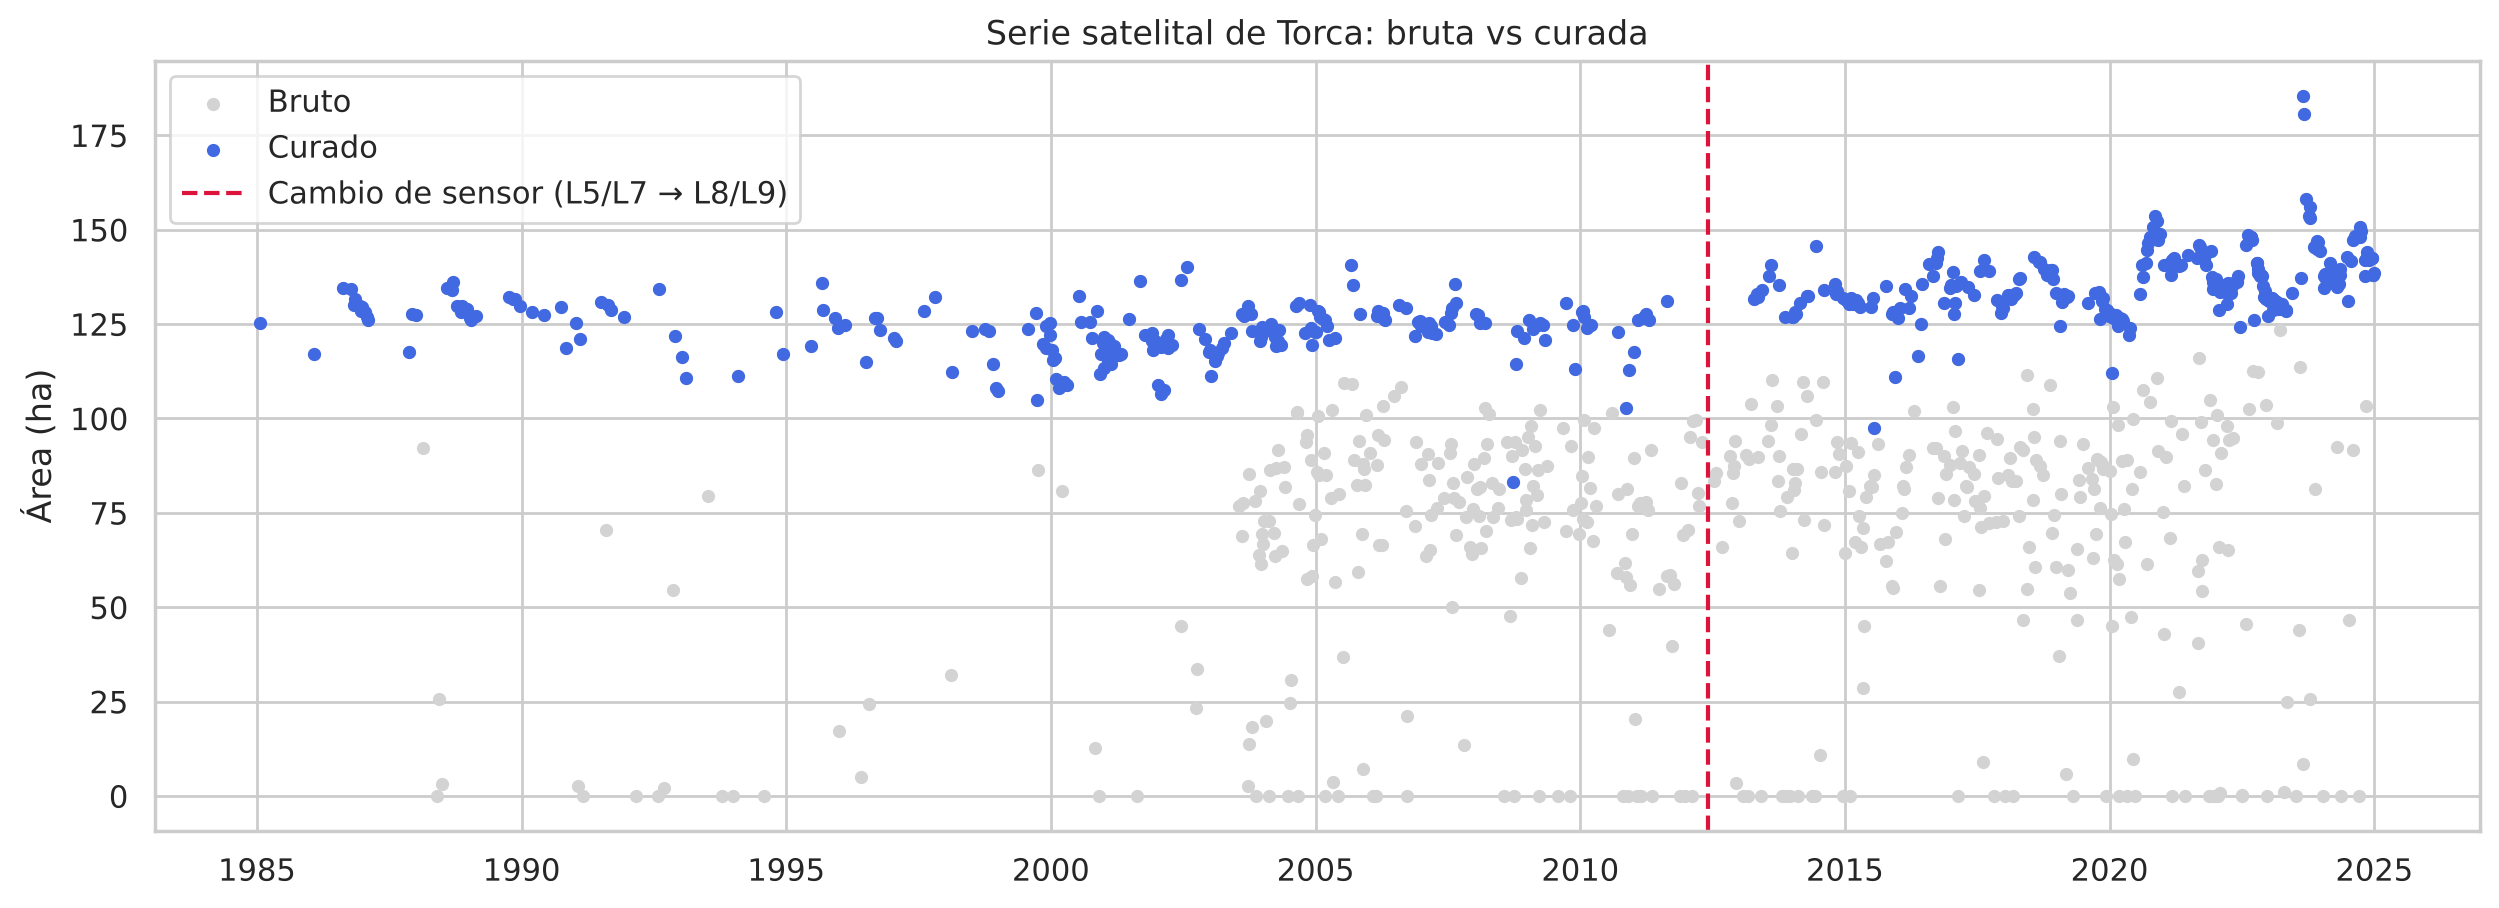

Área por sensor (escenas válidas):


,count,mean,std,min,max
sensor,,,,,
L5,180,124.6,6.5,83.2,140.6
L7,53,118.2,7.2,104.8,140.1
L8,197,135.3,8.0,97.4,158.0
L9,61,138.5,10.5,124.3,185.4


,count,mean,std
epoca,,,
L5/L7,233,123.1,7.2
L8/L9,258,136.0,8.7


Diferencia de nivel entre épocas: +12.9 ha (1.8 desviaciones estándar de la época L5/L7).
Esta diferencia mezcla cambio de sensor y cambio real; con los datos actuales NO se pueden separar.


In [4]:
def curar_serie(df, area_min=AREA_MIN_HA, fechas_auditadas=()):
    """Aplica las 5 reglas de curación. Devuelve (serie curada indexada por fecha, resumen)."""
    s = df.set_index("fecha").copy()
    resumen = {}

    def anular(mascara, nombre):
        antes = s[COL_AREA].notna().sum()
        s.loc[np.asarray(mascara), COL_AREA] = np.nan
        resumen[nombre] = int(antes - s[COL_AREA].notna().sum())

    anular(s["satelite"].str.contains("LANDSAT_7", case=False, na=False) & (s.index > FALLA_SLC_L7),
           "1. Landsat 7 SLC-off")
    anular(s[COL_AREA] < area_min, f"2. Área < {area_min:.0f} ha")
    mediana = s[COL_AREA].rolling(window=7, center=True, min_periods=3).median()
    anular(s[COL_AREA] < mediana * 0.85, "3. Caída > 15% vs mediana móvil")

    v = s[s[COL_AREA].notna()]
    fechas = v.index.to_series()
    dias_prev, dias_next = fechas.diff().dt.days, (-fechas.diff(-1)).dt.days
    var_prev = v[COL_AREA].pct_change(fill_method=None)
    var_next = v[COL_AREA].pct_change(periods=-1, fill_method=None)
    es_valle = (var_prev < -0.15) & (var_next < -0.15) & (dias_prev <= 45) & (dias_next <= 45)
    anular(s.index.isin(v.index[es_valle.values]), "4. Valles abruptos")

    anular(s.index.isin(pd.to_datetime(list(fechas_auditadas))), "5. Fechas auditadas en GEE")
    return s, pd.Series(resumen, name="registros anulados")


serie_curada, resumen_curacion = curar_serie(df_sat, AREA_MIN_HA, FECHAS_AUDITADAS)
display(resumen_curacion.to_frame())
print(f"Observaciones válidas: {serie_curada[COL_AREA].notna().sum()} de {len(serie_curada)}")

fig, ax = plt.subplots(figsize=(15, 5))
ax.scatter(df_sat["fecha"], df_sat[COL_AREA], s=14, color="lightgray", label="Bruto")
ax.scatter(serie_curada.index, serie_curada[COL_AREA], s=14, color="royalblue", label="Curado")
ax.axvline(pd.Timestamp(QUIEBRE_SENSOR), color="crimson", ls="--", label="Cambio de sensor (L5/L7 → L8/L9)")
ax.set(title="Serie satelital de Torca: bruta vs curada", ylabel="Área (ha)")
ax.legend()
plt.show()

# ---- Diagnóstico del cambio de sensor
valido = serie_curada[serie_curada[COL_AREA].notna()].copy()
valido["sensor"] = valido["satelite"].str.replace("LANDSAT_", "L", regex=False)
valido["epoca"] = np.where(valido.index > pd.Timestamp(QUIEBRE_SENSOR), "L8/L9", "L5/L7")
print("Área por sensor (escenas válidas):")
display(valido.groupby("sensor")[COL_AREA].agg(["count", "mean", "std", "min", "max"]).round(1))
por_epoca = valido.groupby("epoca")[COL_AREA].agg(["count", "mean", "std"]).round(1)
display(por_epoca)
SALTO_SENSOR_HA = por_epoca.loc["L8/L9", "mean"] - por_epoca.loc["L5/L7", "mean"]
print(f"Diferencia de nivel entre épocas: {SALTO_SENSOR_HA:+.1f} ha "
      f"({SALTO_SENSOR_HA / por_epoca.loc['L5/L7', 'std']:.1f} desviaciones estándar de la época L5/L7).")
print("Esta diferencia mezcla cambio de sensor y cambio real; con los datos actuales NO se pueden separar.")

serie_mensual = serie_curada[COL_AREA].resample("MS").mean()   # meses sin dato válido quedan en NaN (no se imputan)

## 3. Clima: CR2MET (histórico) y proyecciones CR2

**CR2MET v2.0** (producto grillado del CR2, 0.05°, mensual 1979-2019) se extrae en el píxel más cercano a la laguna. Frente a la estación cercana tuvo correlación 0.92 (precipitación), 0.96 (Tmax) y 0.95 (Tmin) en la verificación previa, y tiene los 492 meses completos. El valor de marzo de 2017 de la estación (807.9 mm) resultó ser un error de la estación y **ya no es un problema**.

Si existe `clima_cr2met_laguna_torca_mensual_1979_2019.csv` en `data/processed`, se usa directamente (14 KB). Si no, se extrae de los `.nc` de `data/raw` (346 MB cada uno) y se guarda.

In [5]:
LAT_LAGUNA, LON_LAGUNA = -34.77, -72.04
NC_CR2MET = {"precip": "CR2MET_pr_v2.0_mon_1979_2019_005deg.nc",
             "tmax": "CR2MET_tmax_v2.0_mon_1979_2019_005deg.nc",
             "tmin": "CR2MET_tmin_v2.0_mon_1979_2019_005deg.nc"}
VAR_NC = {"precip": "pr", "tmax": "tmax", "tmin": "tmin"}


def extraer_cr2met_desde_nc():
    """Serie mensual del píxel más cercano a la laguna. El tiempo viene como 'months since 1978-12-15', que xarray no
    decodifica: se abre con decode_times=False y se construyen las fechas a mano (492 meses desde 1979-01)."""
    import xarray as xr
    fechas = pd.date_range("1979-01-01", periods=492, freq="MS")
    cols = {}
    for var, nombre in NC_CR2MET.items():
        ruta = buscar_archivo(nombre, (DIR_RAW,))
        if ruta is None:
            raise FileNotFoundError(f"Falta {nombre} en {DIR_RAW}")
        ds = xr.open_dataset(ruta, decode_times=False)
        px = ds[VAR_NC[var]].sel(lat=LAT_LAGUNA, lon=LON_LAGUNA, method="nearest")
        assert len(px) == len(fechas), "el número de meses del .nc no coincide con lo esperado"
        cols[var] = pd.Series(px.values.astype(float), index=fechas)
        print(f"{var}: píxel lat={float(px.lat):.3f}, lon={float(px.lon):.3f}")
    df = pd.DataFrame(cols).rename_axis("fecha")
    df.rename(columns={"precip": "precip_mm", "tmax": "tmax_c", "tmin": "tmin_c"}).to_csv(
        DIR_PROC / "clima_cr2met_laguna_torca_mensual_1979_2019.csv")
    return df


def cargar_cr2met():
    ruta = buscar_archivo("clima_cr2met_laguna_torca*mensual*.csv")   # corregido 2026-11-08: el patrón genérico tomaba el clima de Aculeo
    if ruta is not None:
        df = pd.read_csv(ruta, parse_dates=["fecha"]).set_index("fecha")
        df = df.rename(columns={"precip_mm": "precip", "tmax_c": "tmax", "tmin_c": "tmin"})
        print("CR2MET cargado desde", ruta.name)
        return df
    print("No hay CSV de CR2MET: extrayendo desde los .nc ...")
    return extraer_cr2met_desde_nc()


df_clima = cargar_cr2met()[["precip", "tmax", "tmin"]].sort_index()
FIN_CLIMA = df_clima.index.max()
print(f"CR2MET: {len(df_clima)} meses | {df_clima.index.min().date()} → {FIN_CLIMA.date()} | "
      f"faltantes: {int(df_clima.isna().sum().sum())}")
display(df_clima.describe().round(2))

CR2MET cargado desde clima_cr2met_laguna_torca_mensual_1979_2019.csv
CR2MET: 492 meses | 1979-01-01 → 2019-12-01 | faltantes: 0


,precip,tmax,tmin
count,492.00,492.00,492.00
mean,49.62,19.63,7.60
std,70.60,3.21,2.51
min,0.00,13.01,2.45
25%,2.18,16.73,5.50
50%,16.89,20.13,7.10
75%,70.16,22.54,10.09
max,493.97,26.52,12.37


In [6]:
# ---- Proyecciones CR2 (GCMs por escenario). Las columnas se emparejan por NOMBRE: cada archivo trae distinto número de GCMs.
SUFIJO_VAR = {"precip": "pr", "tmax": "tasmax", "tmin": "tasmin"}
PATRON_PROY = {"precip": "proyeccin-de-la-precipit*.csv",
               "tmax": "proyeccin-de-la-temperat*max*.csv",
               "tmin": "proyeccin-de-la-temperat*min*.csv"}


def cargar_proyeccion_cr2(patron):
    """CSV del CR2: separador ';', decimal ',', con BOM."""
    ruta = buscar_archivo(patron, (DIR_RAW, DIR_PROC))
    if ruta is None:
        raise FileNotFoundError(f"No encuentro '{patron}' en {DIR_RAW}")
    texto = ruta.read_bytes().decode("utf-8-sig", errors="ignore")
    df = pd.read_csv(io.StringIO(texto), sep=";", decimal=",", thousands=".")
    df["DateTime"] = pd.to_datetime(df["DateTime"])
    return df.set_index("DateTime")


proy = {v: cargar_proyeccion_cr2(p) for v, p in PATRON_PROY.items()}
INICIO_PROY, DESDE_LAGS = "2025-01-01", "2024-10-01"      # DESDE_LAGS: 3 meses antes, para construir los rezagos
VARS_CLIMA = ("precip", "tmax", "tmin")


def gcms_completos(escenario, desde=DESDE_LAGS):
    """GCMs presentes en las tres variables, sin huecos desde `desde` y con 'historical' 1986-2005 (línea base)."""
    por_variable = []
    for var in VARS_CLIMA:
        suf, df, ok = SUFIJO_VAR[var], proy[var], set()
        for c in df.columns:
            if c.endswith(f"_{suf} {escenario}"):
                g = c[: -len(f"_{suf} {escenario}")]
                hist = f"{g}_{suf} historical"
                if df[c].loc[desde:].notna().all() and hist in df.columns and df[hist].loc["1986":"2005"].notna().all():
                    ok.add(g)
        por_variable.append(ok)
    return sorted(set.intersection(*por_variable))


for esc in ("rcp26", "rcp85"):
    print(f"{esc}: {len(gcms_completos(esc))} GCMs completos | último año disponible: "
          f"{proy['precip'].index.max().year}")

rcp26: 26 GCMs completos | último año disponible: 2095


rcp85: 39 GCMs completos | último año disponible: 2095


## 4. Base mensual para análisis y modelos

Cambios respecto de la versión anterior:

- **No se imputa el área.** MICE y Savitzky-Golay se eliminaron: con 65-70 % de meses sin dato en las décadas antiguas, la serie "completa" era sobre todo reconstrucción, y el suavizado centrado usa meses futuros (filtra información hacia la validación). Todo el análisis usa **meses con área observada**.
- Se calcula una **anomalía** del área sin la media de cada época de sensor y sin el ciclo estacional (`area_anom`). Sirve para preguntar si el clima explica la variación *dentro* de cada época, sin que el cambio de sensor domine.
- El clima proviene de CR2MET (1979-2019): los análisis que usan clima cubren hasta 2019.

480 meses (1985-01-01 → 2024-12-01) | 264 con área observada (55%) | sin imputar
Meses con área observada por década: {1980: 21, 1990: 36, 2000: 78, 2010: 73, 2020: 56}
Meses con área observada Y clima CR2MET: 208


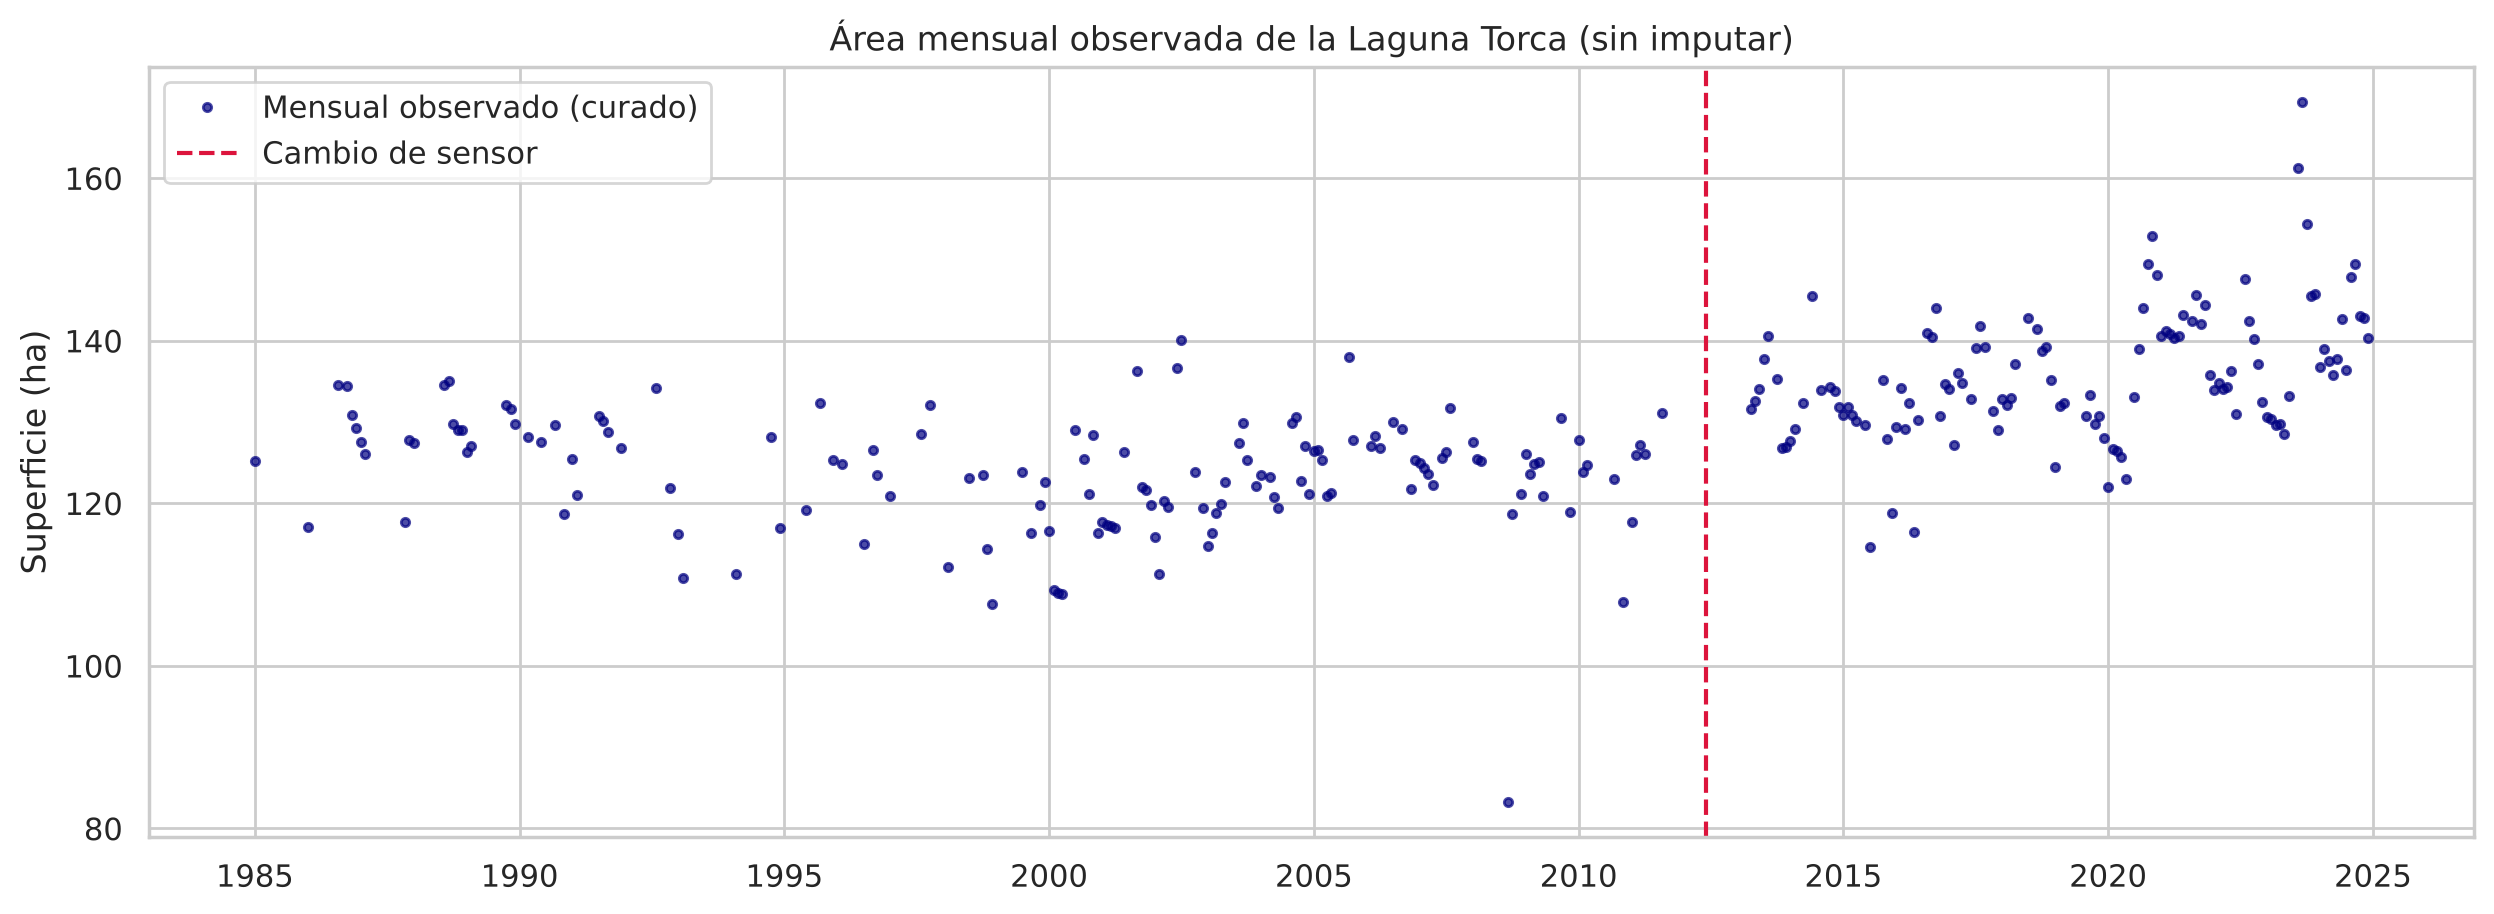

In [7]:
def construir_features(clima):
    """Precipitación, rezagos (1, 2 meses), acumulado 3 y 12 meses, temperaturas y estacionalidad cíclica."""
    out = clima[["precip", "tmax", "tmin"]].copy()
    out["p1"] = out["precip"].shift(1)
    out["p2"] = out["precip"].shift(2)
    out["p3"] = out["precip"].rolling(3).sum()
    out["p12"] = out["precip"].rolling(12).sum()
    out["mes_sin"] = np.sin(2 * np.pi * out.index.month / 12)   # seno/coseno: diciembre y enero quedan contiguos
    out["mes_cos"] = np.cos(2 * np.pi * out.index.month / 12)
    out["epoca"] = (out.index > pd.Timestamp(QUIEBRE_SENSOR)).astype(int)   # 0 = L5/L7, 1 = L8/L9
    return out


def anomalia_sin_epoca(s):
    """Quita la media de cada época de sensor y luego el ciclo estacional. Deja la variación 'interna' de cada época."""
    epoca = (s.index > pd.Timestamp(QUIEBRE_SENSOR)).astype(int)
    s_adj = s - s.groupby(epoca).transform("mean")
    return s_adj - s_adj.groupby(s_adj.index.month).transform("mean")


def anomalia_estacional(s):
    """Resta la media de cada mes calendario (sin separar épocas)."""
    return s - s.groupby(s.index.month).transform("mean")


df_modelo = serie_mensual.to_frame(COL_AREA).join(construir_features(df_clima), how="left")
mes = df_modelo.index.month                       # estacionalidad y época existen en TODO el periodo
df_modelo["mes_sin"], df_modelo["mes_cos"] = np.sin(2 * np.pi * mes / 12), np.cos(2 * np.pi * mes / 12)
df_modelo["epoca"] = (df_modelo.index > pd.Timestamp(QUIEBRE_SENSOR)).astype(int)
df_modelo["area_anom"] = anomalia_sin_epoca(df_modelo[COL_AREA])

n_obs = df_modelo[COL_AREA].notna().sum()
print(f"{len(df_modelo)} meses ({df_modelo.index.min().date()} → {df_modelo.index.max().date()}) | "
      f"{n_obs} con área observada ({n_obs / len(df_modelo):.0%}) | sin imputar")
obs_por_decada = df_modelo[COL_AREA].notna().groupby((df_modelo.index.year // 10) * 10).sum()
print("Meses con área observada por década:", obs_por_decada.to_dict())
n_con_clima = df_modelo.loc[:FIN_CLIMA].dropna(subset=[COL_AREA, "precip", "p3", "tmax", "tmin"]).shape[0]
print(f"Meses con área observada Y clima CR2MET: {n_con_clima}")

fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(df_modelo.index, df_modelo[COL_AREA], ".", color="navy", alpha=0.7, label="Mensual observado (curado)")
ax.axvline(pd.Timestamp(QUIEBRE_SENSOR), color="crimson", ls="--", label="Cambio de sensor")
ax.set(title="Área mensual observada de la Laguna Torca (sin imputar)", ylabel="Superficie (ha)")
ax.legend()
plt.show()

## 5. Variación neta, estacionalidad, quiebres y anomalías (preguntas 1 y 2)

Las variaciones anuales se calculan como **anomalía respecto de la climatología mensual** y solo para años con ≥ 3 meses observados; así un año con pocas escenas de verano no parece "más seco" solo por cuándo pasó el satélite. Los años siguientes a 2012 no se comparan con 2011 (hay un hueco de un año y un cambio de sensor).

Variación anual neta 2004-2023 (años con ≥ 3 meses observados):


,area_media_obs,meses_obs,anom_ha,variacion_anom_ha,epoca
fecha,,,,,
2004,124.25,9,-5.38,1.89,L5/L7
2005,126.60,7,-1.68,3.70,L5/L7
2006,126.92,7,-1.54,0.14,L5/L7
2007,125.55,7,-3.75,-2.21,L5/L7
2008,116.89,6,-11.60,-7.85,L5/L7
2009,124.29,7,-3.49,8.10,L5/L7
2010,121.44,5,-6.56,-3.07,L5/L7
2011,125.61,5,-2.84,3.73,L5/L7
2013,133.20,8,2.78,NaN,L8/L9


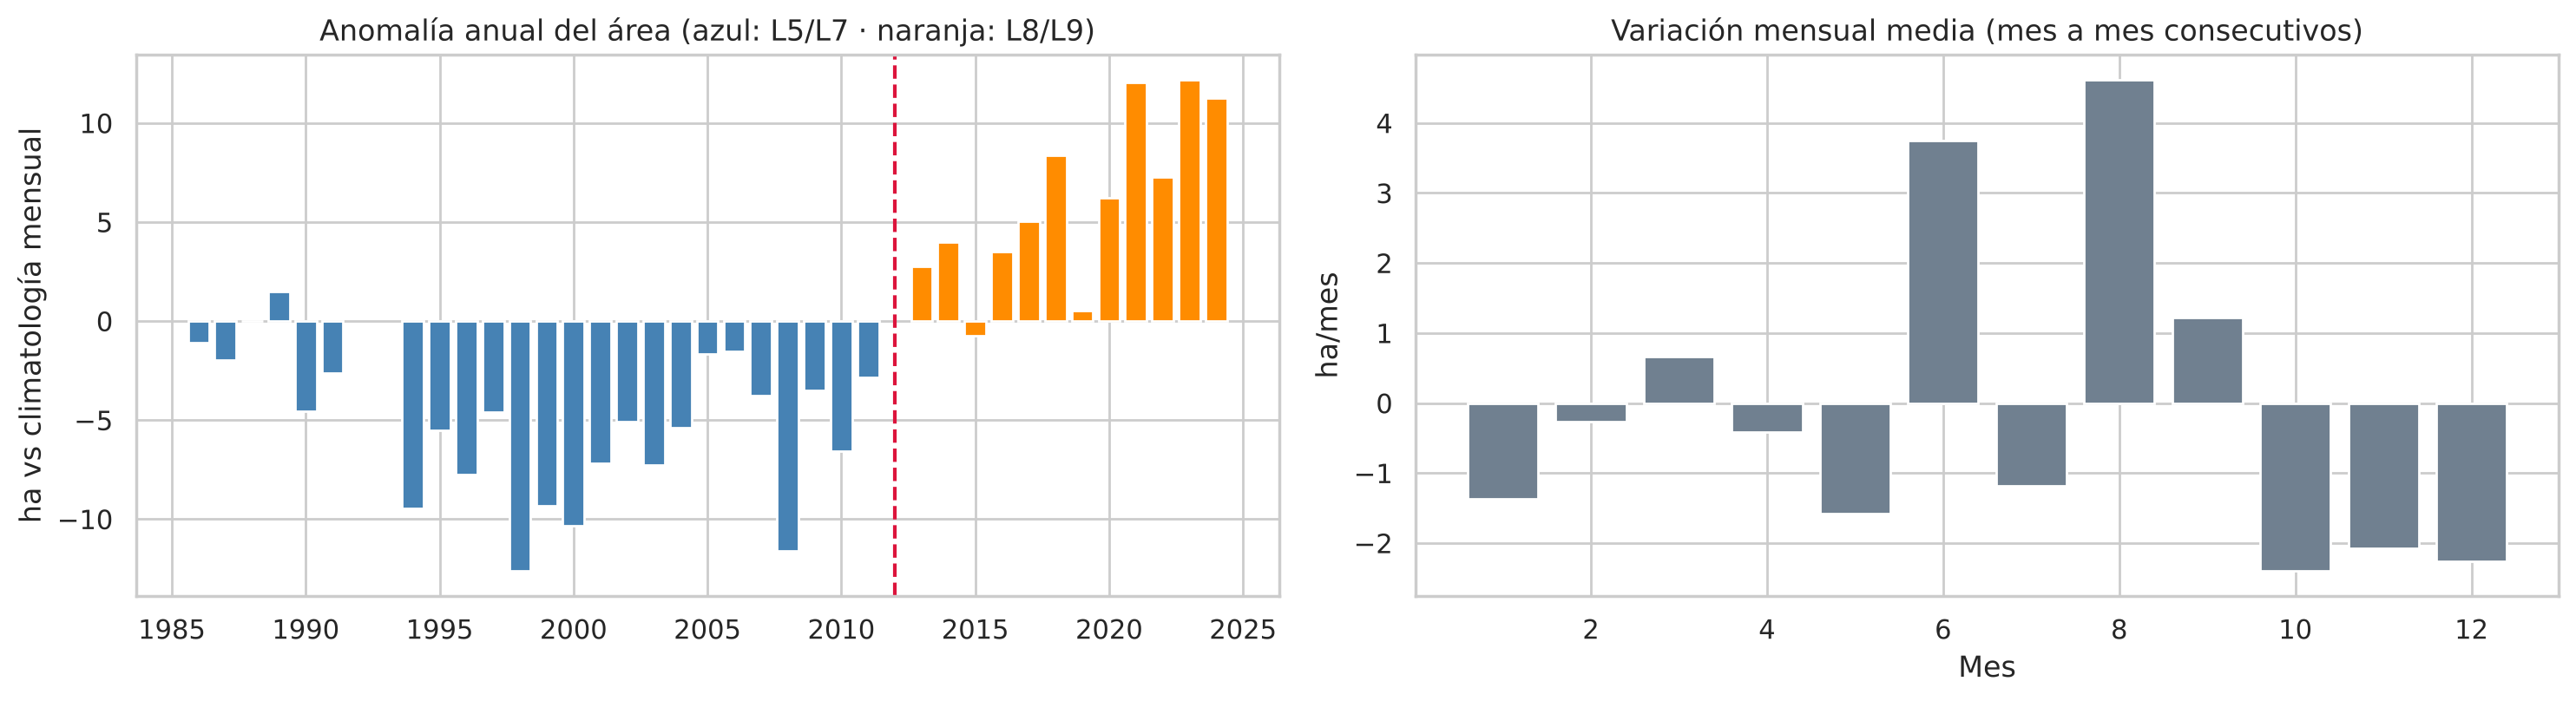

Pares de meses consecutivos usados por mes: {1: 22, 2: 25, 3: 21, 4: 19, 5: 11, 6: 6, 7: 6, 8: 6, 9: 12, 10: 16, 11: 18, 12: 22}


In [8]:
# ---- Variación neta anual (anomalía vs climatología mensual de toda la serie)
area = df_modelo[COL_AREA]
clim_mes = area.groupby(area.index.month).mean()
anom_clim = area - clim_mes.reindex(area.index.month).values
anual = pd.DataFrame({"area_media_obs": area.groupby(area.index.year).mean(),
                      "meses_obs": area.groupby(area.index.year).count(),
                      "anom_ha": anom_clim.groupby(anom_clim.index.year).mean()})
anual = anual[anual["meses_obs"] >= 3].copy()
consecutivo = anual.index.to_series().diff() == 1
anual["variacion_anom_ha"] = anual["anom_ha"].diff().where(consecutivo)
anual["epoca"] = np.where(anual.index > pd.Timestamp(QUIEBRE_SENSOR).year, "L8/L9", "L5/L7")

a, b = (int(x) for x in PERIODO_INFORME)
print(f"Variación anual neta {a}-{b} (años con ≥ 3 meses observados):")
display(anual.loc[a:b].round(2))

# ---- Variación mensual neta (solo entre meses consecutivos con observación)
dif_mes = area.diff()
por_mes = dif_mes.groupby(dif_mes.index.month).agg(["mean", "count"]).round(2)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
colores = np.where(anual["epoca"] == "L8/L9", "darkorange", "steelblue")
axes[0].bar(anual.index, anual["anom_ha"], color=colores)
axes[0].axvline(pd.Timestamp(QUIEBRE_SENSOR).year, color="crimson", ls="--")
axes[0].set(title="Anomalía anual del área (azul: L5/L7 · naranja: L8/L9)", ylabel="ha vs climatología mensual")
axes[1].bar(por_mes.index, por_mes["mean"], color="slategray")
axes[1].set(title="Variación mensual media (mes a mes consecutivos)", xlabel="Mes", ylabel="ha/mes")
plt.tight_layout()
plt.show()
print("Pares de meses consecutivos usados por mes:", por_mes["count"].to_dict())

In [9]:
# ---- Tendencia (Kendall) y quiebre (Pettitt) sobre la anomalía anual
def pettitt(x):
    """Test de Pettitt: (posición del quiebre, estadístico K, p-valor aproximado)."""
    x = np.asarray(x, dtype=float)
    n = len(x)
    r = pd.Series(x).rank().values
    U = 2 * np.cumsum(r) - np.arange(1, n + 1) * (n + 1)
    K = np.abs(U).max()
    return int(np.abs(U).argmax()), K, min(1.0, 2 * np.exp(-6 * K ** 2 / (n ** 3 + n ** 2)))


def tendencia(serie, etiqueta):
    if len(serie) < 5:
        print(f"{etiqueta}: muestra insuficiente ({len(serie)} años)")
        return
    tau, p = kendalltau(serie.index, serie.values)
    pend = theilslopes(serie.values, serie.index)[0]
    print(f"{etiqueta:34s} n={len(serie):2d} años | tau={tau:+.2f} (p={p:.3f}) | pendiente Theil-Sen={pend:+.2f} ha/año")


tendencia(anual["anom_ha"], "Serie completa (mezcla sensores)")
tendencia(anual.loc[anual["epoca"] == "L5/L7", "anom_ha"], "Solo época L5/L7")
tendencia(anual.loc[anual["epoca"] == "L8/L9", "anom_ha"], "Solo época L8/L9")

t_q, K_q, p_q = pettitt(anual["anom_ha"].values)
anio_q = int(anual.index[t_q])
print(f"\nPettitt: quiebre tras {anio_q} (p ≈ {p_q:.4f}); anomalía media antes = {anual['anom_ha'].iloc[:t_q + 1].mean():+.1f} ha, "
      f"después = {anual['anom_ha'].iloc[t_q + 1:].mean():+.1f} ha")
if abs(anio_q - pd.Timestamp(QUIEBRE_SENSOR).year) <= 2:
    print("→ El quiebre estadístico COINCIDE con el cambio de sensor Landsat 5/7 → 8/9. Con estos datos no se puede afirmar que sea "
          "un cambio hidrológico; podría ser (en parte o del todo) un artefacto del sensor.")

Serie completa (mezcla sensores)   n=36 años | tau=+0.45 (p=0.000) | pendiente Theil-Sen=+0.43 ha/año
Solo época L5/L7                   n=24 años | tau=-0.14 (p=0.363) | pendiente Theil-Sen=-0.11 ha/año
Solo época L8/L9                   n=12 años | tau=+0.61 (p=0.005) | pendiente Theil-Sen=+0.93 ha/año

Pettitt: quiebre tras 2011 (p ≈ 0.0001); anomalía media antes = -5.2 ha, después = +6.0 ha
→ El quiebre estadístico COINCIDE con el cambio de sensor Landsat 5/7 → 8/9. Con estos datos no se puede afirmar que sea un cambio hidrológico; podría ser (en parte o del todo) un artefacto del sensor.


Kruskal-Wallis entre los 12 meses del año: H = 66.9, p = 0.0000 → hay estacionalidad estadísticamente detectable en el área.


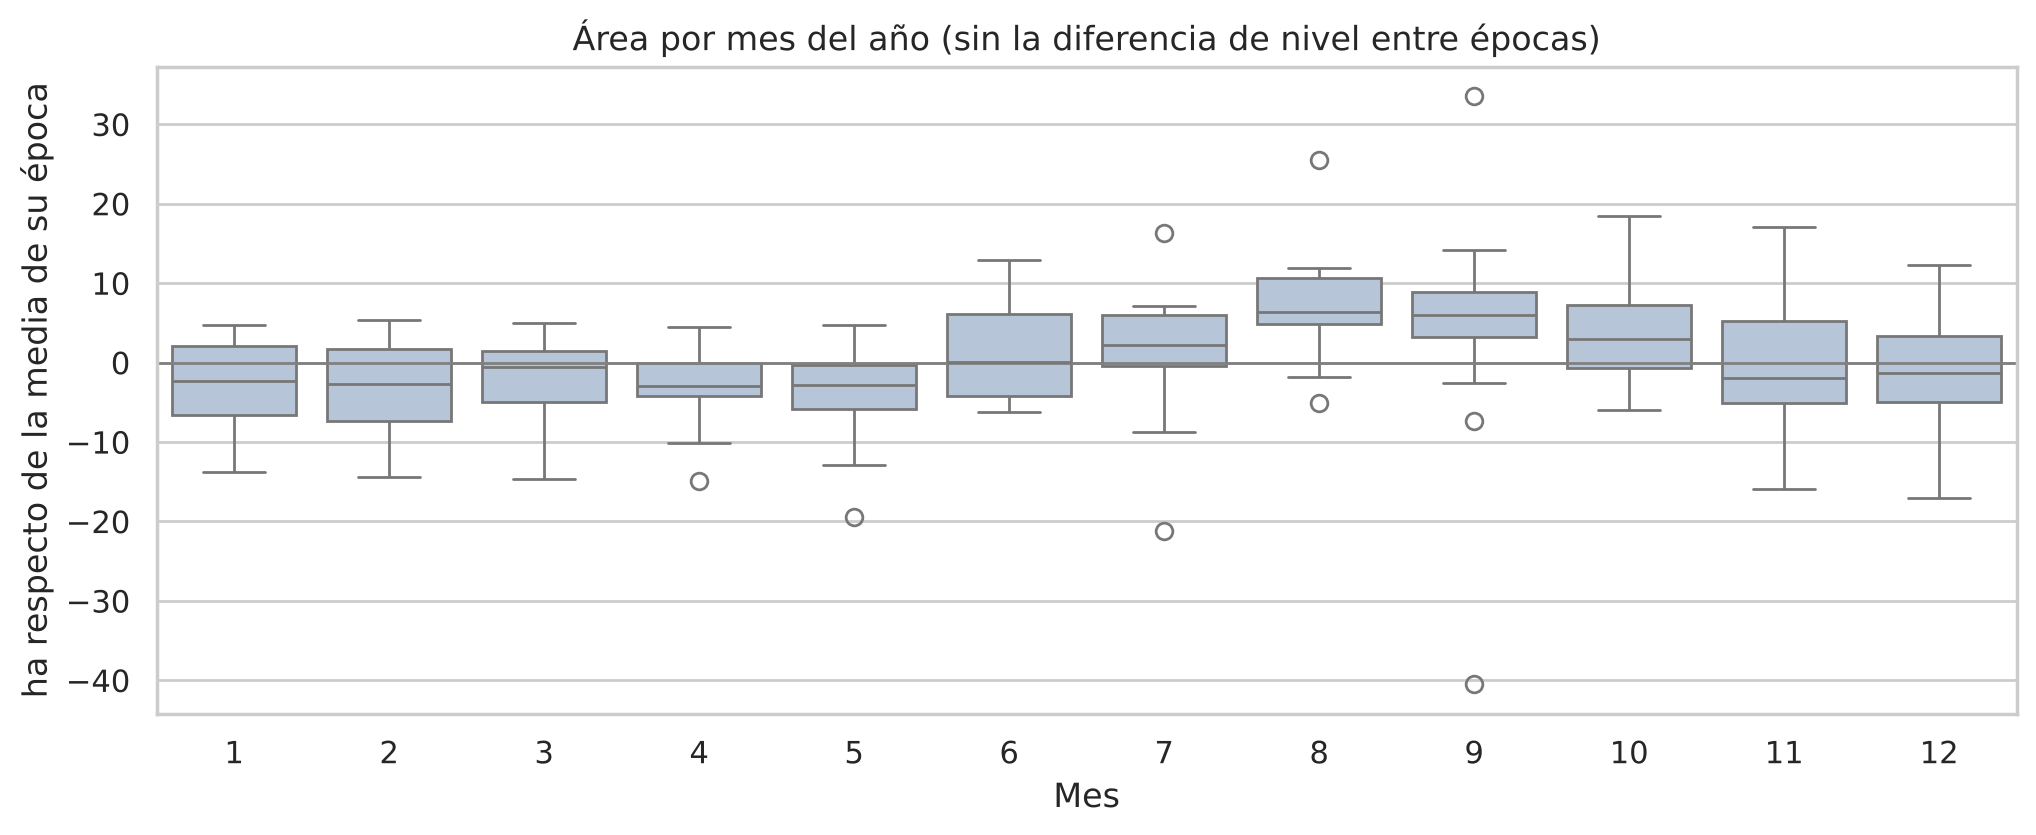


Meses con |anomalía| > 2.5σ (σ = 6.8 ha): 5
fecha
2008-09-01   -45.6
2015-07-01   -22.4
2020-11-01    17.4
2023-08-01    18.3
2023-09-01    28.5
Revisa estas fechas en GEE: pueden ser nube/sombra residual (error) o eventos reales.


In [10]:
# ---- Estacionalidad (sin el efecto de época) y anomalías
area_adj = area - area.groupby(df_modelo["epoca"]).transform("mean")
grupos = [g.dropna().values for _, g in area_adj.groupby(area_adj.index.month)]
H, p_kw = kruskal(*grupos)
print(f"Kruskal-Wallis entre los 12 meses del año: H = {H:.1f}, p = {p_kw:.4f} "
      f"→ {'hay' if p_kw < 0.05 else 'NO hay'} estacionalidad estadísticamente detectable en el área.")

fig, ax = plt.subplots(figsize=(12, 4.2))
sns.boxplot(x=area_adj.dropna().index.month, y=area_adj.dropna().values, ax=ax, color="lightsteelblue")
ax.axhline(0, color="gray", lw=1)
ax.set(title="Área por mes del año (sin la diferencia de nivel entre épocas)", xlabel="Mes", ylabel="ha respecto de la media de su época")
plt.show()

# ---- Anomalías: meses que se alejan > 2.5 σ de lo esperado para su época y mes
an = df_modelo["area_anom"].dropna()
extremos = an[np.abs(an) > 2.5 * an.std()]
print(f"\nMeses con |anomalía| > 2.5σ (σ = {an.std():.1f} ha): {len(extremos)}")
print(extremos.round(1).to_string() if len(extremos) else "ninguno")
print("Revisa estas fechas en GEE: pueden ser nube/sombra residual (error) o eventos reales.")

## 6. Correlación con precipitación y temperatura (pregunta 3)

Tres versiones de la correlación de Spearman, de la más favorable a la más exigente:

1. **Cruda:** área vs clima. Inflada porque ambos tienen estacionalidad y porque el cambio de sensor crea una tendencia.
2. **Anomalía estacional:** se quita el ciclo mensual a ambas variables.
3. **Anomalía sin época:** además se quita la media de cada época de sensor al área. Esta es la que responde a "¿cuando llueve más que lo normal, la laguna es más grande que lo normal?".

`R² ≈ ρ²` da una idea de la fracción de la varianza explicada.

,rho_cruda,rho_anom_estacional,rho_anom_sin_epoca,p_anom_sin_epoca,n,R2_aprox
variable,,,,,,
precip,0.271,0.063,0.113,0.105,208,0.013
p1,0.327,0.076,0.085,0.225,208,0.007
p2,0.275,-0.009,0.090,0.197,208,0.008
p3,0.335,0.076,0.179,0.010,208,0.032
p12,-0.165,-0.160,0.079,0.254,208,0.006
tmax,-0.250,0.180,-0.054,0.442,208,0.003
tmin,-0.325,0.121,-0.054,0.442,208,0.003


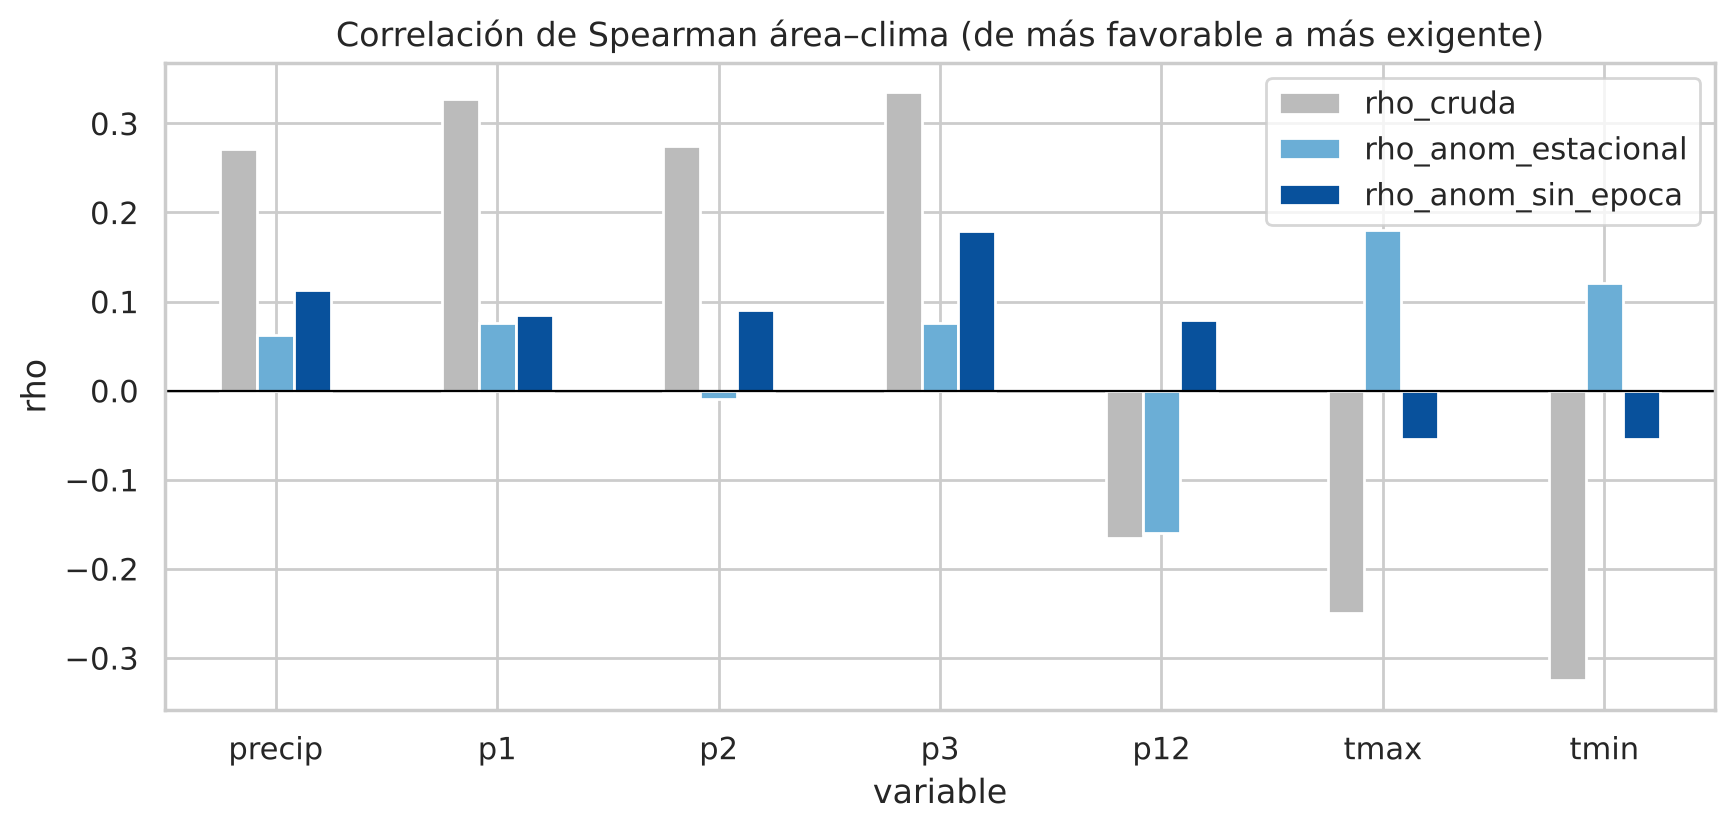

Mayor |rho| en la versión exigente: 0.18 → explica como máximo ≈ 3% de la variación (con 208 meses). Una correlación significativa pero tan baja no basta para predecir.


In [11]:
VARS_CORR = ["precip", "p1", "p2", "p3", "p12", "tmax", "tmin"]
clima_f = construir_features(df_clima)
clima_anom = clima_f[VARS_CORR].apply(anomalia_estacional)      # anomalías con TODA la historia de CR2MET (1979-2019)


def rho_par(a, b):
    par = pd.concat([a, b], axis=1).dropna()
    if len(par) < 10:
        return np.nan, np.nan, len(par)
    r, p = spearmanr(par.iloc[:, 0], par.iloc[:, 1])
    return r, p, len(par)


a_anom_est = anomalia_estacional(area)
filas = []
for v in VARS_CORR:
    r1, p1, n1 = rho_par(area, clima_f[v])
    r2, p2, n2 = rho_par(a_anom_est, clima_anom[v])
    r3, p3, n3 = rho_par(df_modelo["area_anom"], clima_anom[v])
    filas.append((v, r1, r2, r3, p3, n3, r3 ** 2))
tabla_corr = pd.DataFrame(filas, columns=["variable", "rho_cruda", "rho_anom_estacional", "rho_anom_sin_epoca",
                                          "p_anom_sin_epoca", "n", "R2_aprox"]).set_index("variable").round(3)
display(tabla_corr)

fig, ax = plt.subplots(figsize=(10, 4.2))
tabla_corr[["rho_cruda", "rho_anom_estacional", "rho_anom_sin_epoca"]].plot.bar(ax=ax, color=["#bbbbbb", "#6baed6", "#08519c"])
ax.axhline(0, color="black", lw=0.8)
ax.set(title="Correlación de Spearman área–clima (de más favorable a más exigente)", ylabel="rho")
plt.xticks(rotation=0)
plt.show()

RHO_MAX = tabla_corr["rho_anom_sin_epoca"].abs().max()
print(f"Mayor |rho| en la versión exigente: {RHO_MAX:.2f} → explica como máximo ≈ {RHO_MAX ** 2:.0%} de la variación "
      f"(con {int(tabla_corr['n'].max())} meses). Una correlación significativa pero tan baja no basta para predecir.")

## 7. Modelos de pronóstico con validación cruzada temporal (pregunta 5)

Se comparan modelos **clásicos** (referencias: media, climatología mensual, persistencia; regresión lineal regularizada Ridge) y de **ML** (Random Forest, XGBoost), cada uno con y sin clima, usando `TimeSeriesSplit` (siempre se entrena con el pasado). Métricas: RMSE y MAE en hectáreas, en bloques de prueba **fuera de la muestra**.

Se evalúan dos objetivos:

- **A. Nivel del área** (con la variable `epoca` para absorber el salto de sensor): lo que se necesita para proyectar.
- **B. Anomalía sin época ni estacionalidad**: aísla la señal del clima del salto de sensor.

La pregunta clave no es "¿qué modelo tiene menor error?", sino **¿algún modelo con clima le gana de forma clara a las referencias simples?** Si no, el pronóstico a largo plazo no tiene respaldo estadístico.

Como modelo estadístico clásico de series de tiempo se agrega **SARIMAX(1,0,0)** (ARIMA con regresores exógenos; maneja meses faltantes con el filtro de Kalman, sin imputar), con y sin clima, evaluado con los mismos pliegues. Se omiten Holt-Winters/ETS: no admiten huecos y la serie de área observada es irregular (meses faltantes, 2012 vacío); imputarla fue justamente lo que inflaba el desempeño anterior.

In [12]:
FEATS_BASE = ["mes_sin", "mes_cos", "epoca"]
FEATS_CLIMA = FEATS_BASE + ["precip", "p1", "p2", "p3", "tmax", "tmin"]
datos = df_modelo.loc[:FIN_CLIMA].dropna(subset=[COL_AREA] + FEATS_CLIMA).copy()
print(f"{len(datos)} meses con área observada y clima ({datos.index.min().date()} → {datos.index.max().date()})")

MODELOS = {
    "Ridge": make_pipeline(StandardScaler(), RidgeCV(alphas=[0.1, 1, 10, 50, 100])),
    "Random Forest": RandomForestRegressor(n_estimators=300, max_depth=6, min_samples_leaf=3,
                                           random_state=SEMILLA, n_jobs=-1),
}
if XGBRegressor is not None:
    MODELOS["XGBoost"] = XGBRegressor(n_estimators=300, learning_rate=0.03, max_depth=3, subsample=0.8,
                                      colsample_bytree=0.8, random_state=SEMILLA)


def evaluar_cv(datos, objetivo, feats_base, feats_extra, etiqueta_extra="+ clima"):
    """Validación cruzada temporal (ventana expansiva). Devuelve (tabla de métricas, RMSE por pliegue, predicciones del último pliegue)."""
    y = datos[objetivo]
    N = len(datos)
    test = 24 if N >= 150 else 12
    n_splits = int(min(5, (N // 2) // test))
    assert n_splits >= 2, f"Muestra insuficiente para validación temporal (N={N})"
    tscv = TimeSeriesSplit(n_splits=n_splits, test_size=test)

    pred = {
        "Media (referencia)": lambda tr, te: np.repeat(y.iloc[tr].mean(), len(te)),
        "Climatología mensual (referencia)": lambda tr, te: y.iloc[tr].groupby(y.index[tr].month).mean()
                                                .reindex(y.index[te].month).fillna(y.iloc[tr].mean()).values,
        "Persistencia: último valor observado (referencia)": lambda tr, te: np.repeat(y.iloc[tr].iloc[-1], len(te)),
    }
    for nombre, mod in MODELOS.items():
        for etiqueta, feats in (("estacionalidad", feats_base), (etiqueta_extra, feats_extra)):
            pred[f"{nombre} ({etiqueta})"] = (lambda tr, te, mod=mod, feats=feats:
                                              clone(mod).fit(datos[feats].iloc[tr], y.iloc[tr]).predict(datos[feats].iloc[te]))
    filas, por_pliegue, ultimo = {}, {}, {}
    for nombre, f in pred.items():
        rm, ma = [], []
        for tr, te in tscv.split(datos):
            p = np.asarray(f(tr, te))
            rm.append(np.sqrt(mean_squared_error(y.iloc[te], p)))
            ma.append(mean_absolute_error(y.iloc[te], p))
            ultimo[nombre] = (y.index[te], y.iloc[te].values, p)
        por_pliegue[nombre] = rm
        filas[nombre] = {"RMSE": np.mean(rm), "RMSE_std": np.std(rm), "MAE": np.mean(ma), "MAE_std": np.std(ma)}
    tabla = pd.DataFrame(filas).T.sort_values("RMSE")
    ref = tabla.loc["Climatología mensual (referencia)", "RMSE"]
    tabla["ganancia_vs_climatologia_%"] = (1 - tabla["RMSE"] / ref) * 100
    print(f"{n_splits} pliegues de {test} meses observados | objetivo: {objetivo}")
    return tabla.round(2), pd.DataFrame(por_pliegue), ultimo


def veredicto(tabla, sufijo="+ clima"):
    """¿El mejor modelo con clima supera a la mejor referencia por más que la variabilidad entre pliegues?"""
    refs = [i for i in tabla.index if "(referencia)" in i]
    con_clima = [i for i in tabla.index if sufijo in i]
    mejor_ref, mejor_cl = tabla.loc[refs, "RMSE"].idxmin(), tabla.loc[con_clima, "RMSE"].idxmin()
    ganancia = tabla.loc[mejor_ref, "RMSE"] - tabla.loc[mejor_cl, "RMSE"]
    ok = ganancia > tabla.loc[mejor_cl, "RMSE_std"]
    print(f"Mejor referencia: {mejor_ref} (RMSE {tabla.loc[mejor_ref, 'RMSE']:.2f} ha)")
    print(f"Mejor con {sufijo}: {mejor_cl} (RMSE {tabla.loc[mejor_cl, 'RMSE']:.2f} ± {tabla.loc[mejor_cl, 'RMSE_std']:.2f} ha)")
    print(f"Ganancia: {ganancia:+.2f} ha → " + ("supera a la referencia por más que la variabilidad entre pliegues."
          if ok else "NO supera claramente a la referencia (la diferencia está dentro del ruido entre pliegues)."))
    # Ablación: mismo modelo con y sin clima. Es la prueba más limpia de si el clima aporta algo.
    abl = pd.DataFrame({m: {"RMSE sin clima": tabla.loc[f"{m} (estacionalidad)", "RMSE"],
                            "RMSE con clima": tabla.loc[f"{m} ({sufijo})", "RMSE"]}
                        for m in MODELOS if f"{m} ({sufijo})" in tabla.index}).T
    abl["aporte_clima_ha"] = abl["RMSE sin clima"] - abl["RMSE con clima"]
    print(f"Aporte de las variables '{sufijo}' con el mismo modelo (positivo = mejora):")
    display(abl.round(2))
    return ok, mejor_cl


print("=== A. Nivel del área (con época de sensor) ===")
print("Ojo: en A la 'ganancia vs climatología' viene sobre todo de la variable `epoca` (salto de sensor), no del clima;")
print("el aporte del clima se lee en la tabla de ablación (mismo modelo con y sin clima).")
tabla_A, pliegues_A, ultimo_A = evaluar_cv(datos, COL_AREA, FEATS_BASE, FEATS_CLIMA)
display(tabla_A)
CLIMA_AYUDA_A, MEJOR_A = veredicto(tabla_A)

print("\n=== B. Anomalía sin época ni estacionalidad ===")
tabla_B, pliegues_B, ultimo_B = evaluar_cv(datos, "area_anom", ["mes_sin", "mes_cos"],
                                           ["mes_sin", "mes_cos", "precip", "p1", "p2", "p3", "tmax", "tmin"])
display(tabla_B)
CLIMA_AYUDA_B, MEJOR_B = veredicto(tabla_B)

208 meses con área observada y clima (1985-01-01 → 2019-12-01)
=== A. Nivel del área (con época de sensor) ===
Ojo: en A la 'ganancia vs climatología' viene sobre todo de la variable `epoca` (salto de sensor), no del clima;
el aporte del clima se lee en la tabla de ablación (mismo modelo con y sin clima).


4 pliegues de 24 meses observados | objetivo: area_hectareas


,RMSE,RMSE_std,MAE,MAE_std,ganancia_vs_climatologia_%
Ridge (+ clima),7.68,2.09,5.58,1.32,19.63
Ridge (estacionalidad),7.70,2.17,5.60,1.36,19.41
Persistencia: último valor observado (referencia),7.82,2.24,5.65,0.97,18.17
Random Forest (+ clima),7.92,1.99,5.53,1.28,17.15
Random Forest (estacionalidad),7.96,1.78,5.49,1.28,16.73
XGBoost (estacionalidad),8.06,1.67,5.59,1.23,15.63
XGBoost (+ clima),8.25,1.77,5.58,1.34,13.67
Media (referencia),9.38,0.37,7.27,1.79,1.82
Climatología mensual (referencia),9.56,0.59,7.55,1.37,0.00


Mejor referencia: Persistencia: último valor observado (referencia) (RMSE 7.82 ha)
Mejor con + clima: Ridge (+ clima) (RMSE 7.68 ± 2.09 ha)
Ganancia: +0.14 ha → NO supera claramente a la referencia (la diferencia está dentro del ruido entre pliegues).
Aporte de las variables '+ clima' con el mismo modelo (positivo = mejora):


,RMSE sin clima,RMSE con clima,aporte_clima_ha
Ridge,7.70,7.68,0.02
Random Forest,7.96,7.92,0.04
XGBoost,8.06,8.25,-0.19



=== B. Anomalía sin época ni estacionalidad ===


4 pliegues de 24 meses observados | objetivo: area_anom


,RMSE,RMSE_std,MAE,MAE_std,ganancia_vs_climatologia_%
Media (referencia),6.91,2.01,4.48,0.57,3.55
Ridge (estacionalidad),6.92,2.15,4.49,0.66,3.38
Ridge (+ clima),6.93,2.27,4.53,0.72,3.22
Random Forest (+ clima),7.13,2.09,4.73,0.71,0.50
Random Forest (estacionalidad),7.15,2.18,4.68,0.71,0.17
Climatología mensual (referencia),7.16,2.20,4.69,0.73,0.00
XGBoost (estacionalidad),7.20,2.18,4.75,0.72,-0.48
XGBoost (+ clima),7.40,1.88,4.84,0.45,-3.34
Persistencia: último valor observado (referencia),8.48,2.24,5.81,1.67,-18.42


Mejor referencia: Media (referencia) (RMSE 6.91 ha)
Mejor con + clima: Ridge (+ clima) (RMSE 6.93 ± 2.27 ha)
Ganancia: -0.02 ha → NO supera claramente a la referencia (la diferencia está dentro del ruido entre pliegues).
Aporte de las variables '+ clima' con el mismo modelo (positivo = mejora):


,RMSE sin clima,RMSE con clima,aporte_clima_ha
Ridge,6.92,6.93,-0.01
Random Forest,7.15,7.13,0.02
XGBoost,7.20,7.40,-0.20


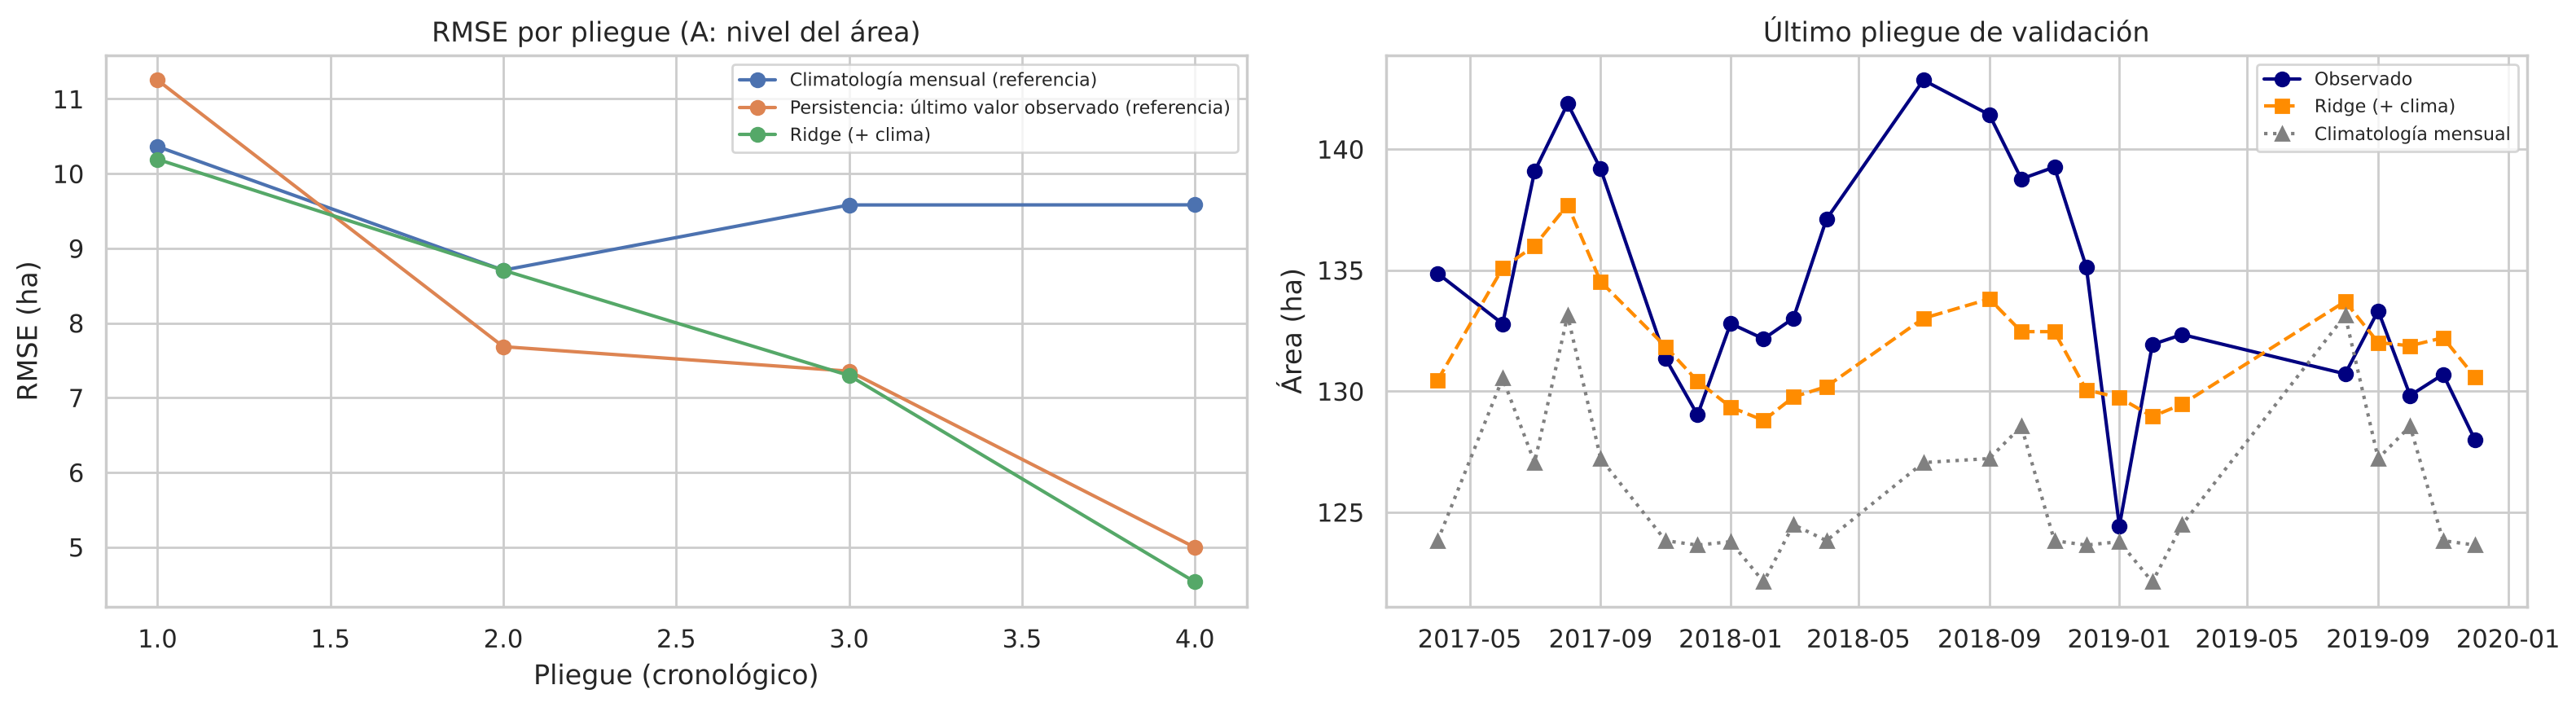

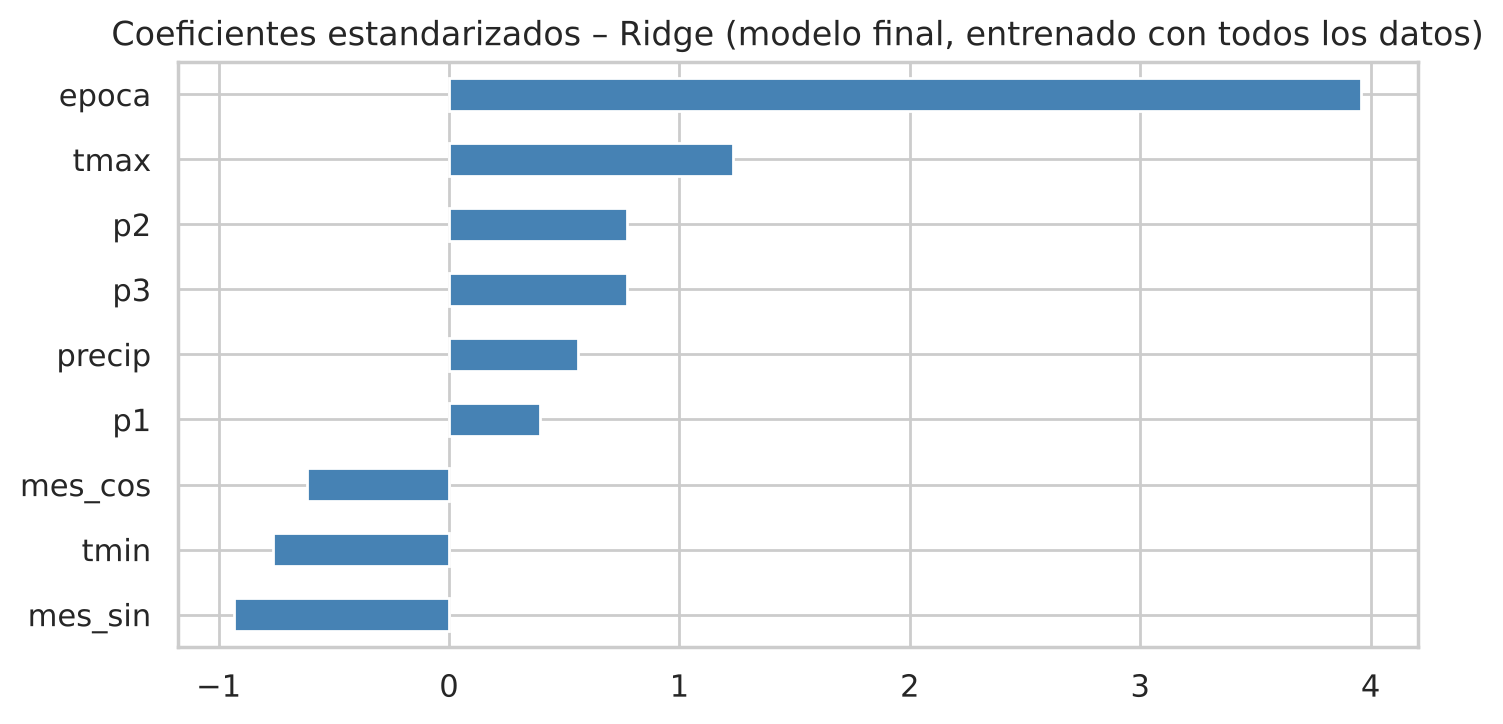

Modelo final: Ridge | RMSE de validación cruzada: 7.68 ha


In [13]:
# ---- Error por pliegue (¿es estable el resultado?) y último pliegue
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
seleccion = ["Climatología mensual (referencia)", "Persistencia: último valor observado (referencia)", MEJOR_A]
for nombre in seleccion:
    axes[0].plot(range(1, len(pliegues_A) + 1), pliegues_A[nombre], "o-", label=nombre)
axes[0].set(title="RMSE por pliegue (A: nivel del área)", xlabel="Pliegue (cronológico)", ylabel="RMSE (ha)")
axes[0].legend(fontsize=8)

fechas_u, real_u, pred_u = ultimo_A[MEJOR_A]
_, _, pred_clim = ultimo_A["Climatología mensual (referencia)"]
axes[1].plot(fechas_u, real_u, "o-", color="navy", label="Observado")
axes[1].plot(fechas_u, pred_u, "s--", color="darkorange", label=MEJOR_A)
axes[1].plot(fechas_u, pred_clim, "^:", color="gray", label="Climatología mensual")
axes[1].set(title="Último pliegue de validación", ylabel="Área (ha)")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

# ---- Modelo final (nivel del área, con clima) y qué variables usa
nombre_modelo = MEJOR_A.split(" (")[0]
FEATS_FINAL = FEATS_CLIMA
modelo_final = clone(MODELOS[nombre_modelo]).fit(datos[FEATS_FINAL], datos[COL_AREA])
RMSE_CV_FINAL = tabla_A.loc[MEJOR_A, "RMSE"]
estimador = modelo_final[-1] if hasattr(modelo_final, "steps") else modelo_final
if hasattr(estimador, "coef_"):
    imp, titulo = pd.Series(estimador.coef_, index=FEATS_FINAL), "Coeficientes estandarizados"
else:
    imp, titulo = pd.Series(estimador.feature_importances_, index=FEATS_FINAL), "Importancia de variables"
fig, ax = plt.subplots(figsize=(8, 3.8))
imp.sort_values().plot.barh(ax=ax, color="steelblue")
ax.set_title(f"{titulo} – {nombre_modelo} (modelo final, entrenado con todos los datos)")
plt.show()
print(f"Modelo final: {nombre_modelo} | RMSE de validación cruzada: {RMSE_CV_FINAL:.2f} ha")

### 7b. Modelo estadístico clásico: SARIMAX

Misma validación cruzada (mismos pliegues y mismo horizonte): se ajusta con el pasado y se pronostica todo el bloque de prueba **sin ver ningún dato de ese bloque**. Los regresores exógenos son los mismos que en Ridge/RF/XGBoost (estacionalidad + época, con o sin clima).

In [14]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
warnings.filterwarnings("ignore", module="statsmodels")   # avisos de frecuencia/convergencia, esperables con huecos

def cv_sarimax(datos, grid, exog_cols, order=(1, 0, 0)):
    """RMSE/MAE por pliegue de un SARIMAX ajustado sobre la grilla mensual completa (huecos = NaN, sin imputar)."""
    N = len(datos)
    test = 24 if N >= 150 else 12
    tscv = TimeSeriesSplit(n_splits=int(min(5, (N // 2) // test)), test_size=test)
    rm, ma = [], []
    for tr, te in tscv.split(datos):
        t0, t1 = datos.index[tr[-1]], datos.index[te[-1]]
        g = grid.loc[:t1]
        y = g[COL_AREA].copy()
        y[g.index > t0] = np.nan                                    # el bloque de prueba queda oculto
        ex = g[exog_cols].astype(float)
        ex = (ex - ex.loc[:t0].mean()) / ex.loc[:t0].std().replace(0, 1)
        res = SARIMAX(y, exog=ex, order=order, enforce_stationarity=False,
                      enforce_invertibility=False).fit(disp=False, maxiter=200)
        futuro = g.index > t0
        p = res.get_prediction(start=g.index[futuro][0], end=t1, exog=ex.loc[futuro]).predicted_mean
        p = p.reindex(datos.index[te]).values
        rm.append(np.sqrt(mean_squared_error(datos[COL_AREA].iloc[te], p)))
        ma.append(mean_absolute_error(datos[COL_AREA].iloc[te], p))
    return {"RMSE": np.mean(rm), "RMSE_std": np.std(rm), "MAE": np.mean(ma), "MAE_std": np.std(ma)}


grid_clima = df_modelo.loc[:FIN_CLIMA]
tabla_sarimax = pd.DataFrame({
    "SARIMAX(1,0,0) (estacionalidad)": cv_sarimax(datos, grid_clima, FEATS_BASE),
    "SARIMAX(1,0,0) (+ clima)": cv_sarimax(datos, grid_clima, FEATS_CLIMA),
}).T
ref = tabla_A.loc["Climatología mensual (referencia)", "RMSE"]
tabla_sarimax["ganancia_vs_climatologia_%"] = (1 - tabla_sarimax["RMSE"] / ref) * 100
display(tabla_sarimax.round(2))
mejor_nosarimax = tabla_A["RMSE"].min()
print(f"Mejor modelo de la tabla A: {tabla_A['RMSE'].idxmin()} (RMSE {mejor_nosarimax:.2f} ha). "
      f"SARIMAX: {tabla_sarimax['RMSE'].min():.2f} ha → "
      + ("no mejora a los demás." if tabla_sarimax["RMSE"].min() >= mejor_nosarimax - tabla_A.loc[tabla_A['RMSE'].idxmin(), 'RMSE_std']
         else "mejora de forma clara."))

,RMSE,RMSE_std,MAE,MAE_std,ganancia_vs_climatologia_%
"SARIMAX(1,0,0) (estacionalidad)",7.68,2.37,5.32,1.44,19.71
"SARIMAX(1,0,0) (+ clima)",7.84,2.50,5.57,1.62,17.98


Mejor modelo de la tabla A: Ridge (+ clima) (RMSE 7.68 ha). SARIMAX: 7.68 ha → no mejora a los demás.


## 8. Proyección 2025-2095 bajo RCP 2.6 y RCP 8.5 (pregunta 4)

Los archivos CR2 llegan hasta **2095** (no 2100). Se usa el **método delta por GCM**, emparejando por nombre:

- Temperatura: `clima = CR2MET(1986-2005) + (GCM escenario − GCM histórico 1986-2005)`.
- Precipitación: `clima = CR2MET(1986-2005) × (GCM escenario / GCM histórico 1986-2005)`, con cociente acotado en [0, 3] y piso de 1 mm en el denominador, para no generar lluvia negativa ni cocientes explosivos en meses secos. Los archivos de precipitación del CR2 están **normalizados** (promedio 1986-2005 = 100 en todos los GCM, no son mm); por eso se usa el cociente mes a mes y no se suman al clima observado.

Se añade una **corrida de control**: el mismo modelo con clima constante (climatología CR2MET 1986-2005). La diferencia entre cada escenario y el control es el **efecto del cambio climático según el modelo**, que es lo único atribuible al escenario. Con `epoca = 1` las proyecciones quedan en la escala de Landsat 8/9.

**Lectura honesta:** si la sección 7 no mostró que el clima mejora el pronóstico, la proyección debe leerse como un *análisis de sensibilidad* del modelo, no como una predicción con respaldo estadístico. La banda gris usa el RMSE de validación como orden de magnitud del error, no es un intervalo de predicción formal.

In [15]:
CLIM_BASE = df_clima.loc["1986":"2005"].groupby(df_clima.loc["1986":"2005"].index.month).mean()


def clima_gcm(gcm, escenario):
    """Clima mensual (precip, tmax, tmin) de un GCM bajo el método delta, desde DESDE_LAGS."""
    cols = {}
    for var in VARS_CLIMA:
        suf, df = SUFIJO_VAR[var], proy[var]
        ref = df[f"{gcm}_{suf} historical"].loc["1986":"2005"]
        ref_m = ref.groupby(ref.index.month).mean()
        ser = df[f"{gcm}_{suf} {escenario}"].loc[DESDE_LAGS:]
        m = ser.index.month
        base = CLIM_BASE[var].reindex(m).values
        if var == "precip":
            cociente = np.clip(ser.values / np.maximum(ref_m.reindex(m).values, 1.0), 0, 3)
            cols[var] = pd.Series(base * cociente, index=ser.index)
        else:
            cols[var] = pd.Series(base + (ser.values - ref_m.reindex(m).values), index=ser.index)
    return pd.DataFrame(cols)


def predecir(clima):
    X_fut = construir_features(clima).loc[INICIO_PROY:, FEATS_FINAL]
    return pd.Series(modelo_final.predict(X_fut), index=X_fut.index)


proy_mensual = {}
for esc in ("rcp26", "rcp85"):
    gcms = gcms_completos(esc)
    proy_mensual[esc] = pd.DataFrame({g: predecir(clima_gcm(g, esc)) for g in gcms})
    print(f"{esc.upper()}: {len(gcms)} GCMs proyectados")

# Control: clima constante = climatología CR2MET 1986-2005
idx = proy_mensual["rcp85"].index
idx_largo = pd.date_range(DESDE_LAGS, idx.max(), freq="MS")
clima_ctrl = pd.DataFrame({v: CLIM_BASE[v].reindex(idx_largo.month).values for v in VARS_CLIMA}, index=idx_largo)
control_mensual = predecir(clima_ctrl)

proy_anual = {esc: df.resample("YS").mean() for esc, df in proy_mensual.items()}
control_anual = control_mensual.resample("YS").mean()
ensamble = {esc: df.mean(axis=1) for esc, df in proy_anual.items()}

o_min, o_max = datos[COL_AREA].min(), datos[COL_AREA].max()
for esc, df in proy_mensual.items():
    fuera = ((df < o_min) | (df > o_max)).to_numpy().mean()
    print(f"{esc.upper()}: {fuera:.1%} de las predicciones mensuales caen fuera del rango observado ({o_min:.0f}–{o_max:.0f} ha)")

RCP26: 26 GCMs proyectados


RCP85: 39 GCMs proyectados
RCP26: 0.0% de las predicciones mensuales caen fuera del rango observado (83–146 ha)
RCP85: 0.0% de las predicciones mensuales caen fuera del rango observado (83–146 ha)


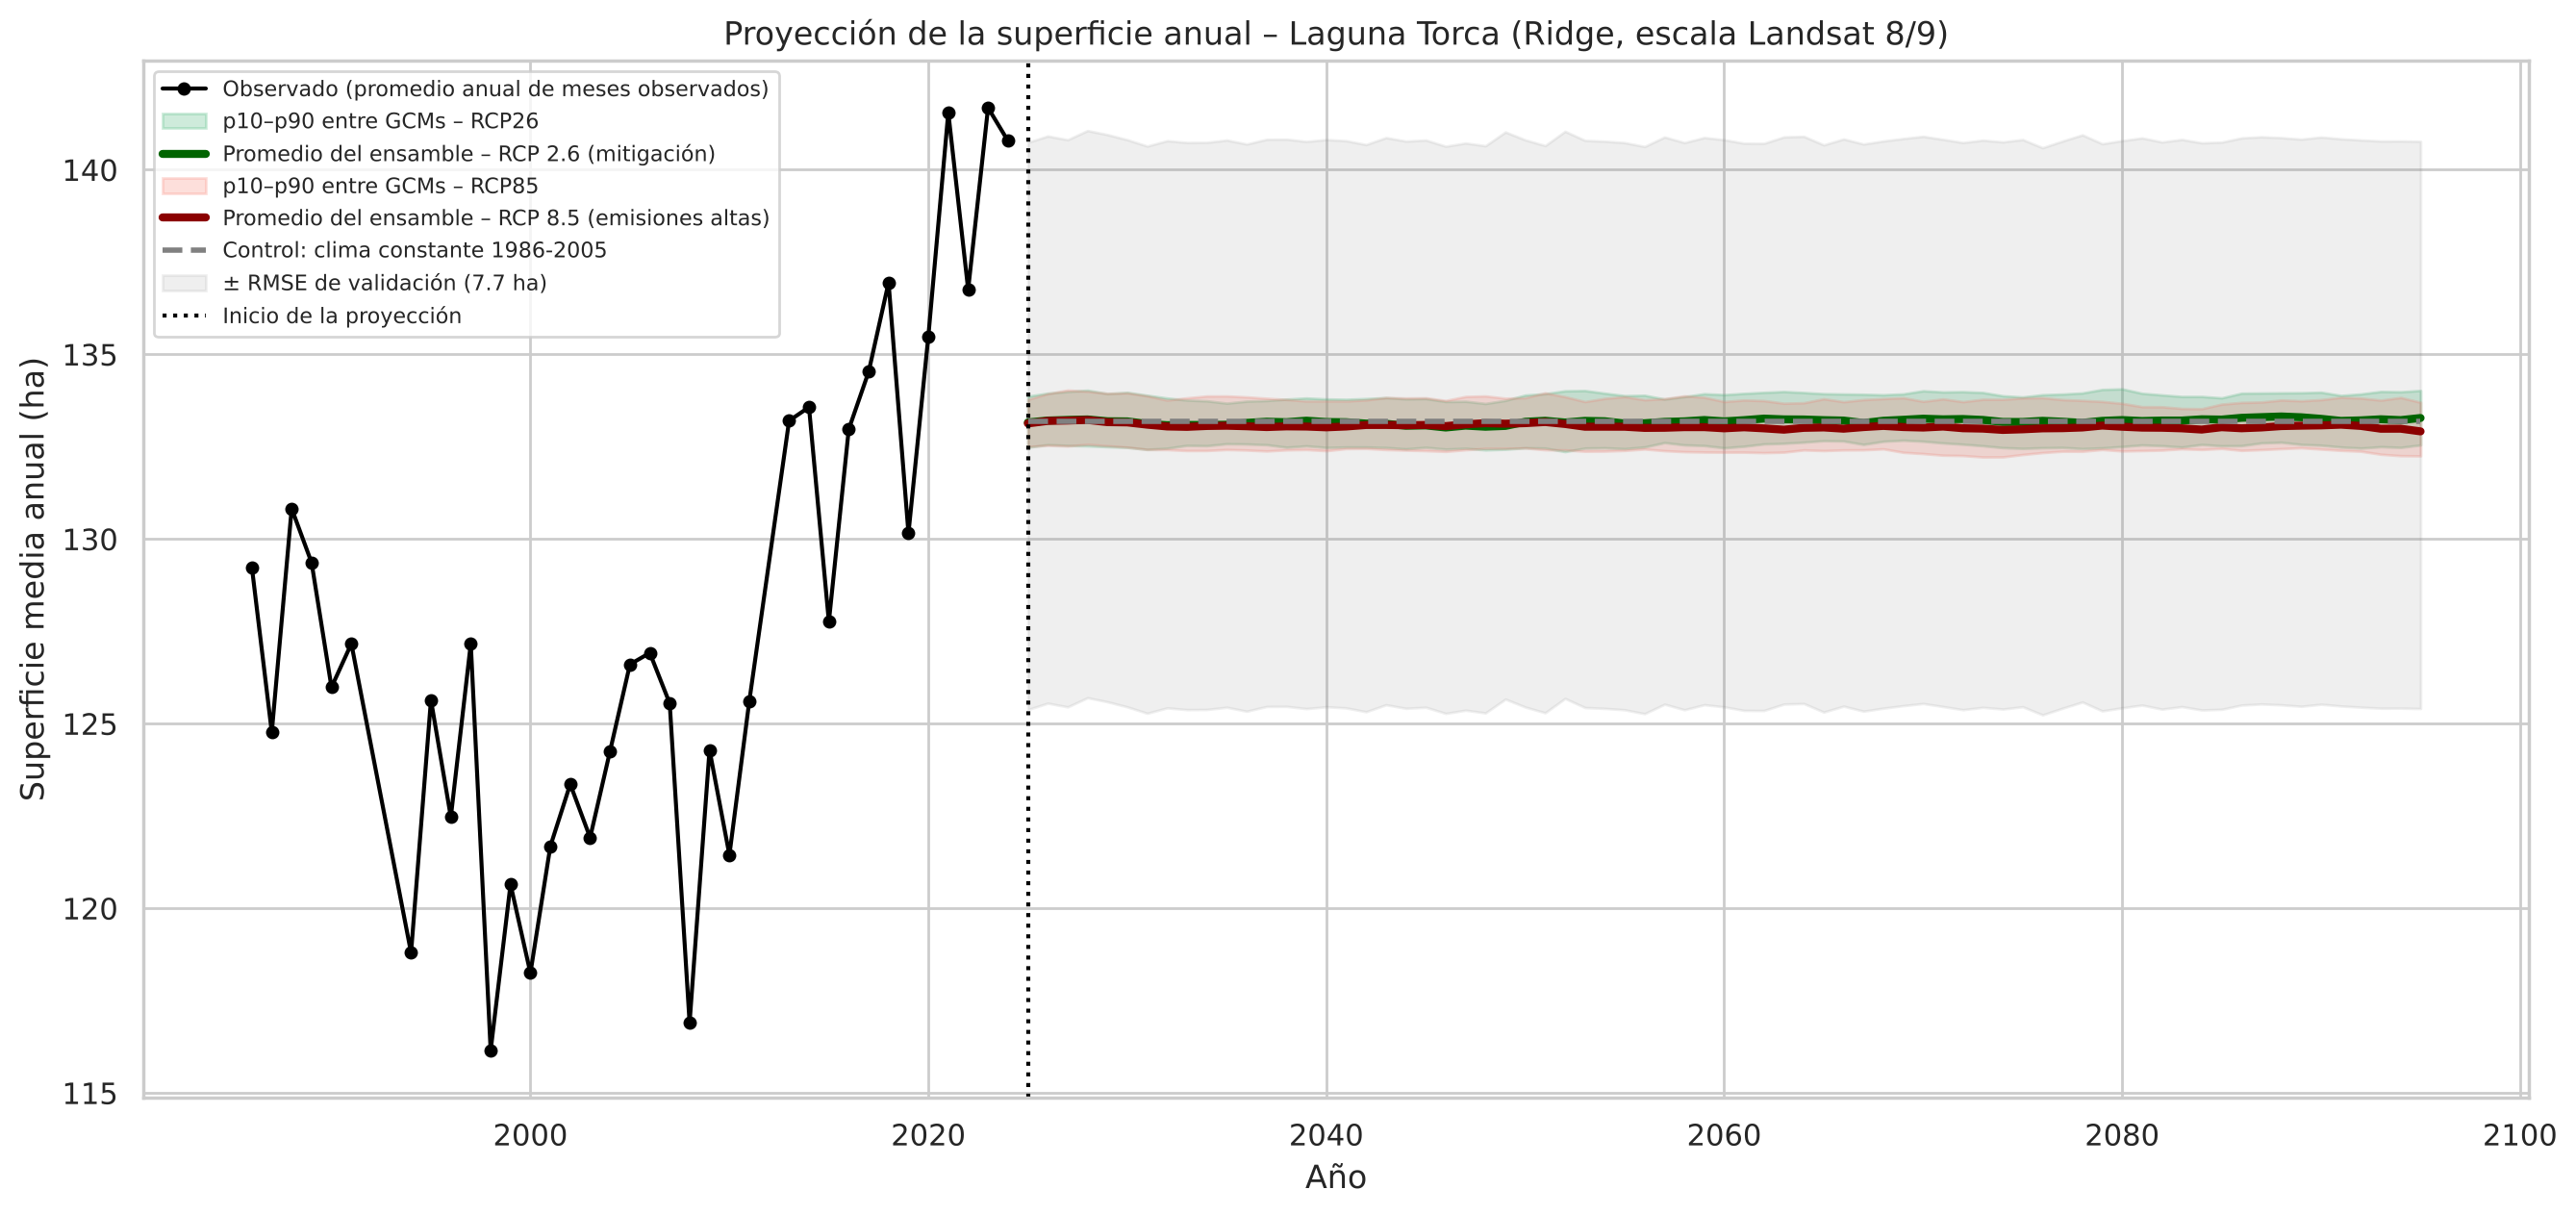

,escenario,horizonte,area_media_ha,p10_gcms,p90_gcms,efecto_vs_control_ha
0,RCP26,Corto plazo (2025-2040),133.16,132.85,133.36,-0.02
1,RCP26,Mediano plazo (2041-2070),133.16,132.97,133.39,-0.01
2,RCP26,Largo plazo (2071-2095),133.23,132.93,133.52,0.05
3,RCP85,Corto plazo (2025-2040),133.10,132.81,133.44,-0.08
4,RCP85,Mediano plazo (2041-2070),133.05,132.72,133.38,-0.12
5,RCP85,Largo plazo (2071-2095),133.01,132.67,133.45,-0.17


escenario,RCP26,RCP85,RCP85 - RCP26 (ha)
horizonte,,,
Corto plazo (2025-2040),133.16,133.10,-0.06
Largo plazo (2071-2095),133.23,133.01,-0.22
Mediano plazo (2041-2070),133.16,133.05,-0.11


Para dimensionar: RMSE de validación = 7.7 ha. Un efecto del escenario menor que ese error no es distinguible del ruido del modelo.

ADVERTENCIA: en la validación cruzada el clima no mejoró de forma clara sobre las referencias simples. Estas curvas son un análisis de sensibilidad del modelo, no una predicción con respaldo estadístico.


In [16]:
COLORES = {"rcp26": ("mediumseagreen", "darkgreen", "RCP 2.6 (mitigación)"),
           "rcp85": ("salmon", "darkred", "RCP 8.5 (emisiones altas)")}

fig, ax = plt.subplots(figsize=(16, 7))
hist = anual.loc[anual["meses_obs"] >= 3, "area_media_obs"]
ax.plot(pd.to_datetime(hist.index.astype(str)), hist.values, "o-", color="black", lw=1.5, ms=4,
        label="Observado (promedio anual de meses observados)")
for esc, (c_fino, c_grueso, etiqueta) in COLORES.items():
    q10, q90 = proy_anual[esc].quantile(0.1, axis=1), proy_anual[esc].quantile(0.9, axis=1)
    ax.fill_between(q10.index, q10.rolling(5, center=True, min_periods=1).mean(),
                    q90.rolling(5, center=True, min_periods=1).mean(), color=c_fino, alpha=0.25,
                    label=f"p10–p90 entre GCMs – {esc.upper()}")
    ax.plot(ensamble[esc].index, ensamble[esc].rolling(5, center=True, min_periods=1).mean(),
            color=c_grueso, lw=3, label=f"Promedio del ensamble – {etiqueta}")
ax.plot(control_anual.index, control_anual.values, color="gray", ls="--", lw=2, label="Control: clima constante 1986-2005")
ens_global = pd.concat(ensamble.values(), axis=1).mean(axis=1)
ax.fill_between(ens_global.index, ens_global - RMSE_CV_FINAL, ens_global + RMSE_CV_FINAL, color="gray", alpha=0.12,
                label=f"± RMSE de validación ({RMSE_CV_FINAL:.1f} ha)")
ax.axvline(pd.Timestamp(INICIO_PROY), color="black", ls=":", label="Inicio de la proyección")
ax.set(title=f"Proyección de la superficie anual – Laguna Torca ({nombre_modelo}, escala Landsat 8/9)",
       xlabel="Año", ylabel="Superficie media anual (ha)")
ax.legend(loc="best", fontsize=8)
plt.show()

# ---- Resumen por horizonte, con el efecto neto del escenario respecto del control
ULT = int(proy_anual["rcp85"].index.year.max())
HORIZONTES = {"Corto plazo (2025-2040)": ("2025", "2040"),
              "Mediano plazo (2041-2070)": ("2041", "2070"),
              f"Largo plazo (2071-{ULT})": ("2071", str(ULT))}
filas = []
for esc in ("rcp26", "rcp85"):
    for nombre, (a, b) in HORIZONTES.items():
        medias_gcm = proy_anual[esc].loc[a:b].mean()
        ctrl = control_anual.loc[a:b].mean()
        filas.append((esc.upper(), nombre, medias_gcm.mean(), medias_gcm.quantile(0.1), medias_gcm.quantile(0.9),
                      medias_gcm.mean() - ctrl))
resumen_proy = pd.DataFrame(filas, columns=["escenario", "horizonte", "area_media_ha", "p10_gcms", "p90_gcms",
                                            "efecto_vs_control_ha"]).round(2)
display(resumen_proy)

dif = resumen_proy.pivot(index="horizonte", columns="escenario", values="area_media_ha")
dif["RCP85 - RCP26 (ha)"] = dif["RCP85"] - dif["RCP26"]
display(dif.round(2))
print(f"Para dimensionar: RMSE de validación = {RMSE_CV_FINAL:.1f} ha. Un efecto del escenario menor que ese error "
      "no es distinguible del ruido del modelo.")

AYUDA_CLIMA = CLIMA_AYUDA_A or CLIMA_AYUDA_B
if not AYUDA_CLIMA:
    print("\nADVERTENCIA: en la validación cruzada el clima no mejoró de forma clara sobre las referencias simples. "
          "Estas curvas son un análisis de sensibilidad del modelo, no una predicción con respaldo estadístico.")

## 9. Comparación: modelo con datos observados vs modelo con imputación MICE

Se comparan los enfoques con **las mismas reglas de evaluación**:

| Enfoque | Cómo se arma el entrenamiento |
|---|---|
| **Observado (sin imputar)** | Solo los meses con área medida por el satélite (lo que se hizo hasta aquí). |
| **MICE sin clima** | Los meses sin escena se imputan con MICE usando solo tiempo, estacionalidad y época de sensor. |
| **MICE con clima** | Igual, pero el clima también entra al imputador (como en el notebook original). |
| **MICE con clima + Savitzky-Golay** | Lo anterior más suavizado (13 meses, grado 3), como en el original. |
| **Pipeline original (MICE+SG global)** | Se imputa y suaviza **toda la serie de una vez**, como en el original, con información futura en el entrenamiento. |

Reglas para que la comparación sea justa:

- **La imputación se ajusta dentro de cada pliegue**, solo con meses anteriores al bloque de prueba (el imputador nunca ve el futuro). La excepción es el último enfoque, que replica el original a propósito.
- **Se prueba siempre contra los mismos meses observados** de cada bloque. Imputar da más filas de entrenamiento, pero no se puede evaluar contra valores imputados: serían inventados por el propio método.
- En el pipeline original se muestra además el error medido **contra su propia serie suavizada**, que es lo que hacía parecer buenas las predicciones.

Observación técnica: como solo la columna de área tiene huecos, MICE equivale aquí a una regresión (Random Forest) del área sobre las demás columnas. Esto se verifica abajo con el diagnóstico de circularidad.

In [17]:
COLS_MICE = {"MICE sin clima": [COL_AREA, "t", "mes_sin", "mes_cos", "epoca"],
             "MICE con clima": [COL_AREA, "t", "mes_sin", "mes_cos", "epoca", "precip", "p1", "p2", "p3", "tmax", "tmin"]}
VARS_CMP = {"solo estacionalidad": FEATS_BASE, "con clima": FEATS_CLIMA}
ENFOQUE_OBS = "Observado (sin imputar)"
ENFOQUE_M0 = "Pipeline original (MICE+SG global)"

base_mice = df_modelo.loc[:FIN_CLIMA, [COL_AREA] + FEATS_CLIMA].copy()
base_mice["t"] = base_mice.index.year + (base_mice.index.month - 1) / 12


def imputar_mice(df, columnas):
    """Imputa el área con MICE (Random Forest) usando SOLO las filas de `df`. Devuelve la serie de área completa."""
    imputador = IterativeImputer(
        estimator=RandomForestRegressor(n_estimators=100, min_samples_leaf=2, random_state=SEMILLA, n_jobs=-1),
        max_iter=10, random_state=SEMILLA, min_value=np.array([0.0] + [-np.inf] * (len(columnas) - 1)))
    out = pd.DataFrame(imputador.fit_transform(df[columnas]), columns=columnas, index=df.index)
    return out[COL_AREA]


def suavizar(serie):
    return pd.Series(savgol_filter(serie.values, 13, 3), index=serie.index)


# Pipeline original: toda la serie imputada con clima y suavizada una sola vez
area_m2_full = imputar_mice(base_mice, COLS_MICE["MICE con clima"])
area_m0_sg = suavizar(area_m2_full)
area_m1_full = imputar_mice(base_mice, COLS_MICE["MICE sin clima"])

# Mismos pliegues que la sección 7 (por observaciones), para que sean comparables
N_C = len(datos)
TEST_C = 24 if N_C >= 150 else 12
tscv_c = TimeSeriesSplit(n_splits=int(min(5, (N_C // 2) // TEST_C)), test_size=TEST_C)

registros = []


def registrar(enfoque, modelo, variables, pliegue, y_real, pred, propio=None):
    fila = {"enfoque": enfoque, "modelo": modelo, "variables": variables, "pliegue": pliegue,
            "rmse": np.sqrt(mean_squared_error(y_real, pred)), "mae": mean_absolute_error(y_real, pred)}
    if propio is not None:
        fila["rmse_vs_serie_propia"] = np.sqrt(mean_squared_error(*propio))
    registros.append(fila)


for k, (tr, te) in enumerate(tscv_c.split(datos), 1):
    f_te = datos.index[te]
    corte, fin = f_te[0], f_te[-1]
    y_te = datos[COL_AREA].iloc[te]
    train_df = base_mice[base_mice.index < corte]          # todos los meses anteriores al bloque de prueba

    conjuntos = {ENFOQUE_OBS: (datos.iloc[tr], datos[COL_AREA].iloc[tr])}
    for nombre_m, cols in COLS_MICE.items():
        a_imp = imputar_mice(train_df, cols)                # imputación SOLO con el pasado
        conjuntos[nombre_m] = (train_df, a_imp)
        if nombre_m == "MICE con clima":
            conjuntos["MICE con clima + Savitzky-Golay"] = (train_df, suavizar(a_imp))
    for enfoque, (X_tr, y_tr) in conjuntos.items():
        for vlabel, feats in VARS_CMP.items():
            for nombre, mod in MODELOS.items():
                pred = clone(mod).fit(X_tr[feats], y_tr).predict(datos[feats].iloc[te])
                registrar(enfoque, nombre, vlabel, k, y_te, pred)

    tr_m = base_mice.index < corte
    te_m = (base_mice.index >= corte) & (base_mice.index <= fin)
    for vlabel, feats in VARS_CMP.items():
        for nombre, mod in MODELOS.items():
            m0 = clone(mod).fit(base_mice.loc[tr_m, feats], area_m0_sg[tr_m])
            p_all = pd.Series(m0.predict(base_mice.loc[te_m, feats]), index=base_mice.index[te_m])
            registrar(ENFOQUE_M0, nombre, vlabel, k, y_te, p_all.reindex(f_te).values,
                      propio=(area_m0_sg[te_m].values, p_all.values))

res = pd.DataFrame(registros)
tabla_cmp = (res.groupby(["enfoque", "variables", "modelo"])
             .agg(RMSE=("rmse", "mean"), RMSE_std=("rmse", lambda x: np.std(x)),
                  MAE=("mae", "mean"), MAE_std=("mae", lambda x: np.std(x)),
                  RMSE_vs_serie_propia=("rmse_vs_serie_propia", "mean"))
             .sort_values("RMSE").round(2))
print(f"{tscv_c.get_n_splits()} pliegues de {TEST_C} meses observados | error SIEMPRE contra el área observada por el satélite")
display(tabla_cmp)

mejores = tabla_cmp.reset_index().sort_values("RMSE").groupby("enfoque", sort=False).head(1).set_index("enfoque")
print("\nMejor combinación de cada enfoque:")
display(mejores[["variables", "modelo", "RMSE", "RMSE_std", "MAE"]])
refs = tabla_A.loc[[i for i in tabla_A.index if "(referencia)" in i], ["RMSE", "RMSE_std", "MAE"]]
print("Referencias simples (sección 7, mismos pliegues):")
display(refs)

4 pliegues de 24 meses observados | error SIEMPRE contra el área observada por el satélite


RMSE  \
enfoque                            variables           modelo                
Pipeline original (MICE+SG global) con clima           Ridge          7.44   
                                   solo estacionalidad Ridge          7.47   
MICE con clima + Savitzky-Golay    con clima           Ridge          7.51   
                                   solo estacionalidad Ridge          7.53   
Pipeline original (MICE+SG global) solo estacionalidad XGBoost        7.59   
                                                       Random Forest  7.60   
MICE con clima + Savitzky-Golay    solo estacionalidad XGBoost        7.66   
                                                       Random Forest  7.67   
Observado (sin imputar)            con clima           Ridge          7.68   
MICE con clima                     solo estacionalidad Ridge          7.68   
Observado (sin imputar)            solo estacionalidad Ridge          7.70   
MICE con clima                     con clima           Ridge          7.72   
Pipeline original (MICE+SG global) con clima           Random Forest  7.74   
MICE sin clima                     con clima           Ridge          7.79   
MICE con clima + Savitzky-Golay    con clima           Random Forest  7.80   
Pipeline original (MICE+SG global) con clima           XGBoost        7.83   
MICE sin clima                     solo estacionalidad Ridge          7.85   
MICE con clima                     solo estacionalidad Random Forest  7.85   
                                                       XGBoost        7.88   
Observado (sin imputar)            con clima           Random Forest  7.92   
MICE con clima + Savitzky-Golay    con clima           XGBoost        7.92   
MICE con clima                     con clima           Random Forest  7.95   
Observado (sin imputar)            solo estacionalidad Random Forest  7.96   
                                                       XGBoost        8.06   
MICE sin clima                     solo estacionalidad XGBoost        8.11   
                                                       Random Forest  8.13   
MICE con clima                     con clima           XGBoost        8.15   
Observado (sin imputar)            con clima           XGBoost        8.25   
MICE sin clima                     con clima           Random Forest  8.27   
                                                       XGBoost        8.30   

                                                                      RMSE_std  \
enfoque                            variables           modelo                    
Pipeline original (MICE+SG global) con clima           Ridge              1.92   
                                   solo estacionalidad Ridge              1.99   
MICE con clima + Savitzky-Golay    con clima           Ridge              1.91   
                                   solo estacionalidad Ridge              1.97   
Pipeline original (MICE+SG global) solo estacionalidad XGBoost            1.87   
                                                       Random Forest      1.87   
MICE con clima + Savitzky-Golay    solo estacionalidad XGBoost            1.83   
                                                       Random Forest      1.83   
Observado (sin imputar)            con clima           Ridge              2.09   
MICE con clima                     solo estacionalidad Ridge              2.10   
Observado (sin imputar)            solo estacionalidad Ridge              2.17   
MICE con clima                     con clima           Ridge              2.07   
Pipeline original (MICE+SG global) con clima           Random Forest      1.92   
MICE sin clima                     con clima           Ridge              2.20   
MICE con clima + Savitzky-Golay    con clima           Random Forest      1.87   
Pipeline original (MICE+SG global) con clima           XGBoost            1.85   
MICE sin clima                     solo estacionalidad Ridge              2.23   
MICE con clima 


Mejor combinación de cada enfoque:


,variables,modelo,RMSE,RMSE_std,MAE
enfoque,,,,,
Pipeline original (MICE+SG global),con clima,Ridge,7.44,1.92,5.26
MICE con clima + Savitzky-Golay,con clima,Ridge,7.51,1.91,5.32
Observado (sin imputar),con clima,Ridge,7.68,2.09,5.58
MICE con clima,solo estacionalidad,Ridge,7.68,2.10,5.62
MICE sin clima,con clima,Ridge,7.79,2.20,5.68


Referencias simples (sección 7, mismos pliegues):


,RMSE,RMSE_std,MAE
Persistencia: último valor observado (referencia),7.82,2.24,5.65
Media (referencia),9.38,0.37,7.27
Climatología mensual (referencia),9.56,0.59,7.55


Referencia: Observado (sin imputar) → Ridge (con clima), RMSE 7.68 ± 2.09 ha



,modelo,variables,RMSE,dif_vs_observado_ha,juicio
enfoque,,,,,
Pipeline original (MICE+SG global),Ridge,con clima,7.44,-0.24,equivalente (dentro del ruido entre pliegues)
MICE con clima + Savitzky-Golay,Ridge,con clima,7.51,-0.17,equivalente (dentro del ruido entre pliegues)
MICE con clima,Ridge,solo estacionalidad,7.68,0.00,equivalente (dentro del ruido entre pliegues)
MICE sin clima,Ridge,con clima,7.79,0.11,equivalente (dentro del ruido entre pliegues)



Pipeline original (Ridge, con clima): RMSE contra SU PROPIA serie suavizada = 4.13 ha, contra el área realmente observada = 7.44 ha (el error 'aparente' es 1.8 veces menor que el real).


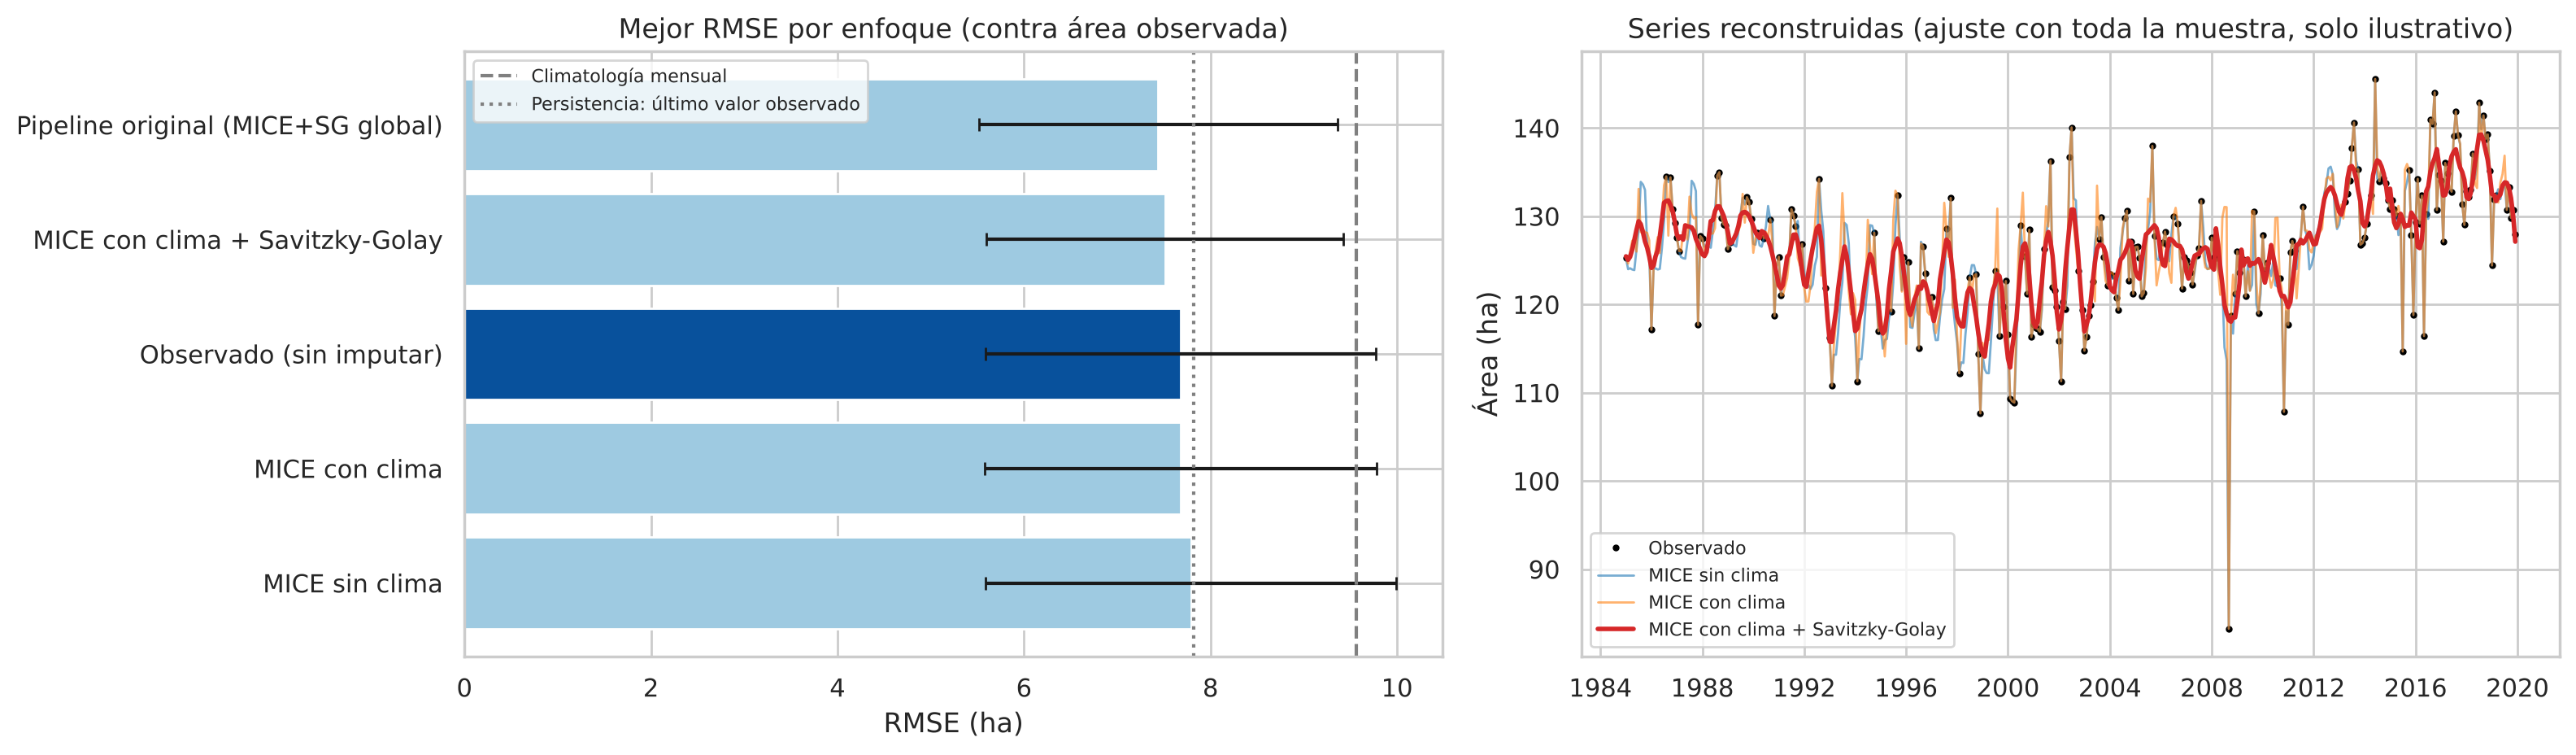

In [18]:
# ---- Veredicto: ¿imputar mejora el pronóstico sobre lo observado?
ref = mejores.loc[ENFOQUE_OBS]
print(f"Referencia: {ENFOQUE_OBS} → {ref['modelo']} ({ref['variables']}), RMSE {ref['RMSE']:.2f} ± {ref['RMSE_std']:.2f} ha\n")
filas = []
for enfoque, fila in mejores.iterrows():
    if enfoque == ENFOQUE_OBS:
        continue
    dif = fila["RMSE"] - ref["RMSE"]
    if abs(dif) <= ref["RMSE_std"]:
        juicio = "equivalente (dentro del ruido entre pliegues)"
    else:
        juicio = "MEJOR que observado" if dif < 0 else "PEOR que observado"
    filas.append((enfoque, fila["modelo"], fila["variables"], fila["RMSE"], dif, juicio))
veredicto_cmp = pd.DataFrame(filas, columns=["enfoque", "modelo", "variables", "RMSE", "dif_vs_observado_ha", "juicio"]).set_index("enfoque").round(2)
display(veredicto_cmp)

# ---- Cuánto se infla el error si se evalúa contra la serie imputada y suavizada (lo que hacía el original)
m0 = tabla_cmp.loc[ENFOQUE_M0].reset_index().sort_values("RMSE").iloc[0]
print(f"\nPipeline original ({m0['modelo']}, {m0['variables']}): "
      f"RMSE contra SU PROPIA serie suavizada = {m0['RMSE_vs_serie_propia']:.2f} ha, "
      f"contra el área realmente observada = {m0['RMSE']:.2f} ha "
      f"(el error 'aparente' es {m0['RMSE'] / max(m0['RMSE_vs_serie_propia'], 1e-9):.1f} veces menor que el real).")

fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
orden = mejores.sort_values("RMSE")
colores = ["#08519c" if e == ENFOQUE_OBS else "#9ecae1" for e in orden.index]
axes[0].barh(orden.index, orden["RMSE"], xerr=orden["RMSE_std"], color=colores, capsize=3)
for nombre, estilo in (("Climatología mensual (referencia)", "--"), ("Persistencia: último valor observado (referencia)", ":")):
    axes[0].axvline(refs.loc[nombre, "RMSE"], color="gray", ls=estilo, label=nombre.replace(" (referencia)", ""))
axes[0].set(title="Mejor RMSE por enfoque (contra área observada)", xlabel="RMSE (ha)")
axes[0].legend(fontsize=8)
axes[0].invert_yaxis()

axes[1].plot(base_mice.index, base_mice[COL_AREA], ".", color="black", ms=4, label="Observado")
axes[1].plot(area_m1_full.index, area_m1_full, color="tab:blue", alpha=0.6, lw=1, label="MICE sin clima")
axes[1].plot(area_m2_full.index, area_m2_full, color="tab:orange", alpha=0.6, lw=1, label="MICE con clima")
axes[1].plot(area_m0_sg.index, area_m0_sg, color="tab:red", lw=2, label="MICE con clima + Savitzky-Golay")
axes[1].set(title="Series reconstruidas (ajuste con toda la muestra, solo ilustrativo)", ylabel="Área (ha)")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

In [19]:
# ---- Diagnóstico de circularidad: ¿la serie imputada "descubre" una relación con el clima que el satélite no ve?
es_obs = base_mice[COL_AREA].notna()
filas = []
for nombre, serie in (("Observado", base_mice[COL_AREA]), ("MICE sin clima", area_m1_full), ("MICE con clima", area_m2_full)):
    anom = anomalia_sin_epoca(serie)
    p3_anom = clima_anom["p3"].reindex(anom.index)
    for etiqueta, mascara in (("meses observados", es_obs), ("meses imputados", ~es_obs)):
        if nombre == "Observado" and etiqueta == "meses imputados":
            continue
        r, p, n = rho_par(anom[mascara], p3_anom[mascara])
        filas.append((nombre, etiqueta, r, p, n))
circ = pd.DataFrame(filas, columns=["serie", "subconjunto", "rho_con_precip_3m", "p", "n"]).round(3)
display(circ)
print("Si 'MICE con clima' muestra una correlación mucho mayor en los meses imputados que en los observados, esa relación "
      "la puso el imputador, no el satélite: usarla para entrenar es circular.")

,serie,subconjunto,rho_con_precip_3m,p,n
0,Observado,meses observados,0.168,0.016,208
1,MICE sin clima,meses observados,0.177,0.010,208
2,MICE sin clima,meses imputados,-0.043,0.532,212
3,MICE con clima,meses observados,0.155,0.026,208
4,MICE con clima,meses imputados,0.209,0.002,212


Si 'MICE con clima' muestra una correlación mucho mayor en los meses imputados que en los observados, esa relación la puso el imputador, no el satélite: usarla para entrenar es circular.


,enfoque,horizonte,RCP26_ha,RCP85_ha,RCP85_menos_RCP26_ha,efecto_RCP85_vs_control_ha
0,Observado (sin imputar),Corto plazo (2025-2040),133.16,133.10,-0.06,-0.08
1,Observado (sin imputar),Mediano plazo (2041-2070),133.16,133.05,-0.11,-0.12
2,Observado (sin imputar),Largo plazo (2071-2095),133.23,133.01,-0.22,-0.17
3,MICE sin clima,Corto plazo (2025-2040),132.83,132.83,0.00,0.08
4,MICE sin clima,Mediano plazo (2041-2070),132.85,132.92,0.07,0.17
5,MICE sin clima,Largo plazo (2071-2095),132.87,133.05,0.18,0.30
6,MICE con clima,Corto plazo (2025-2040),133.00,132.92,-0.08,-0.22
7,MICE con clima,Mediano plazo (2041-2070),132.98,132.72,-0.26,-0.42
8,MICE con clima,Largo plazo (2071-2095),133.02,132.46,-0.56,-0.68
9,MICE con clima + Savitzky-Golay,Corto plazo (2025-2040),132.83,132.80,-0.03,-0.08


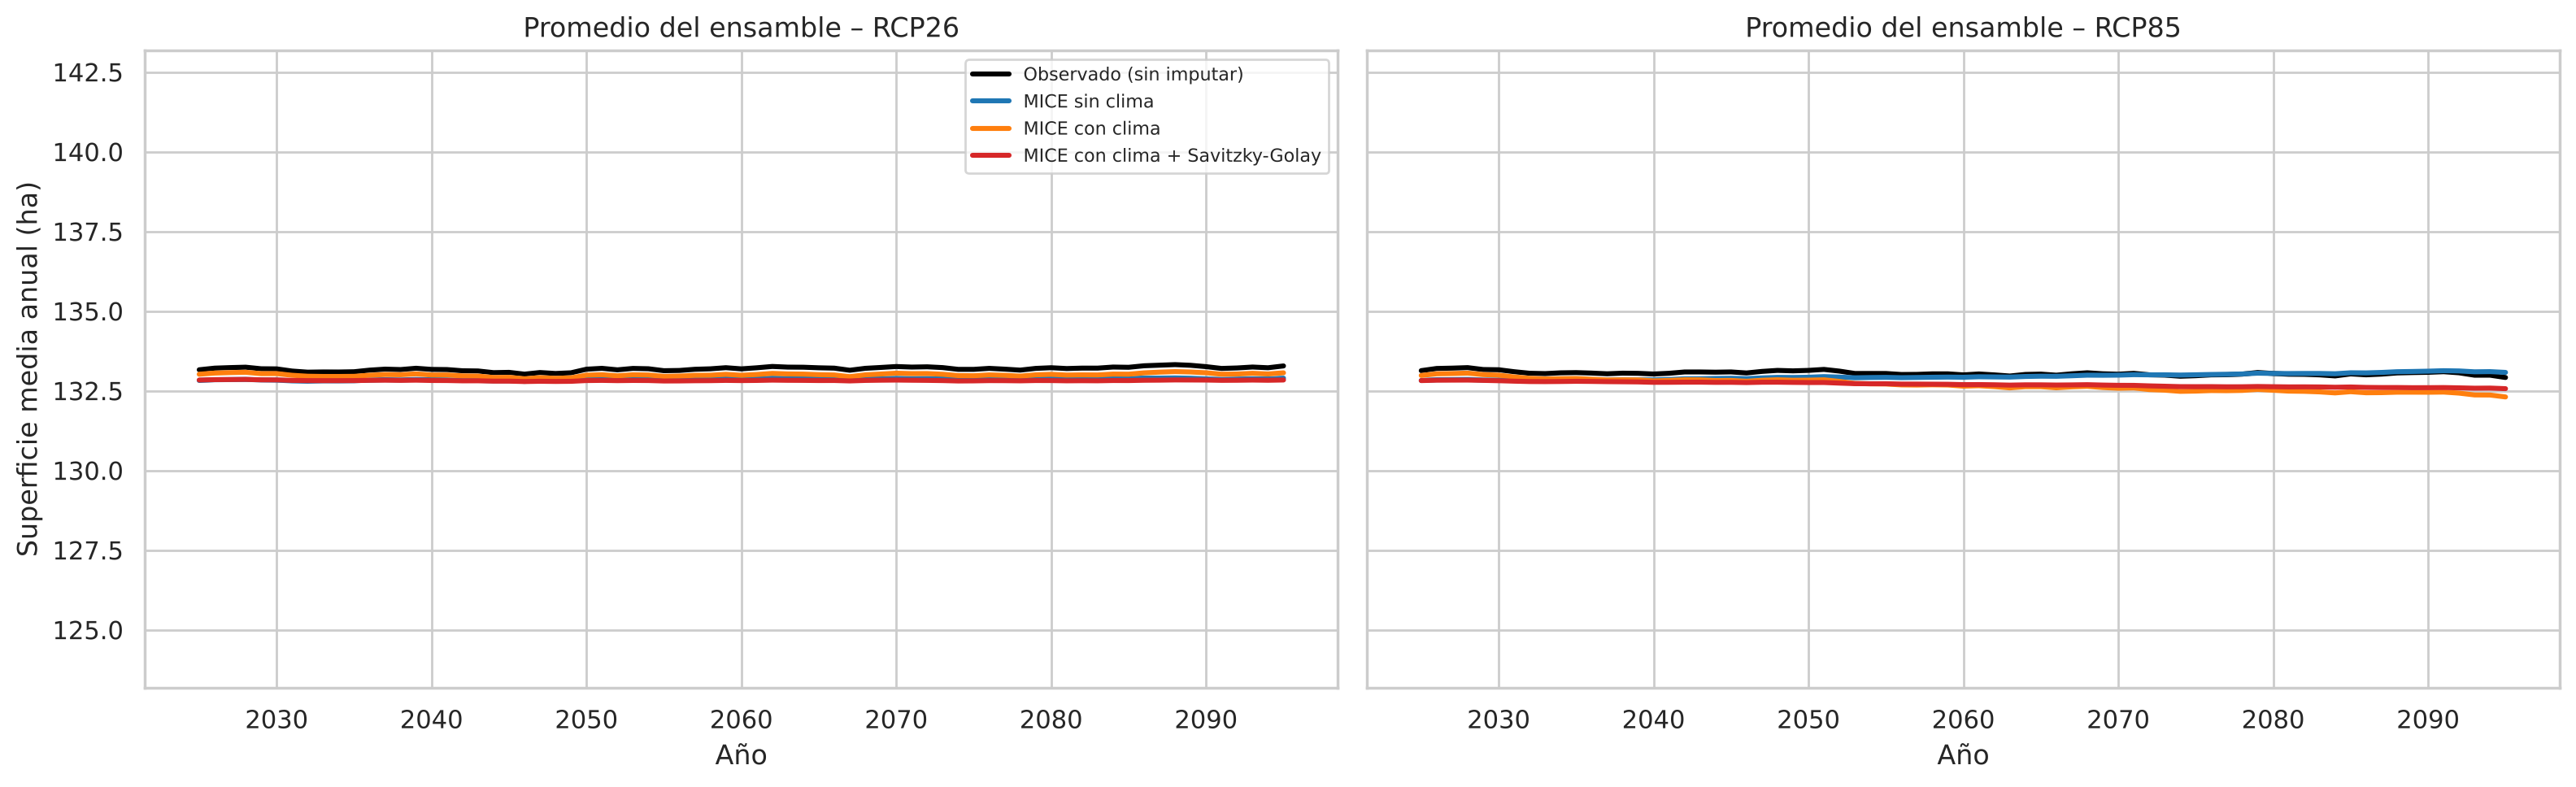

Para dimensionar: el error de validación del mejor modelo observado es 7.7 ha. Una diferencia entre escenarios mayor en los enfoques MICE no es evidencia de más información: si MICE con clima la amplifica, es el artefacto circular del diagnóstico anterior.


In [20]:
# ---- ¿Cambian las proyecciones? Mismo modelo final (con clima) entrenado con cada versión de la serie
def predecir_con(modelo, clima):
    X_fut = construir_features(clima).loc[INICIO_PROY:, FEATS_FINAL]
    return pd.Series(modelo.predict(X_fut), index=X_fut.index)


modelos_finales = {ENFOQUE_OBS: modelo_final,
                   "MICE sin clima": clone(MODELOS[nombre_modelo]).fit(base_mice[FEATS_FINAL], area_m1_full),
                   "MICE con clima": clone(MODELOS[nombre_modelo]).fit(base_mice[FEATS_FINAL], area_m2_full),
                   "MICE con clima + Savitzky-Golay": clone(MODELOS[nombre_modelo]).fit(base_mice[FEATS_FINAL], area_m0_sg)}

proy_cmp, ctrl_cmp = {}, {}
for enfoque, mod in modelos_finales.items():
    anual_e = {}
    for esc in ("rcp26", "rcp85"):
        pm = pd.DataFrame({g: predecir_con(mod, clima_gcm(g, esc)) for g in gcms_completos(esc)})
        anual_e[esc] = pm.resample("YS").mean()
    proy_cmp[enfoque] = anual_e
    ctrl_cmp[enfoque] = predecir_con(mod, clima_ctrl).resample("YS").mean()

filas = []
for enfoque in modelos_finales:
    for nombre_h, (a, b) in HORIZONTES.items():
        m26 = proy_cmp[enfoque]["rcp26"].loc[a:b].mean().mean()
        m85 = proy_cmp[enfoque]["rcp85"].loc[a:b].mean().mean()
        ctrl = ctrl_cmp[enfoque].loc[a:b].mean()
        filas.append((enfoque, nombre_h, m26, m85, m85 - m26, m85 - ctrl))
tabla_proy_cmp = pd.DataFrame(filas, columns=["enfoque", "horizonte", "RCP26_ha", "RCP85_ha", "RCP85_menos_RCP26_ha",
                                              "efecto_RCP85_vs_control_ha"]).round(2)
display(tabla_proy_cmp)

fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)
paleta = {ENFOQUE_OBS: "black", "MICE sin clima": "tab:blue", "MICE con clima": "tab:orange",
          "MICE con clima + Savitzky-Golay": "tab:red"}
for ax, esc in zip(axes, ("rcp26", "rcp85")):
    for enfoque in modelos_finales:
        ax.plot(proy_cmp[enfoque][esc].mean(axis=1).rolling(5, center=True, min_periods=1).mean(),
                color=paleta[enfoque], lw=2.2, label=enfoque)
    ax.set(title=f"Promedio del ensamble – {esc.upper()}", xlabel="Año")
axes[0].set_ylabel("Superficie media anual (ha)")
centro = float(ctrl_cmp[ENFOQUE_OBS].mean())
axes[0].set_ylim(centro - 10, centro + 10)      # escala fija (±10 ha): sin esto el eje se ajusta a diferencias de décimas de ha
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()
print(f"Para dimensionar: el error de validación del mejor modelo observado es {ref['RMSE']:.1f} ha. "
      "Una diferencia entre escenarios mayor en los enfoques MICE no es evidencia de más información: "
      "si MICE con clima la amplifica, es el artefacto circular del diagnóstico anterior.")

## 10. Modelo anual con MICE (el modelo del notebook original)

Este es el modelo que muestra diferencia entre escenarios: una **regresión lineal anual** del área (serie MICE + Savitzky-Golay) sobre la precipitación y las temperaturas medias anuales con rezagos de 1-2 años, proyectada GCM por GCM con una media móvil de 3 años. Aquí se reconstruye con el clima CR2MET (1985-2019) y se muestra **tal cual era** y con **tres correcciones**, para ver qué parte de la diferencia entre escenarios sobrevive:

| Versión | Qué cambia |
|---|---|
| **Original** | Como en el notebook original: el valor del GCM de precipitación se suma en mm a la línea base, y las columnas de precipitación, Tmax y Tmin se emparejan **por posición**. |
| **Corregido** | Las columnas se emparejan **por nombre de GCM**. Los archivos de precipitación del CR2 vienen normalizados (promedio 1986-2005 = 100, no son mm), así que la precipitación futura es `línea base × índice / 100`. |
| **Corregido + época** | Además se añade la variable `epoca` (Landsat 5/7 vs 8/9) para que el salto de sensor no se confunda con el clima. |

Como CR2MET termina en 2019, el entrenamiento cubre 1987-2019 y los primeros rezagos de la proyección (años 2020-2024, sin clima) usan la línea base.

Entrenamiento: 33 años (1987-2019), 7 variables
  R² dentro de la muestra – Original (7 variables): 0.26
  R² dentro de la muestra – + época de sensor: 0.64


,Original (7 variables),+ época de sensor
P,-0.087,0.011
P1,-0.170,-0.034
P2,-0.018,0.003
Tn,3.796,-0.251
Tn1,12.221,2.926
Tx,0.900,0.122
Tx1,-6.305,-1.645
epoca,NaN,8.663


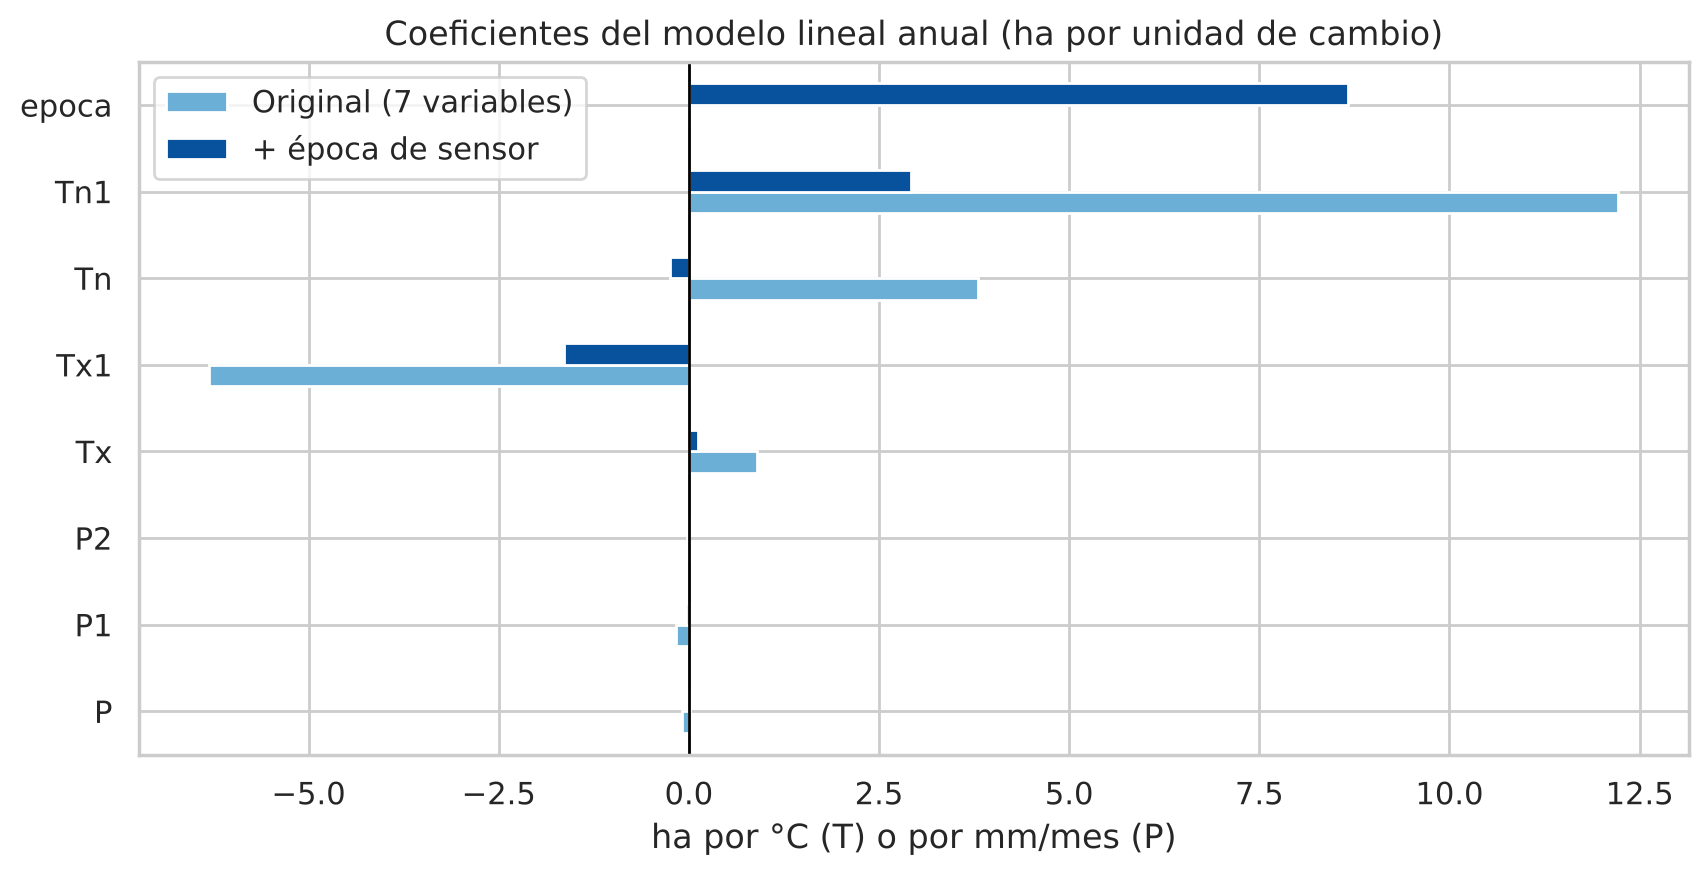

Rango de entrenamiento de P (mm/mes, media anual): 18.1 - 80.0


In [21]:
# ---- Datos anuales: serie MICE+SG de la sección 9 y clima CR2MET
n_meses_obs = df_modelo[COL_AREA].resample("YS").count()
anual_m = pd.DataFrame({"area": area_m0_sg.resample("YS").mean(),
                        "P": df_clima["precip"].resample("YS").mean(),
                        "Tx": df_clima["tmax"].resample("YS").mean(),
                        "Tn": df_clima["tmin"].resample("YS").mean()}).loc["1985":str(FIN_CLIMA.year)]
anual_m["area_obs"] = df_modelo[COL_AREA].resample("YS").mean().where(n_meses_obs >= 3).reindex(anual_m.index)
anual_m["epoca"] = (anual_m.index.year > pd.Timestamp(QUIEBRE_SENSOR).year).astype(int)
for v, n in (("P", 2), ("Tx", 1), ("Tn", 1)):
    for j in range(1, n + 1):
        anual_m[f"{v}{j}"] = anual_m[v].shift(j)

VARS_ANUAL = ["P", "P1", "P2", "Tx", "Tx1", "Tn", "Tn1"]
VARIANTES_A = {"Original (7 variables)": VARS_ANUAL, "+ época de sensor": VARS_ANUAL + ["epoca"]}
entren_a = anual_m.dropna(subset=VARS_ANUAL)
modelos_a = {nombre: LinearRegression().fit(entren_a[v], entren_a["area"]) for nombre, v in VARIANTES_A.items()}
print(f"Entrenamiento: {len(entren_a)} años ({entren_a.index.min().year}-{entren_a.index.max().year}), {len(VARS_ANUAL)} variables")
for nombre, v in VARIANTES_A.items():
    print(f"  R² dentro de la muestra – {nombre}: {modelos_a[nombre].score(entren_a[v], entren_a['area']):.2f}")

coef = pd.DataFrame({n: pd.Series(m.coef_, index=VARIANTES_A[n]) for n, m in modelos_a.items()})
display(coef.round(3))
fig, ax = plt.subplots(figsize=(10, 4.5))
coef.reindex(VARS_ANUAL + ["epoca"]).plot.barh(ax=ax, color=["#6baed6", "#08519c"])
ax.axvline(0, color="black", lw=1)
ax.set(title="Coeficientes del modelo lineal anual (ha por unidad de cambio)", xlabel="ha por °C (T) o por mm/mes (P)")
plt.show()
print("Rango de entrenamiento de P (mm/mes, media anual):", entren_a["P"].min().round(1), "-", entren_a["P"].max().round(1))

Original           GCMs usados: RCP2.6 = 12, RCP8.5 = 31


Corregido          GCMs usados: RCP2.6 = 26, RCP8.5 = 39


Corregido + época  GCMs usados: RCP2.6 = 26, RCP8.5 = 39


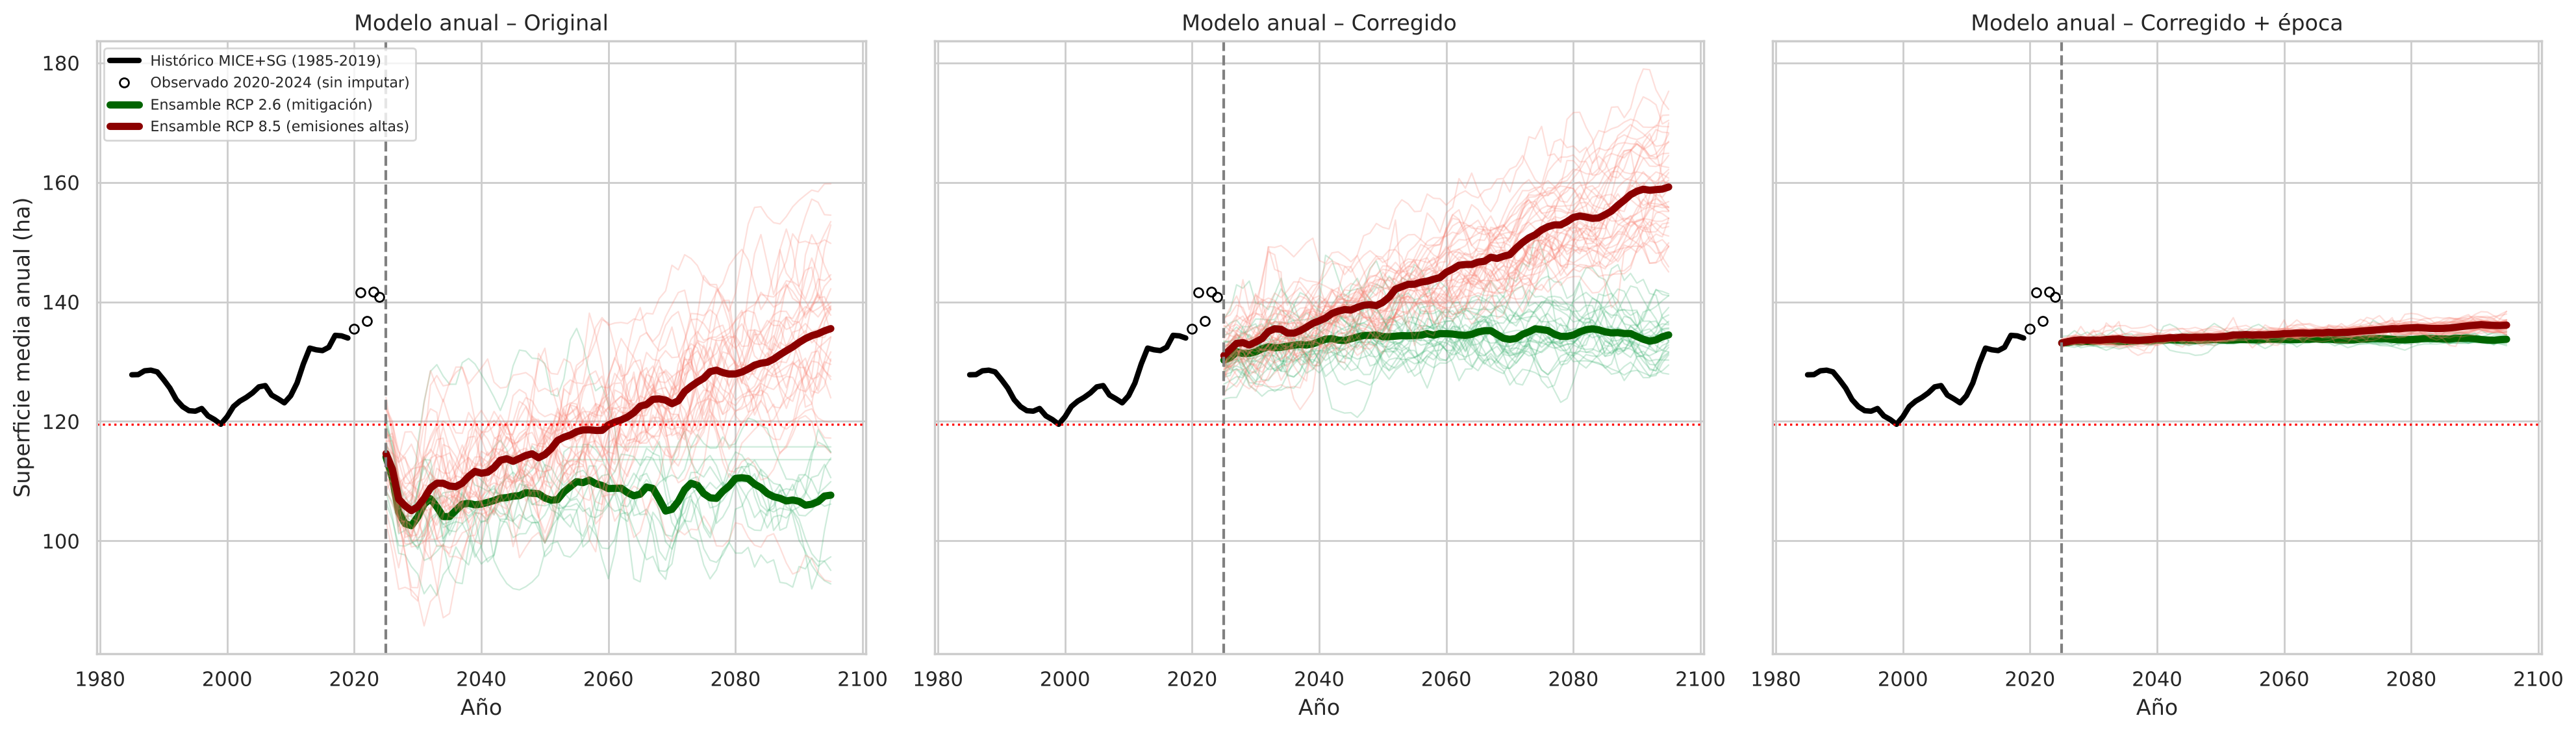

,version,horizonte,RCP26_ha,RCP85_ha,RCP85_menos_RCP26_ha
0,Original,Corto plazo (2025-2040),106.1,109.4,3.3
1,Original,Mediano plazo (2041-2070),107.9,117.8,9.9
2,Original,Largo plazo (2071-2095),108.0,129.9,21.9
3,Corregido,Corto plazo (2025-2040),132.0,134.3,2.2
4,Corregido,Mediano plazo (2041-2070),134.3,142.9,8.6
5,Corregido,Largo plazo (2071-2095),134.6,154.8,20.1
6,Corregido + época,Corto plazo (2025-2040),133.4,133.6,0.2
7,Corregido + época,Mediano plazo (2041-2070),133.7,134.5,0.8
8,Corregido + época,Largo plazo (2071-2095),133.8,135.7,1.9


In [22]:
# ---- Proyección anual por GCM (versión original y corregida)
BASE_A = anual_m[["P", "Tx", "Tn"]].mean()          # línea base: promedio histórico anual 1985-2019


def trios_gcm(escenario, version):
    """(columna precip, columna tmax, columna tmin) de cada GCM."""
    if version == "original":      # emparejamiento por POSICIÓN, como en el notebook original
        def cols(df):
            return [c for c in df.columns if escenario in c.lower() and "promedio" not in c.lower()
                    and "p05" not in c.lower() and "p95" not in c.lower()]
        return list(zip(cols(proy["precip"]), cols(proy["tmax"]), cols(proy["tmin"])))
    return [(f"{g}_pr {escenario}", f"{g}_tasmax {escenario}", f"{g}_tasmin {escenario}") for g in gcms_completos(escenario)]


def proyectar_anual(modelo, vars_, escenario, version):
    preds, X_all = {}, []
    for c_p, c_tx, c_tn in trios_gcm(escenario, version):
        t = pd.DataFrame({"Pi": proy["precip"][c_p].loc[INICIO_PROY:].resample("YS").mean(),
                          "Txa": proy["tmax"][c_tx].loc[INICIO_PROY:].resample("YS").mean(),
                          "Tna": proy["tmin"][c_tn].loc[INICIO_PROY:].resample("YS").mean()})
        if version == "original":
            t["P"] = (t["Pi"] + BASE_A["P"]).clip(lower=0)      # el índice (≈100) se suma como si fueran mm
        else:
            t["P"] = BASE_A["P"] * t["Pi"] / 100                # índice relativo a 1986-2005 → mm/mes
        t["Tx"], t["Tn"] = t["Txa"] + BASE_A["Tx"], t["Tna"] + BASE_A["Tn"]
        for v, n in (("P", 2), ("Tx", 1), ("Tn", 1)):
            for j in range(1, n + 1):
                t[f"{v}{j}"] = t[v].shift(j).fillna(BASE_A[v])  # 2020-2024 sin CR2MET: se usa la línea base
        t["epoca"] = 1
        if version == "original":
            t = t.ffill().bfill()
        if t[vars_].isna().any().any():
            continue
        preds[c_p] = pd.Series(modelo.predict(t[vars_]), index=t.index)
        X_all.append(t[vars_])
    return pd.DataFrame(preds), X_all


CONFIGS_A = {"Original": ("Original (7 variables)", "original"),
             "Corregido": ("Original (7 variables)", "corregido"),
             "Corregido + época": ("+ época de sensor", "corregido")}
resultados_a, X_a = {}, {}
for etiqueta, (variante, version) in CONFIGS_A.items():
    for esc in ("rcp26", "rcp85"):
        resultados_a[(etiqueta, esc)], X_a[(etiqueta, esc)] = proyectar_anual(
            modelos_a[variante], VARIANTES_A[variante], esc, version)
    print(f"{etiqueta:18s} GCMs usados: RCP2.6 = {resultados_a[(etiqueta, 'rcp26')].shape[1]}, "
          f"RCP8.5 = {resultados_a[(etiqueta, 'rcp85')].shape[1]}")

ANIOS = pd.date_range("1985-01-01", "2095-01-01", freq="YS")


def trayectoria(preds):
    """Media móvil de 3 años (como el original) sobre pasado + futuro; se muestra desde 2025."""
    out = {}
    for c in preds.columns:
        serie = pd.concat([anual_m["area"], preds[c]]).reindex(ANIOS)
        out[c] = serie.rolling(3, center=True, min_periods=1).mean().loc[INICIO_PROY:]
    return pd.DataFrame(out)


fig, axes = plt.subplots(1, 3, figsize=(20, 5.8), sharey=True)
hist = anual_m["area"].rolling(3, center=True, min_periods=1).mean()
obs_post = df_modelo[COL_AREA].resample("YS").mean().loc[f"{FIN_CLIMA.year + 1}":]
for ax, etiqueta in zip(axes, CONFIGS_A):
    tray = {esc: trayectoria(resultados_a[(etiqueta, esc)]) for esc in ("rcp26", "rcp85")}
    ax.plot(hist.index, hist.values, color="black", lw=3, label="Histórico MICE+SG (1985-2019)")
    ax.plot(obs_post.index, obs_post.values, "o", color="black", mfc="none", ms=5, label="Observado 2020-2024 (sin imputar)")
    for esc, (c_fino, c_grueso, nom) in COLORES.items():
        ax.plot(tray[esc].index, tray[esc].values, color=c_fino, alpha=0.25, lw=0.8)
        ax.plot(tray[esc].mean(axis=1), color=c_grueso, lw=4, label=f"Ensamble {nom}")
    ax.axvline(pd.Timestamp(INICIO_PROY), color="gray", ls="--")
    ax.axhline(hist.min(), color="red", ls=":", lw=1.2)
    ax.set(title=f"Modelo anual – {etiqueta}", xlabel="Año")
axes[0].set_ylabel("Superficie media anual (ha)")
axes[0].legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

filas = []
for etiqueta in CONFIGS_A:
    for nombre_h, (a, b) in HORIZONTES.items():
        m26 = resultados_a[(etiqueta, "rcp26")].loc[a:b].mean().mean()
        m85 = resultados_a[(etiqueta, "rcp85")].loc[a:b].mean().mean()
        filas.append((etiqueta, nombre_h, m26, m85, m85 - m26))
tabla_anual_proy = pd.DataFrame(filas, columns=["version", "horizonte", "RCP26_ha", "RCP85_ha", "RCP85_menos_RCP26_ha"]).round(1)
display(tabla_anual_proy)

Índice de precipitación de los GCM del CR2: histórico 1986-2005 = 100.0 | RCP 2.6 (2025-2095) = 96.0 | RCP 8.5 = 84.4
Precipitación observada (CR2MET): 47.2 mm/mes. Un histórico de exactamente 100 en todos los GCM indica un índice relativo, no mm. Sumarlo como mm lleva la entrada del modelo a ≈143 mm/mes, fuera del rango de entrenamiento (18-80).


,Corregido,Corregido + época
P,0.80,-0.10
P1,1.52,0.31
P2,0.16,-0.03
Tn,6.78,-0.45
Tn1,21.47,5.14
Tx,1.80,0.24
Tx1,-12.40,-3.23
epoca,0.00,0.00
TOTAL (RCP85 − RCP26),20.13,1.88


(Control: la suma de contribuciones coincide con la diferencia de la tabla anterior, +20.1 ha.)


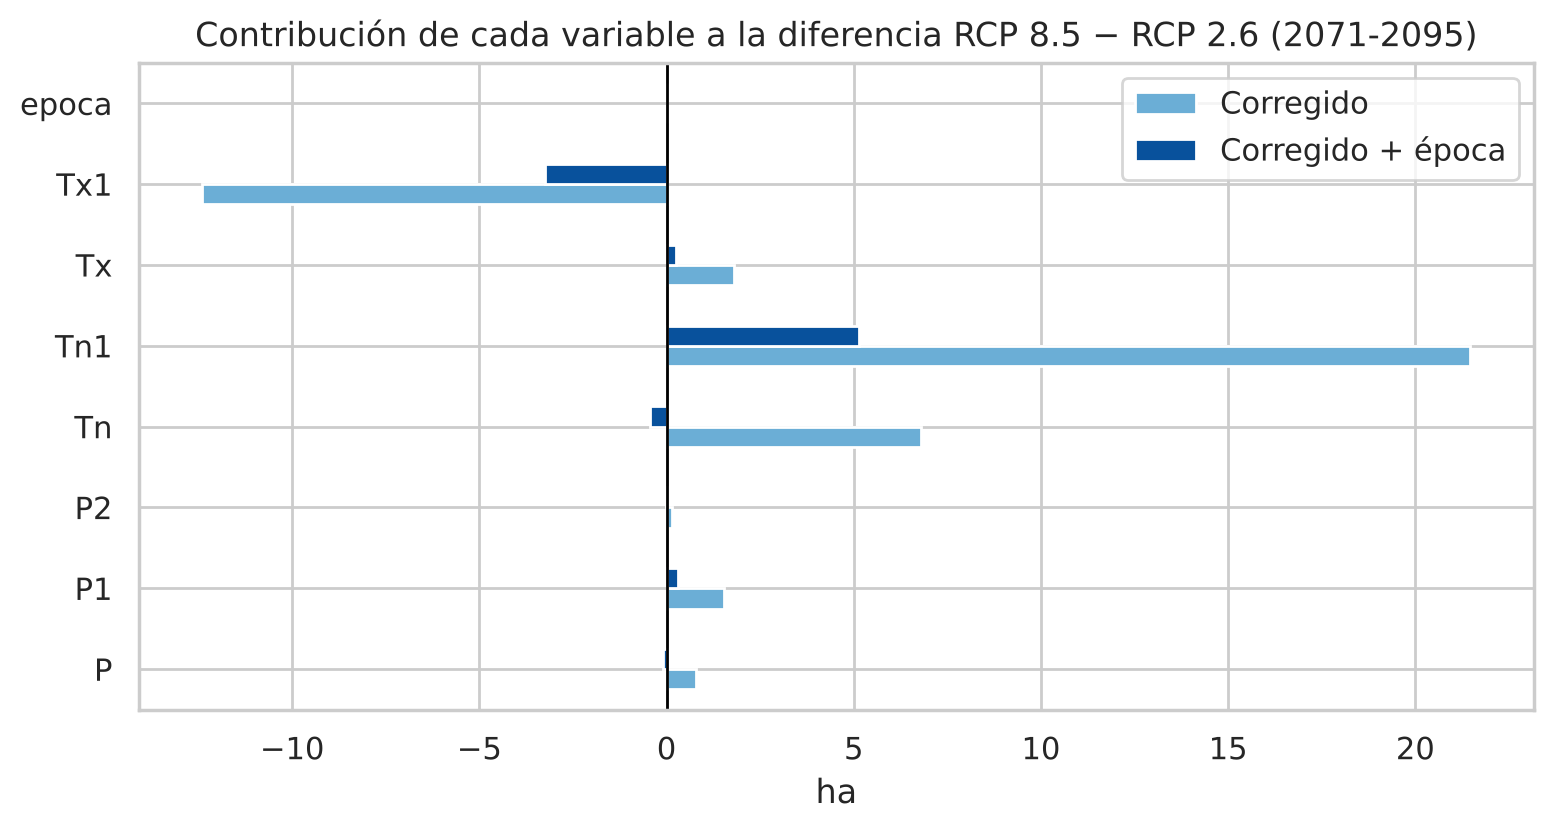

Variable que más aporta a la diferencia entre escenarios en el modelo corregido: Tn1.
Ojo: si es una temperatura rezagada, el modelo está usando el calentamiento como reemplazo de una tendencia temporal (el área sube desde 2013, cuando también cambia el sensor).


In [23]:
# ---- Diagnóstico 1: unidades de la precipitación del CR2
g26 = gcms_completos("rcp26")
idx_hist = pd.concat([proy["precip"][f"{g}_pr historical"] for g in g26], axis=1).loc["1986":"2005"].mean().mean()
idx_26 = pd.concat([proy["precip"][f"{g}_pr rcp26"] for g in g26], axis=1).loc[INICIO_PROY:].mean().mean()
idx_85 = pd.concat([proy["precip"][f"{g}_pr rcp85"] for g in gcms_completos("rcp85")], axis=1).loc[INICIO_PROY:].mean().mean()
print(f"Índice de precipitación de los GCM del CR2: histórico 1986-2005 = {idx_hist:.1f} | RCP 2.6 (2025-2095) = {idx_26:.1f} | "
      f"RCP 8.5 = {idx_85:.1f}")
print(f"Precipitación observada (CR2MET): {BASE_A['P']:.1f} mm/mes. Un histórico de exactamente 100 en todos los GCM indica un "
      f"índice relativo, no mm. Sumarlo como mm lleva la entrada del modelo a ≈{BASE_A['P'] + idx_26:.0f} mm/mes, "
      f"fuera del rango de entrenamiento ({entren_a['P'].min():.0f}-{entren_a['P'].max():.0f}).")

# ---- Diagnóstico 2: ¿qué variable produce la diferencia entre escenarios? (modelo corregido, 2071-2095)
filas = {}
for etiqueta in ("Corregido", "Corregido + época"):
    variante = CONFIGS_A[etiqueta][0]
    def media_largo_plazo(lista):   # los DataFrames de cada GCM repiten fechas: se filtra por año, no por rebanada de índice
        X = pd.concat(lista)
        return X[(X.index.year >= 2071) & (X.index.year <= 2095)].mean()
    X26, X85 = media_largo_plazo(X_a[(etiqueta, "rcp26")]), media_largo_plazo(X_a[(etiqueta, "rcp85")])
    contrib = pd.Series(modelos_a[variante].coef_, index=VARIANTES_A[variante]) * (X85 - X26)
    filas[etiqueta] = contrib
contribucion = pd.DataFrame(filas).fillna(0)
contribucion.loc["TOTAL (RCP85 − RCP26)"] = contribucion.sum()
display(contribucion.round(2))
tot = tabla_anual_proy.query("version == 'Corregido' and horizonte.str.startswith('Largo')")["RCP85_menos_RCP26_ha"].iloc[0]
print(f"(Control: la suma de contribuciones coincide con la diferencia de la tabla anterior, {tot:+.1f} ha.)")

fig, ax = plt.subplots(figsize=(9, 4.2))
contribucion.drop(index="TOTAL (RCP85 − RCP26)").plot.barh(ax=ax, color=["#6baed6", "#08519c"])
ax.axvline(0, color="black", lw=1)
ax.set(title="Contribución de cada variable a la diferencia RCP 8.5 − RCP 2.6 (2071-2095)", xlabel="ha")
plt.show()
dominante = contribucion["Corregido"].drop(index="TOTAL (RCP85 − RCP26)").abs().idxmax()
print(f"Variable que más aporta a la diferencia entre escenarios en el modelo corregido: {dominante}.")
print("Ojo: si es una temperatura rezagada, el modelo está usando el calentamiento como reemplazo de una tendencia temporal "
      "(el área sube desde 2013, cuando también cambia el sensor).")

In [24]:
# ---- Diagnóstico 3: validación hacia adelante (1 año) del modelo anual
def cv_anual(objetivo, vars_, metodo, desde=2002):
    errores = []
    for anio in range(desde, FIN_CLIMA.year + 1):
        tr_ = anual_m.dropna(subset=vars_ + [objetivo])
        tr_ = tr_[tr_.index.year < anio]
        fila = anual_m.loc[pd.Timestamp(f"{anio}-01-01")]
        if pd.isna(fila[objetivo]) or fila[vars_].isna().any() or len(tr_) < 12:
            continue
        if metodo == "lineal":
            pred = LinearRegression().fit(tr_[vars_], tr_[objetivo]).predict(fila[vars_].to_frame().T.astype(float))[0]
        elif metodo == "media":
            pred = tr_[objetivo].mean()
        else:
            pred = tr_[objetivo].iloc[-1]
        errores.append(fila[objetivo] - pred)
    return np.sqrt(np.mean(np.square(errores))), len(errores)


filas = []
for objetivo, nom_obj in (("area", "Serie MICE+SG (la que usa el modelo)"), ("area_obs", "Promedio anual observado (sin imputar)")):
    for nombre, (vars_, metodo) in {"Lineal original (7 variables)": (VARS_ANUAL, "lineal"),
                                    "Lineal + época": (VARS_ANUAL + ["epoca"], "lineal"),
                                    "Media histórica (referencia)": (VARS_ANUAL, "media"),
                                    "Año anterior (referencia)": (VARS_ANUAL, "previo")}.items():
        rmse, n = cv_anual(objetivo, vars_, metodo)
        filas.append((nom_obj, nombre, rmse, n))
cv_anual_tabla = pd.DataFrame(filas, columns=["objetivo", "modelo", "RMSE_ha", "n_años"]).round(2)
display(cv_anual_tabla.pivot(index="modelo", columns="objetivo", values="RMSE_ha"))
print("Se entrena con los años anteriores a cada año de prueba (2002-2019). Contra la serie MICE+SG el error se ve bajo porque "
      "esa serie es suave y se parece a sí misma de un año a otro; el objetivo realista es el área observada.")

objetivo,Promedio anual observado (sin imputar),Serie MICE+SG (la que usa el modelo)
modelo,,
Año anterior (referencia),4.51,2.45
Lineal + época,5.32,3.77
Lineal original (7 variables),6.56,5.34
Media histórica (referencia),5.91,5.50


Se entrena con los años anteriores a cada año de prueba (2002-2019). Contra la serie MICE+SG el error se ve bajo porque esa serie es suave y se parece a sí misma de un año a otro; el objetivo realista es el área observada.


,Mensual observado (sección 8),Anual MICE – Original,Anual MICE – Corregido,Anual MICE – Corregido + época
horizonte,,,,
Corto plazo (2025-2040),-0.1,3.3,2.2,0.2
Mediano plazo (2041-2070),-0.1,9.9,8.6,0.8
Largo plazo (2071-2095),-0.2,21.9,20.1,1.9


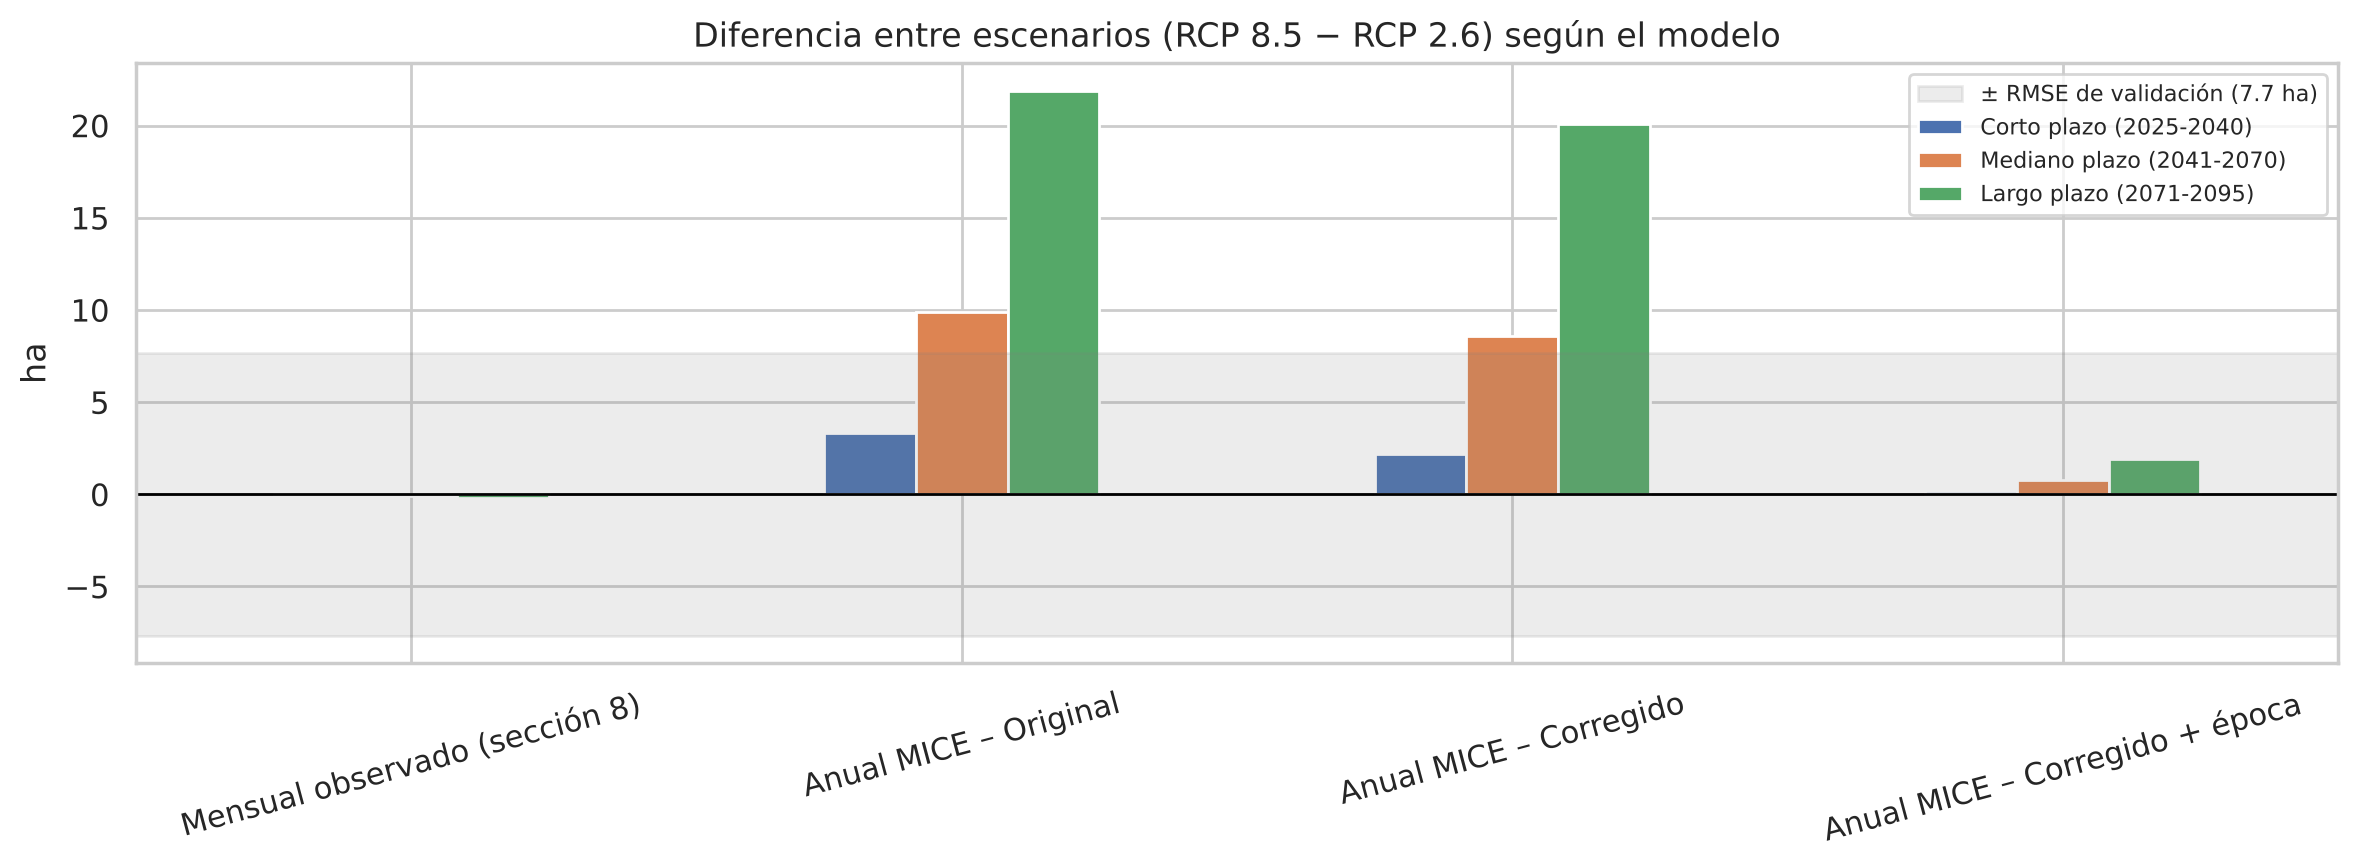

Validación contra el área observada: modelo anual lineal 6.56 ha vs media histórica 5.91 ha → el modelo anual NO supera a la media histórica.
Que un modelo muestre diferencia entre escenarios no significa que sea el más confiable: se mide por la validación y por qué variable la produce (ver diagnósticos arriba).


In [25]:
# ---- Comparación final de la diferencia entre escenarios (RCP 8.5 − RCP 2.6) por modelo
d8 = resumen_proy.pivot(index="horizonte", columns="escenario", values="area_media_ha")
comp = pd.DataFrame({"Mensual observado (sección 8)": d8["RCP85"] - d8["RCP26"]})
for etiqueta in CONFIGS_A:
    t = tabla_anual_proy[tabla_anual_proy["version"] == etiqueta].set_index("horizonte")
    comp[f"Anual MICE – {etiqueta}"] = t["RCP85_menos_RCP26_ha"]
comp = comp.reindex(list(HORIZONTES)).round(1)
display(comp)

ax = comp.T.plot.bar(figsize=(12, 4.5), rot=15)
ax.axhline(0, color="black", lw=1)
ax.axhspan(-RMSE_CV_FINAL, RMSE_CV_FINAL, color="gray", alpha=0.15, label=f"± RMSE de validación ({RMSE_CV_FINAL:.1f} ha)")
ax.set(title="Diferencia entre escenarios (RCP 8.5 − RCP 2.6) según el modelo", ylabel="ha")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

lr_obs = cv_anual_tabla.query("objetivo.str.startswith('Promedio') and modelo == 'Lineal original (7 variables)'")["RMSE_ha"].iloc[0]
media_obs = cv_anual_tabla.query("objetivo.str.startswith('Promedio') and modelo == 'Media histórica (referencia)'")["RMSE_ha"].iloc[0]
print(f"Validación contra el área observada: modelo anual lineal {lr_obs:.2f} ha vs media histórica {media_obs:.2f} ha → "
      + ("el modelo anual supera a la media." if lr_obs < media_obs else "el modelo anual NO supera a la media histórica."))
print("Que un modelo muestre diferencia entre escenarios no significa que sea el más confiable: se mide por la validación y por qué "
      "variable la produce (ver diagnósticos arriba).")

## 11. Exportación y resumen

In [26]:
df_modelo.to_csv(DIR_PROC / "base_mensual_torca_v2.csv")
anual.to_csv(DIR_PROC / "variacion_anual_v2.csv")
tabla_corr.to_csv(DIR_PROC / "correlaciones_v2.csv")
tabla_A.to_csv(DIR_PROC / "cv_nivel_area_v2.csv")
tabla_B.to_csv(DIR_PROC / "cv_anomalias_v2.csv")
tabla_sarimax.to_csv(DIR_PROC / "cv_sarimax_v2.csv")
resumen_proy.to_csv(DIR_PROC / "resumen_proyecciones_v2.csv", index=False)
for esc, df in proy_anual.items():
    df.to_csv(DIR_PROC / f"proyeccion_anual_{esc}_v2.csv")
control_anual.rename("control").to_csv(DIR_PROC / "proyeccion_anual_control_v2.csv")
tabla_cmp.to_csv(DIR_PROC / "comparacion_mice_vs_observado_cv_v2.csv")
tabla_proy_cmp.to_csv(DIR_PROC / "comparacion_mice_vs_observado_proyecciones_v2.csv", index=False)
circ.to_csv(DIR_PROC / "diagnostico_circularidad_mice_v2.csv", index=False)
tabla_anual_proy.to_csv(DIR_PROC / "modelo_anual_mice_proyecciones_v2.csv", index=False)
coef.to_csv(DIR_PROC / "modelo_anual_mice_coeficientes_v2.csv")
contribucion.to_csv(DIR_PROC / "modelo_anual_mice_contribucion_escenarios_v2.csv")
cv_anual_tabla.to_csv(DIR_PROC / "modelo_anual_mice_validacion_v2.csv", index=False)
comp.to_csv(DIR_PROC / "comparacion_diferencia_escenarios_v2.csv")
print("Archivos guardados en:", DIR_PROC.resolve())

print("\n===== RESUMEN AUTOMÁTICO DE ESTA EJECUCIÓN =====")
print(f"• Meses con área observada y clima: {len(datos)} | salto de nivel entre sensores: {SALTO_SENSOR_HA:+.1f} ha")
print(f"• Mayor |rho| área–clima (anomalías sin época): {RHO_MAX:.2f} (R² ≈ {RHO_MAX ** 2:.0%})")
print(f"• Nivel del área: mejor con clima = {MEJOR_A} → "
      f"{'supera' if CLIMA_AYUDA_A else 'no supera claramente'} a las referencias simples")
print(f"• Anomalías: mejor con clima = {MEJOR_B} → "
      f"{'supera' if CLIMA_AYUDA_B else 'no supera claramente'} a las referencias simples")
print("• Comparación con MICE (RMSE contra área observada, ha):")
for e, f in mejores.sort_values("RMSE").iterrows():
    print(f"    {e:40s} {f['RMSE']:.2f} ± {f['RMSE_std']:.2f}  ({f['modelo']}, {f['variables']})")

Archivos guardados en: /home/claude/work/data/processed

===== RESUMEN AUTOMÁTICO DE ESTA EJECUCIÓN =====
• Meses con área observada y clima: 208 | salto de nivel entre sensores: +12.9 ha
• Mayor |rho| área–clima (anomalías sin época): 0.18 (R² ≈ 3%)
• Nivel del área: mejor con clima = Ridge (+ clima) → no supera claramente a las referencias simples
• Anomalías: mejor con clima = Ridge (+ clima) → no supera claramente a las referencias simples
• Comparación con MICE (RMSE contra área observada, ha):
    Pipeline original (MICE+SG global)       7.44 ± 1.92  (Ridge, con clima)
    MICE con clima + Savitzky-Golay          7.51 ± 1.91  (Ridge, con clima)
    Observado (sin imputar)                  7.68 ± 2.09  (Ridge, con clima)
    MICE con clima                           7.68 ± 2.10  (Ridge, solo estacionalidad)
    MICE sin clima                           7.79 ± 2.20  (Ridge, con clima)


## 12. Modelo anual con lluvia acumulada, SPEI y chequeos del sensor

Esta sección aplica los cambios que sugiere la revisión de estudios parecidos (lagos andinos de Chile central, Aculeo, Mu Us, Nebraska Sand Hills, Malheur Lake). Las secciones 0-11 no cambian.

| Cambio | Por qué | Subsección |
|---|---|---|
| Descarga extendida en GEE: reflectancias armonizadas a Landsat 8 (Roy et al., 2016), MNDWI, vegetación dentro del polígono, NDVI de la cuenca y JRC Monthly Water History | Verificar el salto de 2012 con fuentes independientes y separar agua de vegetación | 12.1 |
| Calibración Landsat 7 → Landsat 5 con pares de escenas cercanas | L5 y L7 se traslapan en 1999-2003, y en esas fechas L7 mide menos | 12.2 |
| Agua vs vegetación emergente | ¿Lo que cambia es el agua o la vegetación que la cubre? | 12.3 |
| Serie anual (mínimo de fin de verano y promedio anual) con lluvia acumulada de 12/24/36 meses y SPEI-12/24 | Las lagunas responden con retraso; los estudios que funcionaron usaron ventanas largas | 12.4-12.5 |
| Validación un año hacia adelante contra persistencia y media de época | La misma exigencia de la sección 7 | 12.6 |
| Proyección RCP con el modelo anual | Es un análisis de sensibilidad si el clima no supera a las referencias | 12.7 |

**GEE solo se necesita una vez.** Con `DESCARGAR_EXTENDIDA = True`, 12.1 baja dos CSV a `data/processed`. Sin esos archivos, el resto de la sección corre igual con la serie original y se salta las partes que dependen de ellos (12.3 y la comparación de fuentes de 12.2).

**SPEI.** Se calcula con la evapotranspiración de Hargreaves (solo necesita Tmax y Tmin de CR2MET) y en versión no paramétrica: cada valor se convierte a normal estándar según su probabilidad empírica (Gringorten) dentro de los 40 años de CR2MET del mismo mes. Con tan pocos años, ajustar la log-logística del SPEI original es inestable. Las proyecciones se estandarizan contra esa misma referencia histórica.

### 12.1 Parámetros y descarga extendida (GEE)

Por cada escena Landsat se calcula, dentro del polígono de la laguna:

- **Agua NDWI y agua MNDWI** con reflectancias de Landsat 5/7 llevadas a la escala de Landsat 8 (coeficientes OLS de Roy et al., 2016). Si el salto de 2012 es un artefacto del sensor, en la serie armonizada debería achicarse.
- **Vegetación**: píxeles con NDVI > 0.2 que no son agua según MNDWI (como en el estudio de Malheur Lake).
- **Área válida**: hectáreas sin nube ni sombra. Las escenas con menos del 95 % del polígono válido se descartan.
- **NDVI de la cuenca**: NDVI medio en un anillo de 3 km alrededor de la laguna, como indicador de plantaciones y uso de suelo.

Además se baja **JRC Monthly Water History** (v1.4, 1984-2021), un producto global de agua mensual clasificado con otro algoritmo, como chequeo independiente del salto.

In [27]:
from scipy.stats import norm

# ----------------------------- Parámetros de la sección 12 -----------------------------
DESCARGAR_EXTENDIDA = False     # True = baja desde GEE la serie extendida y JRC (una sola vez; después queda en caché)
FUENTE_AREA_12 = "auto"         # "auto" | "original" | "armonizada_ndwi" | "armonizada_mndwi" | "jrc"
CORREGIR_L7 = True              # llevar Landsat 7 al nivel de Landsat 5 con pares de escenas cercanas (12.2)
DIAS_PAR = 8                    # separación máxima (días) entre una escena L7 y una L5 para formar un par
MESES_VERANO = (1, 2, 3, 4)     # el objetivo "min_verano" es el mínimo mensual en estos meses
VENTANAS_P = (12, 24, 36)       # lluvia acumulada (meses)
VENTANAS_SPEI = (12, 24)        # escalas del SPEI (meses)
BUFFER_CUENCA_M = 3000          # anillo alrededor de la laguna para el NDVI de la cuenca
VALIDO_MIN = 0.95               # fracción mínima del polígono sin nube para usar una escena de la serie extendida
CACHE_EXT, CACHE_JRC = "serie_laguna_torca_extendida.csv", "serie_laguna_torca_jrc.csv"

# Roy et al. (2016), OLS ETM+ → OLI en reflectancia de superficie: OLI = pendiente × ETM+ + intercepto.
# Para TM se usa la misma transformación (TM y ETM+ tienen bandas casi idénticas).
ROY = {"verde": (0.8483, 0.0088), "rojo": (0.9047, 0.0061), "nir": (0.8462, 0.0412), "swir1": (0.8937, 0.0254)}
NOMBRES_EXT = ["verde", "rojo", "nir", "swir1"]
BANDAS_EXT = {"LANDSAT/LT05/C02/T1_L2": ("SR_B2", "SR_B3", "SR_B4", "SR_B5"),
              "LANDSAT/LE07/C02/T1_L2": ("SR_B2", "SR_B3", "SR_B4", "SR_B5"),
              "LANDSAT/LC08/C02/T1_L2": ("SR_B3", "SR_B4", "SR_B5", "SR_B6"),
              "LANDSAT/LC09/C02/T1_L2": ("SR_B3", "SR_B4", "SR_B5", "SR_B6")}


def descargar_serie_extendida():
    """Una fila por escena: agua NDWI/MNDWI (armonizadas a OLI), vegetación, área válida y NDVI de la cuenca."""
    ee = iniciar_gee()
    geom = geometria(ee, "torca")
    anillo = geom.buffer(BUFFER_CUENCA_M).difference(geom, 1)
    px_ha = ee.Image.pixelArea().divide(1e4)
    pendiente = ee.Image.constant([ROY[b][0] for b in NOMBRES_EXT])
    intercepto = ee.Image.constant([ROY[b][1] for b in NOMBRES_EXT])
    poligono_ha = geom.area(1).getInfo() / 1e4

    def coleccion(id_coleccion, bandas):
        armonizar = "LC0" not in id_coleccion          # L5 y L7 se llevan a la escala de L8/L9

        def procesar(img):
            qa = img.select("QA_PIXEL")
            limpio = qa.bitwiseAnd(1 << 3).eq(0).And(qa.bitwiseAnd(1 << 4).eq(0))
            sr = img.select(list(bandas), NOMBRES_EXT).multiply(0.0000275).add(-0.2)   # factor de escala de Collection 2
            if armonizar:
                sr = sr.multiply(pendiente).add(intercepto)
            sr = sr.updateMask(limpio)
            mndwi = sr.normalizedDifference(["verde", "swir1"])
            ndvi = sr.normalizedDifference(["nir", "rojo"])
            capas = ee.Image.cat([sr.normalizedDifference(["verde", "nir"]).gt(0).rename("ndwi_ha"),
                                  mndwi.gt(0).rename("mndwi_ha"),
                                  ndvi.gt(0.2).And(mndwi.lte(0)).rename("veg_ha"),
                                  limpio.selfMask().rename("valido_ha")]).multiply(px_ha)
            suma = capas.reduceRegion(reducer=ee.Reducer.sum(), geometry=geom, scale=30, maxPixels=1e9)
            ndvi_cuenca = ndvi.reduceRegion(reducer=ee.Reducer.mean(), geometry=anillo, scale=30, maxPixels=1e9).get("nd")
            return ee.Feature(None, suma).set({"fecha": img.date().format("YYYY-MM-dd"),
                                               "satelite": img.get("SPACECRAFT_ID"), "ndvi_cuenca": ndvi_cuenca})

        return (ee.ImageCollection(id_coleccion).filterBounds(geom).filterDate(FECHA_INICIO, FECHA_FIN)
                .filter(ee.Filter.lt("CLOUD_COVER", NUBOSIDAD_MAX)).map(procesar))

    filas = []
    for id_coleccion, bandas in BANDAS_EXT.items():       # una consulta por misión: evita el límite de elementos de getInfo
        feats = coleccion(id_coleccion, bandas).getInfo()["features"]
        filas += [f["properties"] for f in feats]
        print(f"  {id_coleccion}: {len(feats)} escenas")
    df = pd.DataFrame(filas).reindex(columns=["fecha", "satelite", "ndwi_ha", "mndwi_ha", "veg_ha", "valido_ha", "ndvi_cuenca"])
    df["poligono_ha"] = poligono_ha
    return df


def descargar_jrc():
    """JRC Monthly Water History: hectáreas de agua (water = 2) y sin dato (water = 0) dentro del polígono, por mes."""
    ee = iniciar_gee()
    geom = geometria(ee, "torca")
    px_ha = ee.Image.pixelArea().divide(1e4)

    def procesar(img):
        w = img.select("water")
        suma = (ee.Image.cat([w.eq(2).rename("agua_ha"), w.eq(0).rename("sin_dato_ha"), w.gte(0).rename("poligono_ha")])
                .multiply(px_ha).reduceRegion(reducer=ee.Reducer.sum(), geometry=geom, scale=30, maxPixels=1e9))
        return ee.Feature(None, suma).set("fecha", img.date().format("YYYY-MM-01"))

    feats = ee.ImageCollection("JRC/GSW1_4/MonthlyHistory").filterBounds(geom).map(procesar).getInfo()["features"]
    return pd.DataFrame([f["properties"] for f in feats])


def cargar_o_descargar(nombre, funcion):
    ruta = buscar_archivo(nombre)
    if ruta is not None and not DESCARGAR_EXTENDIDA:
        print(f"{nombre}: cargado desde caché")
        df = pd.read_csv(ruta)
    elif DESCARGAR_EXTENDIDA:
        print(f"{nombre}: descargando desde Google Earth Engine...")
        df = funcion()
        df.to_csv(DIR_PROC / nombre, index=False)
    else:
        print(f"{nombre}: no está en data/processed. Con DESCARGAR_EXTENDIDA = True se baja desde GEE; se sigue sin él.")
        return None
    df["fecha"] = pd.to_datetime(df["fecha"])
    return df.drop_duplicates().sort_values("fecha").reset_index(drop=True)


df_ext = cargar_o_descargar(CACHE_EXT, descargar_serie_extendida)
df_jrc = cargar_o_descargar(CACHE_JRC, descargar_jrc)
if df_ext is not None:
    print(f"Serie extendida: {len(df_ext)} escenas | {df_ext['fecha'].min().date()} → {df_ext['fecha'].max().date()}")
if df_jrc is not None:
    print(f"JRC: {len(df_jrc)} meses | {df_jrc['fecha'].min().date()} → {df_jrc['fecha'].max().date()}")

serie_laguna_torca_extendida.csv: no está en data/processed. Con DESCARGAR_EXTENDIDA = True se baja desde GEE; se sigue sin él.
serie_laguna_torca_jrc.csv: no está en data/processed. Con DESCARGAR_EXTENDIDA = True se baja desde GEE; se sigue sin él.


### 12.2 Chequeos del sensor: Landsat 7 vs Landsat 5 y salto de 2012 por fuente

**L7 vs L5.** Entre 1999 y 2003 vuelan los dos satélites. Cada escena válida de Landsat 7 se empareja con la escena válida de Landsat 5 más cercana (≤ 8 días). La laguna casi no cambia en una semana, así que la mediana de las diferencias estima el sesgo de L7. Si `CORREGIR_L7 = True`, ese sesgo se resta a todas las escenas L7 antes de armar la serie anual. Es importante porque 1999-2003 está dominado por L7: sin corregir, esos años parecen más secos de lo que fueron.

**Salto de 2012.** Para cada fuente disponible se calcula la diferencia de nivel entre épocas (L8/L9 − L5/L7), cruda y ajustada por la lluvia del año (coeficiente de `epoca` en una regresión del área anual sobre `epoca` + lluvia de 12 meses). Si la serie armonizada o JRC muestran un salto mucho menor que la original, el salto era sobre todo del sensor.

[original] 20 pares L7–L5 (≤ 8 días): mediana L7 − L5 = -3.2 ha (IC 95 % bootstrap -4.9 a -1.7)


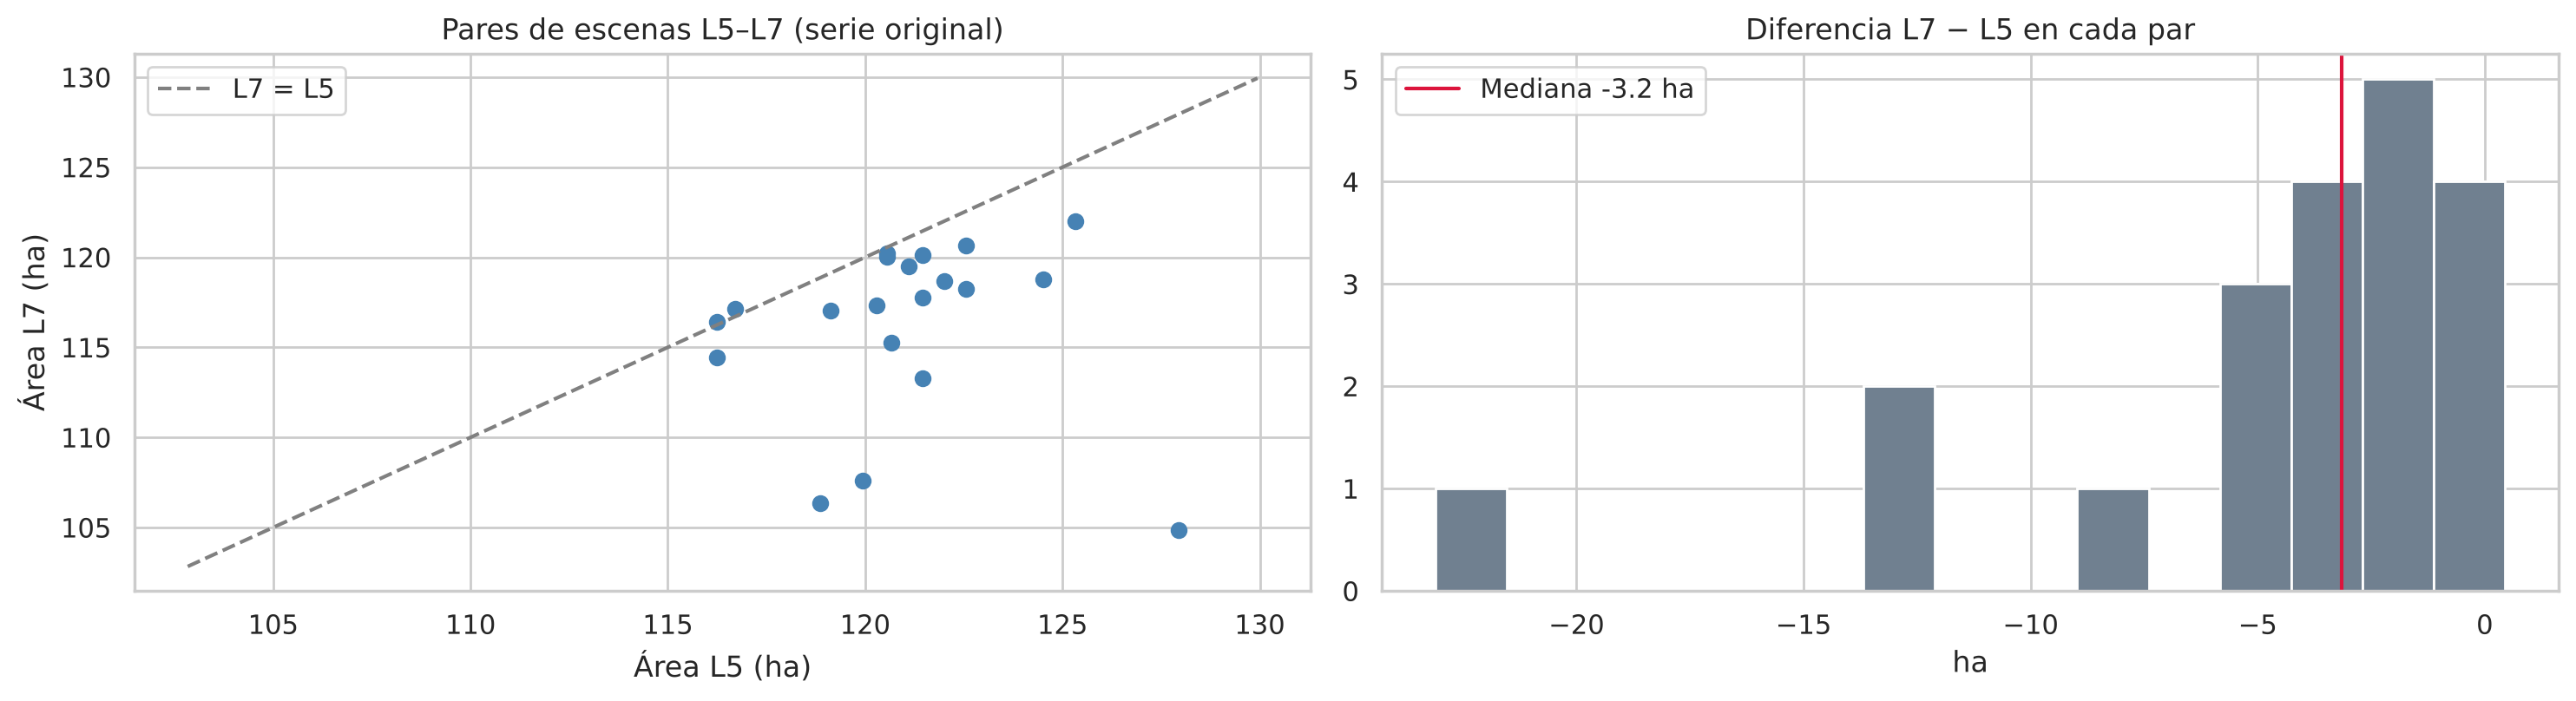

Salto entre épocas por fuente (L7 corregido donde hubo pares suficientes):


,años,media_L5L7_ha,media_L8L9_ha,salto_crudo_ha,salto_ajustado_lluvia_ha,sesgo_L7_vs_L5_ha
fuente,,,,,,
original,36,124.43,135.45,11.02,8.71,-3.15


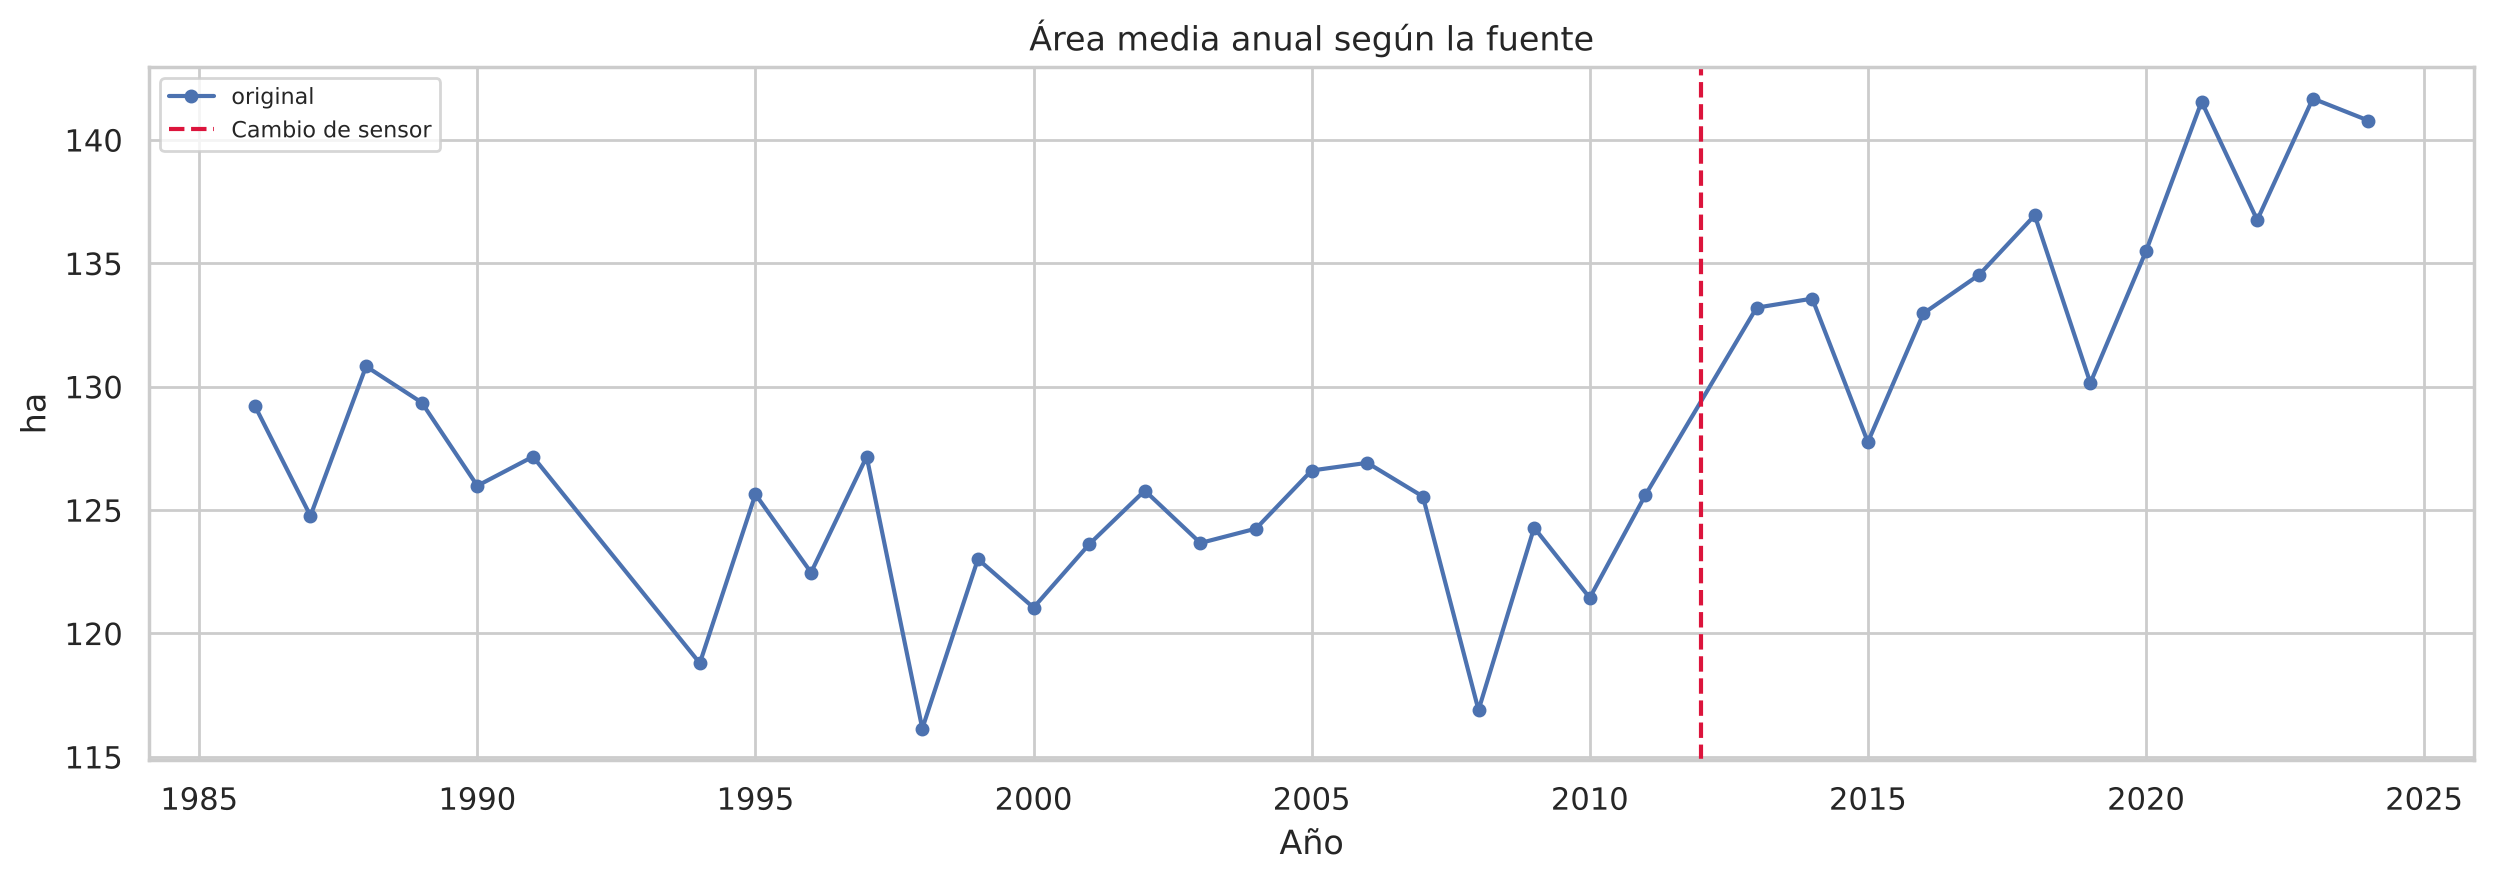

Fuente usada en el resto de la sección: original (con L7 corregido)


In [28]:
# ---- 12.2 Calibración Landsat 7 → Landsat 5 y salto entre épocas por fuente
def pares_l5_l7(curada, dias=DIAS_PAR):
    """Cada escena L7 válida con la escena L5 válida más cercana, si están a ≤ `dias` días."""
    v = curada[curada[COL_AREA].notna()]
    l5 = v.loc[v["satelite"].str.contains("LANDSAT_5", na=False), COL_AREA]
    l7 = v.loc[v["satelite"].str.contains("LANDSAT_7", na=False), COL_AREA]
    filas = []
    for fecha, a7 in l7.items():
        dist = np.abs((l5.index - fecha).days)
        if len(dist) and dist.min() <= dias:
            filas.append((fecha, a7, l5.iloc[dist.argmin()]))
    pares = pd.DataFrame(filas, columns=["fecha", "L7", "L5"])
    pares["dif_L7_menos_L5"] = pares["L7"] - pares["L5"]
    return pares


def calibrar_l7(curada, etiqueta):
    """Sesgo de L7 (mediana de L7 − L5 en pares) con IC bootstrap; si CORREGIR_L7, se resta a las escenas L7."""
    pares = pares_l5_l7(curada)
    if len(pares) < 5:
        print(f"[{etiqueta}] solo {len(pares)} pares L7–L5: no se calibra L7.")
        return curada, np.nan, pares
    rng = np.random.default_rng(SEMILLA)
    boot = [np.median(rng.choice(pares["dif_L7_menos_L5"].values, len(pares))) for _ in range(2000)]
    sesgo = pares["dif_L7_menos_L5"].median()
    lo, hi = np.percentile(boot, [2.5, 97.5])
    print(f"[{etiqueta}] {len(pares)} pares L7–L5 (≤ {DIAS_PAR} días): mediana L7 − L5 = {sesgo:+.1f} ha "
          f"(IC 95 % bootstrap {lo:+.1f} a {hi:+.1f})")
    out = curada.copy()
    if CORREGIR_L7:
        es_l7 = out["satelite"].str.contains("LANDSAT_7", na=False)
        out.loc[es_l7, COL_AREA] = out.loc[es_l7, COL_AREA] - sesgo
    return out, sesgo, pares


# Series curadas (mismas 5 reglas de la sección 2) para cada fuente con escenas individuales
curadas_12 = {"original": serie_curada}
if df_ext is not None:
    valida = (df_ext["valido_ha"] / df_ext["poligono_ha"]) >= VALIDO_MIN
    for col, nombre in (("ndwi_ha", "armonizada_ndwi"), ("mndwi_ha", "armonizada_mndwi")):
        d = df_ext[["fecha", "satelite", col]].rename(columns={col: COL_AREA})
        d.loc[~valida, COL_AREA] = np.nan                  # escenas con nube dentro del polígono
        curadas_12[nombre], _ = curar_serie(d, AREA_MIN_HA, FECHAS_AUDITADAS)

mensual_12, sesgos_l7, pares_12 = {}, {}, {}
for nombre, curada in curadas_12.items():
    corregida, sesgos_l7[nombre], pares_12[nombre] = calibrar_l7(curada, nombre)
    mensual_12[nombre] = corregida[COL_AREA].resample("MS").mean()
if df_jrc is not None:
    j = df_jrc.set_index("fecha")
    ok = (j["sin_dato_ha"] / j["poligono_ha"] < 0.05) & (j["agua_ha"] >= AREA_MIN_HA)
    mensual_12["jrc"] = j["agua_ha"].where(ok).resample("MS").mean()
    sesgos_l7["jrc"] = np.nan

p_orig = pares_12["original"]
if len(p_orig):
    fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
    axes[0].scatter(p_orig["L5"], p_orig["L7"], color="steelblue")
    lim = [p_orig[["L5", "L7"]].min().min() - 2, p_orig[["L5", "L7"]].max().max() + 2]
    axes[0].plot(lim, lim, color="gray", ls="--", label="L7 = L5")
    axes[0].set(title="Pares de escenas L5–L7 (serie original)", xlabel="Área L5 (ha)", ylabel="Área L7 (ha)")
    axes[0].legend()
    axes[1].hist(p_orig["dif_L7_menos_L5"], bins=15, color="slategray")
    axes[1].axvline(sesgos_l7["original"], color="crimson", label=f"Mediana {sesgos_l7['original']:+.1f} ha")
    axes[1].set(title="Diferencia L7 − L5 en cada par", xlabel="ha")
    axes[1].legend()
    plt.tight_layout()
    plt.show()

# ---- Salto entre épocas por fuente (área media anual, años con ≥ 3 meses observados)
lluvia_anual = df_clima["precip"].resample("YS").sum()
lluvia_anual.index = lluvia_anual.index.year
anuales_fuente, filas = {}, []
for nombre, m in mensual_12.items():
    a_ = m.groupby(m.index.year).mean().where(m.groupby(m.index.year).count() >= 3).dropna()
    anuales_fuente[nombre] = a_
    ep = (a_.index > pd.Timestamp(QUIEBRE_SENSOR).year).astype(int)
    salto_crudo = a_[ep == 1].mean() - a_[ep == 0].mean()
    d = pd.DataFrame({"area": a_, "epoca": ep, "P12": lluvia_anual.reindex(a_.index)}).dropna()
    salto_aj = LinearRegression().fit(d[["epoca", "P12"]], d["area"]).coef_[0] if d["epoca"].nunique() == 2 else np.nan
    filas.append((nombre, len(a_), a_[ep == 0].mean(), a_[ep == 1].mean(), salto_crudo, salto_aj, sesgos_l7[nombre]))
tabla_saltos = pd.DataFrame(filas, columns=["fuente", "años", "media_L5L7_ha", "media_L8L9_ha", "salto_crudo_ha",
                                            "salto_ajustado_lluvia_ha", "sesgo_L7_vs_L5_ha"]).set_index("fuente").round(2)
print("Salto entre épocas por fuente" + (" (L7 corregido donde hubo pares suficientes)" if CORREGIR_L7 else "") + ":")
display(tabla_saltos)

fig, ax = plt.subplots(figsize=(15, 4.5))
for nombre, a_ in anuales_fuente.items():
    ax.plot(a_.index, a_.values, "o-", ms=4, label=nombre)
ax.axvline(pd.Timestamp(QUIEBRE_SENSOR).year, color="crimson", ls="--", label="Cambio de sensor")
ax.set(title="Área media anual según la fuente", xlabel="Año", ylabel="ha")
ax.legend(fontsize=8)
plt.show()

if FUENTE_AREA_12 == "auto":
    FUENTE_12 = "armonizada_ndwi" if "armonizada_ndwi" in mensual_12 else "original"
else:
    assert FUENTE_AREA_12 in mensual_12, f"La fuente '{FUENTE_AREA_12}' no está disponible (falta su CSV de GEE)"
    FUENTE_12 = FUENTE_AREA_12
area_m12 = mensual_12[FUENTE_12]
L7_CORREGIDO_12 = CORREGIR_L7 and not np.isnan(sesgos_l7[FUENTE_12])
print(f"Fuente usada en el resto de la sección: {FUENTE_12}" + (" (con L7 corregido)" if L7_CORREGIDO_12 else ""))

### 12.3 Agua vs vegetación dentro del polígono

Si la vegetación emergente (totora, junquillo) avanza sobre el espejo de agua, el NDWI la cuenta como "no agua" aunque debajo haya agua. Entonces el área de agua cae sin que baje el nivel. Esta celda compara agua (MNDWI), vegetación y su suma:

- Una correlación **negativa fuerte** entre las anomalías de agua y de vegetación indica que gran parte de la variación del "agua" es vegetación que la cubre o la descubre.
- Si **agua + vegetación** varía mucho menos que el agua sola, la laguna ocupa una cubeta casi fija, y lo que se mueve es la cobertura vegetal y no el nivel.
- Se compara también la correlación de cada serie con la lluvia de 12 meses (anual, sin época).

Necesita la serie extendida de 12.1. Se usan las escenas con ≥ 95 % del polígono sin nube y sin Landsat 7 SLC-off.

In [29]:
# ---- 12.3 Agua vs vegetación
tabla_veg = None
if df_ext is None:
    print("Sin la serie extendida de GEE (12.1) no se puede separar agua de vegetación. Se omite 12.3.")
else:
    e = df_ext.set_index("fecha")
    ok = ((e["valido_ha"] / e["poligono_ha"]) >= VALIDO_MIN) & ~(e["satelite"].str.contains("LANDSAT_7", na=False)
                                                                 & (e.index > FALLA_SLC_L7))
    veg_m = e.loc[ok, ["mndwi_ha", "veg_ha"]].resample("MS").mean().dropna()
    veg_m["agua_mas_veg_ha"] = veg_m["mndwi_ha"] + veg_m["veg_ha"]

    filas = []
    anom_veg = {c: anomalia_sin_epoca(veg_m[c]) for c in veg_m.columns}
    for c in veg_m.columns:
        a_ = veg_m[c].groupby(veg_m.index.year).mean().where(veg_m[c].groupby(veg_m.index.year).count() >= 3).dropna()
        a_res = a_ - a_.groupby((a_.index > pd.Timestamp(QUIEBRE_SENSOR).year).astype(int)).transform("mean")
        r, p, n = rho_par(a_res, lluvia_anual)
        filas.append((c, veg_m[c].mean(), anom_veg[c].std(), r, p, n))
    tabla_veg = pd.DataFrame(filas, columns=["serie", "media_ha", "desv_anomalia_mensual_ha", "rho_anual_con_P12",
                                             "p", "n_años"]).set_index("serie").round(3)
    display(tabla_veg)
    r_av, p_av, n_av = rho_par(anom_veg["mndwi_ha"], anom_veg["veg_ha"])
    print(f"Correlación de Spearman entre anomalías mensuales de agua y de vegetación: rho = {r_av:+.2f} (p = {p_av:.3f}, n = {n_av})")
    ratio = tabla_veg.loc["agua_mas_veg_ha", "desv_anomalia_mensual_ha"] / tabla_veg.loc["mndwi_ha", "desv_anomalia_mensual_ha"]
    print(f"Variabilidad de agua + vegetación respecto del agua sola: {ratio:.2f} "
          + ("→ la suma es bastante más estable: lo que se mueve es sobre todo la cobertura vegetal."
             if ratio < 0.7 else "→ la suma varía casi tanto como el agua: la vegetación no explica la variación."))

    fig, ax = plt.subplots(figsize=(15, 4.5))
    for c, color in (("mndwi_ha", "royalblue"), ("veg_ha", "forestgreen"), ("agua_mas_veg_ha", "black")):
        ax.plot(veg_m.index, veg_m[c], ".", ms=4, color=color, alpha=0.7, label=c)
    ax.axvline(pd.Timestamp(QUIEBRE_SENSOR), color="crimson", ls="--", label="Cambio de sensor")
    ax.set(title="Agua (MNDWI), vegetación (NDVI > 0.2 y no agua) y su suma dentro del polígono", ylabel="ha")
    ax.legend(fontsize=8)
    plt.show()

Sin la serie extendida de GEE (12.1) no se puede separar agua de vegetación. Se omite 12.3.


### 12.4 Serie anual y predictores de escala larga

Dos objetivos anuales, armados con la fuente elegida en 12.2:

| Objetivo | Definición | Predictores climáticos |
|---|---|---|
| `min_verano` | Mínimo mensual de enero-abril del año Y (≥ 1 mes observado) | Lluvia acumulada y SPEI **al 31 de diciembre de Y−1**: lo que llovió antes del verano |
| `media_anual` | Promedio de los meses observados del año Y (≥ 3 meses) | Lluvia acumulada y SPEI **al 31 de diciembre de Y** |

Otras variables: `Tx_verano` (Tmax media de enero-abril de Y, evaporación) y, si existe la serie extendida, `ndvi_cuenca` (NDVI mediano del año en el anillo de 3 km). La variable `epoca` absorbe el salto de sensor en todos los modelos.

El mínimo de fin de verano es el indicador que más se usa para lagunas de clima mediterráneo: es cuando el balance hídrico está más exigido y casi no hay escenas con nubes.

In [30]:
# ---- 12.4 Evapotranspiración, SPEI y tabla anual
def radiacion_extraterrestre(fechas, lat=LAT_LAGUNA):
    """Ra (MJ m-2 día-1) al día 15 de cada mes, FAO-56 ec. 21."""
    j = (fechas + pd.Timedelta(days=14)).dayofyear.values
    phi = np.radians(lat)
    dr = 1 + 0.033 * np.cos(2 * np.pi * j / 365)
    decl = 0.409 * np.sin(2 * np.pi * j / 365 - 1.39)
    ws = np.arccos(-np.tan(phi) * np.tan(decl))
    return 24 * 60 / np.pi * 0.0820 * dr * (ws * np.sin(phi) * np.sin(decl) + np.cos(phi) * np.cos(decl) * np.sin(ws))


def pet_hargreaves(clima):
    """Evapotranspiración potencial mensual (mm) de Hargreaves-Samani: solo usa Tmax, Tmin y la latitud."""
    tmedia = (clima["tmax"] + clima["tmin"]) / 2
    rango = (clima["tmax"] - clima["tmin"]).clip(lower=0)
    return 0.0023 * 0.408 * radiacion_extraterrestre(clima.index) * (tmedia + 17.8) * np.sqrt(rango) * clima.index.days_in_month


def spei_no_parametrico(d_k, referencia):
    """Probabilidad empírica (Gringorten) de cada valor dentro de la referencia del mismo mes, llevada a normal estándar."""
    out = pd.Series(np.nan, index=d_k.index)
    for m in range(1, 13):
        ref = np.sort(referencia[referencia.index.month == m].dropna().values)
        x = d_k[d_k.index.month == m].dropna()
        menores = np.searchsorted(ref, x.values, side="left")
        iguales = np.searchsorted(ref, x.values, side="right") - menores
        prob = (menores + 0.5 * iguales + 0.5 - 0.44) / (len(ref) + 0.12)
        out[x.index] = norm.ppf(np.clip(prob, 0.001, 0.999))
    return out


def predictores_mensuales(clima, referencia=None):
    """Lluvia acumulada (P12, P24, P36) y SPEI (12, 24) al cierre de cada mes. `referencia`: balance hídrico acumulado
    histórico por escala (None = el propio `clima`, que es el caso histórico)."""
    balance = clima["precip"] - pet_hargreaves(clima)
    out = pd.DataFrame(index=clima.index)
    for k in VENTANAS_P:
        out[f"P{k}"] = clima["precip"].rolling(k).sum()
    acumulados = {k: balance.rolling(k).sum() for k in VENTANAS_SPEI}
    for k in VENTANAS_SPEI:
        out[f"SPEI{k}"] = spei_no_parametrico(acumulados[k], acumulados[k] if referencia is None else referencia[k])
    out["Tx_verano"] = clima["tmax"].where(clima.index.month.isin(MESES_VERANO)).groupby(clima.index.year).transform("mean")
    return out, acumulados


PRED_CLIMA = [f"P{k}" for k in VENTANAS_P] + [f"SPEI{k}" for k in VENTANAS_SPEI]
OBJETIVOS_12 = {"min_verano": 1, "media_anual": 0}     # desfase de la ventana: 1 = clima al 31-dic del año anterior

pred_hist, REF_BALANCE = predictores_mensuales(df_clima)
pet_anual = pet_hargreaves(df_clima).resample("YS").sum()
print(f"Hargreaves: ETP media {pet_anual.mean():.0f} mm/año vs lluvia media {df_clima['precip'].resample('YS').sum().mean():.0f} mm/año (CR2MET)")


def tabla_anual(area_mensual, pred_mensual, ndvi_anual=None):
    """Una fila por año con los dos objetivos, `epoca` y los predictores de cada objetivo (sufijo _min o _med)."""
    mes = area_mensual.index.month
    ver = area_mensual[mes.isin(MESES_VERANO)]
    t = pd.DataFrame({"min_verano": ver.groupby(ver.index.year).min(),
                      "media_anual": area_mensual.groupby(area_mensual.index.year).mean(),
                      "n_anual": area_mensual.groupby(area_mensual.index.year).count()})
    t.loc[t["n_anual"] < 3, "media_anual"] = np.nan
    dic = pred_mensual[pred_mensual.index.month == 12].copy()
    dic.index = dic.index.year
    anios = t.index
    t["epoca"] = (anios > pd.Timestamp(QUIEBRE_SENSOR).year).astype(int)
    t["Tx_verano"] = dic["Tx_verano"].reindex(anios).values
    for objetivo, desfase in OBJETIVOS_12.items():
        suf = "_min" if objetivo == "min_verano" else "_med"
        for v in PRED_CLIMA:
            t[v + suf] = dic[v].reindex(anios - desfase).values
    if ndvi_anual is not None:
        t["ndvi_cuenca"] = ndvi_anual.reindex(anios).values
    return t


ndvi_anual = None
if df_ext is not None and df_ext["ndvi_cuenca"].notna().any():
    ndvi_anual = df_ext.set_index("fecha")["ndvi_cuenca"].pipe(lambda s: s.groupby(s.index.year).median())
anual_12 = tabla_anual(area_m12, pred_hist, ndvi_anual)
EXTRA_12 = ["Tx_verano"] + (["ndvi_cuenca"] if ndvi_anual is not None else [])


def datos_objetivo(objetivo, hasta=FIN_CLIMA.year):
    """Filas con objetivo y todos los predictores, renombrando P12_min → P12, etc."""
    suf = "_min" if objetivo == "min_verano" else "_med"
    cols = {v + suf: v for v in PRED_CLIMA}
    d = anual_12.rename(columns=cols)[[objetivo, "epoca"] + PRED_CLIMA + EXTRA_12].loc[:hasta]
    return d.dropna().rename(columns={objetivo: "y"})


for objetivo in OBJETIVOS_12:
    d = datos_objetivo(objetivo)
    print(f"{objetivo}: {len(d)} años con objetivo y clima ({d.index.min()}-{d.index.max()}); "
          f"{int((d['epoca'] == 1).sum())} de ellos en la época L8/L9")
display(anual_12.loc[:, ["min_verano", "media_anual", "epoca", "P12_min", "P24_min", "SPEI12_min", "Tx_verano"]].round(1).tail(12))

Hargreaves: ETP media 1178 mm/año vs lluvia media 595 mm/año (CR2MET)
min_verano: 31 años con objetivo y clima (1985-2019); 7 de ellos en la época L8/L9
media_anual: 31 años con objetivo y clima (1986-2019); 7 de ellos en la época L8/L9


,min_verano,media_anual,epoca,P12_min,P24_min,SPEI12_min,Tx_verano
fecha,,,,,,,
2013,131.6,133.2,1,563.9,1038.6,-0.1,22.6
2014,127.6,133.6,1,437.1,1001.0,-0.7,22.6
2015,130.1,127.8,1,645.8,1082.9,0.4,23.5
2016,129.2,133.0,1,601.8,1247.6,0.0,22.9
2017,127.1,134.5,1,348.0,949.8,-1.5,24.0
2018,132.2,136.9,1,650.7,998.8,0.2,22.7
2019,124.4,130.2,1,359.6,1010.4,-1.2,23.1
2020,122.1,135.5,1,306.3,665.9,-1.8,NaN
2021,140.3,141.6,1,NaN,NaN,NaN,NaN


### 12.5 Correlación del área anual con lluvia acumulada y SPEI

Igual que en la sección 6: la correlación **cruda** está contaminada por el salto de sensor, porque la época L8/L9 es más reciente y coincide con la megasequía. La versión **sin época** resta la media de cada época al área y responde la pregunta de fondo: *¿los años más lluviosos que lo normal dejan una laguna más grande que lo normal?*

Como referencia de los estudios revisados: en el lago Chungará la relación lluvia-área dio R² ≈ 0.80; en Bakhtegan (Irán), |r| de 0.55 con la lluvia y de 0.68 con la evapotranspiración; en Mu Us (China), el SPEI-9/12 dio r de 0.28 a 0.47 a escala mensual.

rho_cruda  p_cruda  rho_sin_epoca  p_sin_epoca  n_años
objetivo    variable                                                         
min_verano  P12           -0.156    0.401         -0.021        0.913      31
            P24           -0.275    0.134         -0.099        0.597      31
            P36           -0.275    0.135          0.041        0.828      31
            SPEI12        -0.171    0.359         -0.013        0.945      31
            SPEI24        -0.299    0.103         -0.103        0.581      31
            Tx_verano      0.390    0.030          0.162        0.382      31
media_anual P12           -0.057    0.760          0.182        0.328      31
            P24           -0.092    0.621          0.109        0.558      31
            P36           -0.127    0.496          0.152        0.413      31
            SPEI12        -0.054    0.771          0.203        0.274      31
            SPEI24        -0.135    0.469          0.095        0.612      31
            Tx_verano      0.373    0.039          0.043        0.818      31

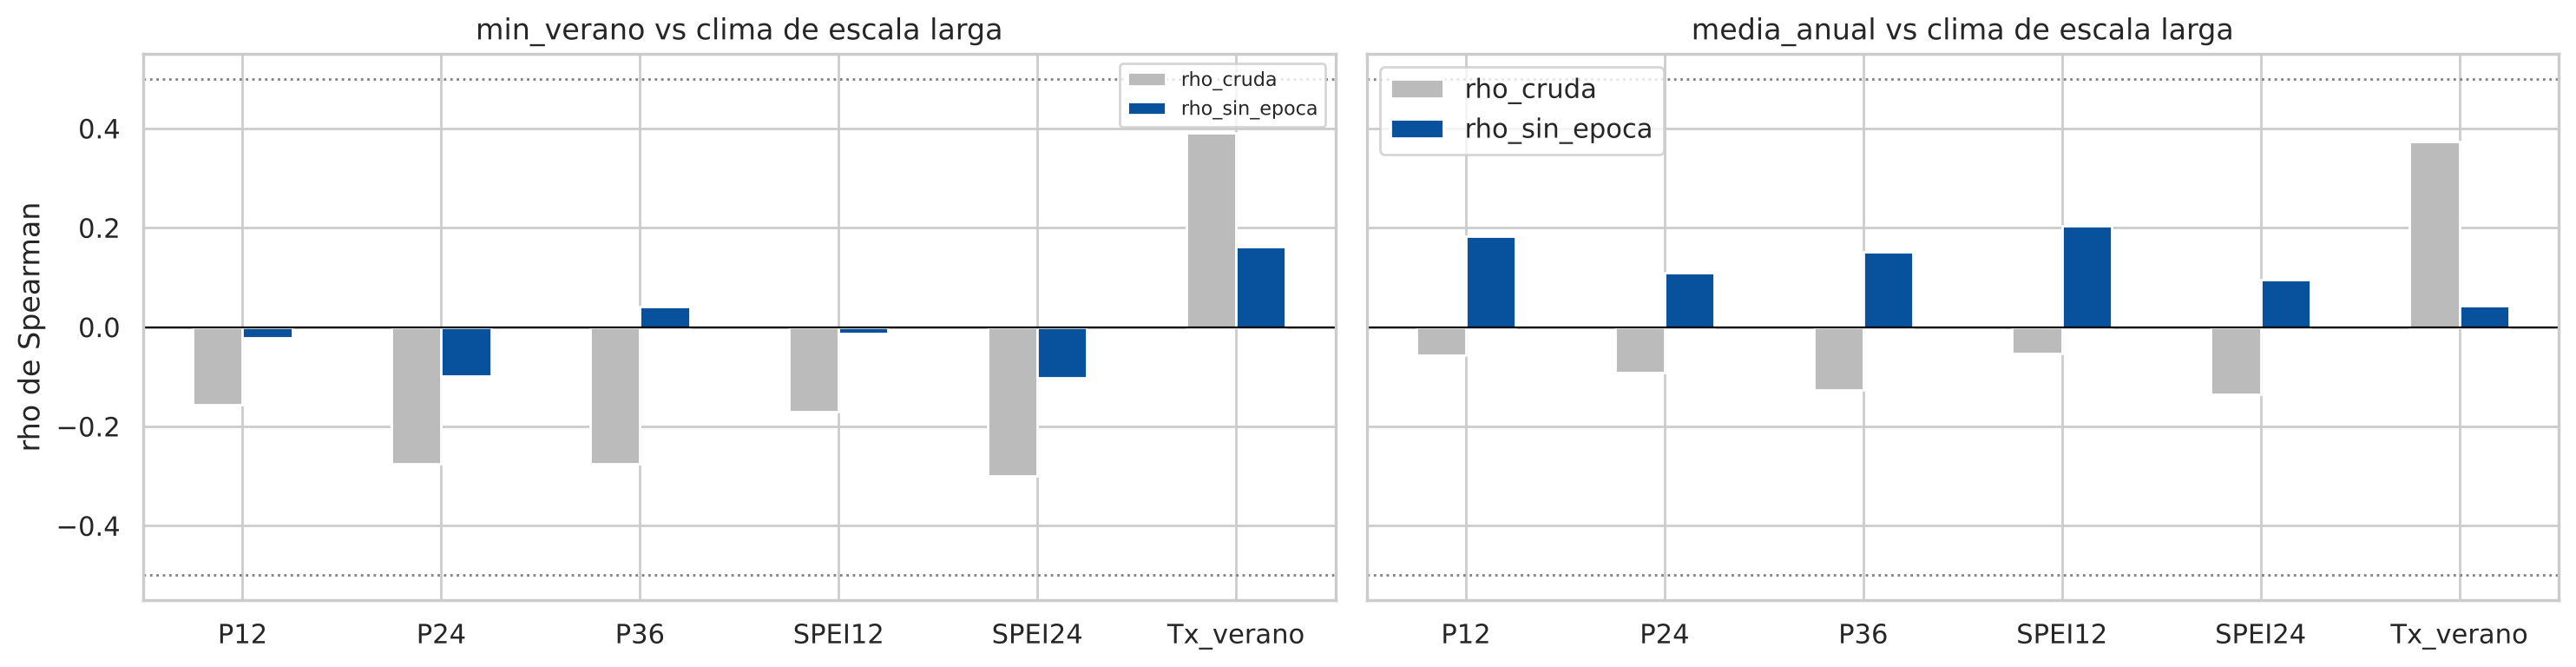

Mayor |rho| sin época con lluvia o SPEI: 0.20 (R² ≈ 4%). Las líneas punteadas marcan |rho| = 0.5, el orden de magnitud que reportan los estudios de lagos que responden a la lluvia.


In [31]:
# ---- 12.5 Correlaciones anuales (Spearman)
filas = []
for objetivo in OBJETIVOS_12:
    d = datos_objetivo(objetivo)
    y_sin_epoca = d["y"] - d.groupby("epoca")["y"].transform("mean")
    for v in PRED_CLIMA + EXTRA_12:
        r_c, p_c = spearmanr(d["y"], d[v])
        r_s, p_s = spearmanr(y_sin_epoca, d[v])
        filas.append((objetivo, v, r_c, p_c, r_s, p_s, len(d)))
tabla_corr_12 = pd.DataFrame(filas, columns=["objetivo", "variable", "rho_cruda", "p_cruda", "rho_sin_epoca",
                                             "p_sin_epoca", "n_años"]).set_index(["objetivo", "variable"]).round(3)
display(tabla_corr_12)

fig, axes = plt.subplots(1, len(OBJETIVOS_12), figsize=(15, 4), sharey=True)
for ax, objetivo in zip(axes, OBJETIVOS_12):
    tabla_corr_12.loc[objetivo, ["rho_cruda", "rho_sin_epoca"]].plot.bar(ax=ax, color=["#bbbbbb", "#08519c"], rot=0)
    ax.axhline(0, color="black", lw=0.8)
    for lim in (-0.5, 0.5):
        ax.axhline(lim, color="gray", ls=":", lw=1)
    ax.set(title=f"{objetivo} vs clima de escala larga", ylabel="rho de Spearman", xlabel="")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

RHO_MAX_12 = tabla_corr_12.loc[(slice(None), PRED_CLIMA), "rho_sin_epoca"].abs().max()
print(f"Mayor |rho| sin época con lluvia o SPEI: {RHO_MAX_12:.2f} (R² ≈ {RHO_MAX_12 ** 2:.0%}). "
      "Las líneas punteadas marcan |rho| = 0.5, el orden de magnitud que reportan los estudios de lagos que responden a la lluvia.")

### 12.6 Validación un año hacia adelante

Para cada año de prueba desde 2000, cada modelo se entrena **solo con los años anteriores** (mínimo 12) y predice ese año. Se compara contra dos referencias:

- **Media de época:** el promedio de los años anteriores de la misma época de sensor.
- **Persistencia:** el valor del año anterior observado.

Modelos con clima: regresión lineal con `epoca` + una sola variable climática (con ~30 años no caben más), Ridge con todas y Random Forest con todas (como en Wang et al., 2023, aunque con tan pocos años puede sobreajustar).

En 2013 ningún modelo tiene años L8/L9 para aprender el salto, así que todos fallan parecido ese año; el error de 2013 no favorece a ningún modelo.

**Veredicto:** el mejor modelo con clima se compara con la mejor referencia mediante un bootstrap pareado de los errores año a año. Si el intervalo de la diferencia de RMSE incluye el cero, el clima no mejora el pronóstico de forma demostrable. Elegir "el mejor" entre 7 modelos ya favorece a los modelos con clima, así que es una prueba generosa con ellos.


=== Objetivo: min_verano (fuente original) ===


,RMSE,MAE,n_años,ganancia_vs_mejor_ref_ha
Lineal: época + P36,4.71,3.81,19,0.01
Media de época (referencia),4.73,3.80,19,0.00
Lineal: época + P12,4.83,3.79,19,-0.10
Lineal: época + SPEI12,4.85,3.86,19,-0.12
Lineal: época + SPEI24,4.99,3.90,19,-0.26
Lineal: época + P24,5.00,3.84,19,-0.27
Persistencia: año anterior (referencia),5.17,4.04,19,-0.44
Random Forest: época + todas,5.27,4.10,19,-0.54
Ridge: época + todas,5.28,4.50,19,-0.56


Mejor referencia: Media de época (referencia) (RMSE 4.73 ha)
Mejor con clima:  Lineal: época + P36 (RMSE 4.71 ha)
RMSE referencia − RMSE clima = +0.02 ha (IC 95 % bootstrap pareado -0.07 a +0.10) → el intervalo incluye el cero o es negativo: el clima NO mejora el pronóstico de forma demostrable.

=== Objetivo: media_anual (fuente original) ===


,RMSE,MAE,n_años,ganancia_vs_mejor_ref_ha
Media de época (referencia),3.64,2.71,19,0.00
Lineal: época + SPEI24,3.70,2.77,19,-0.06
Lineal: época + P24,3.73,2.79,19,-0.09
Lineal: época + P36,3.85,3.01,19,-0.21
Lineal: época + P12,3.97,2.95,19,-0.33
Lineal: época + SPEI12,4.02,3.01,19,-0.38
Persistencia: año anterior (referencia),4.33,3.49,19,-0.69
Ridge: época + todas,4.40,3.40,19,-0.76
Random Forest: época + todas,5.10,3.95,19,-1.47


Mejor referencia: Media de época (referencia) (RMSE 3.64 ha)
Mejor con clima:  Lineal: época + SPEI24 (RMSE 3.70 ha)
RMSE referencia − RMSE clima = -0.06 ha (IC 95 % bootstrap pareado -0.15 a +0.02) → el intervalo incluye el cero o es negativo: el clima NO mejora el pronóstico de forma demostrable.


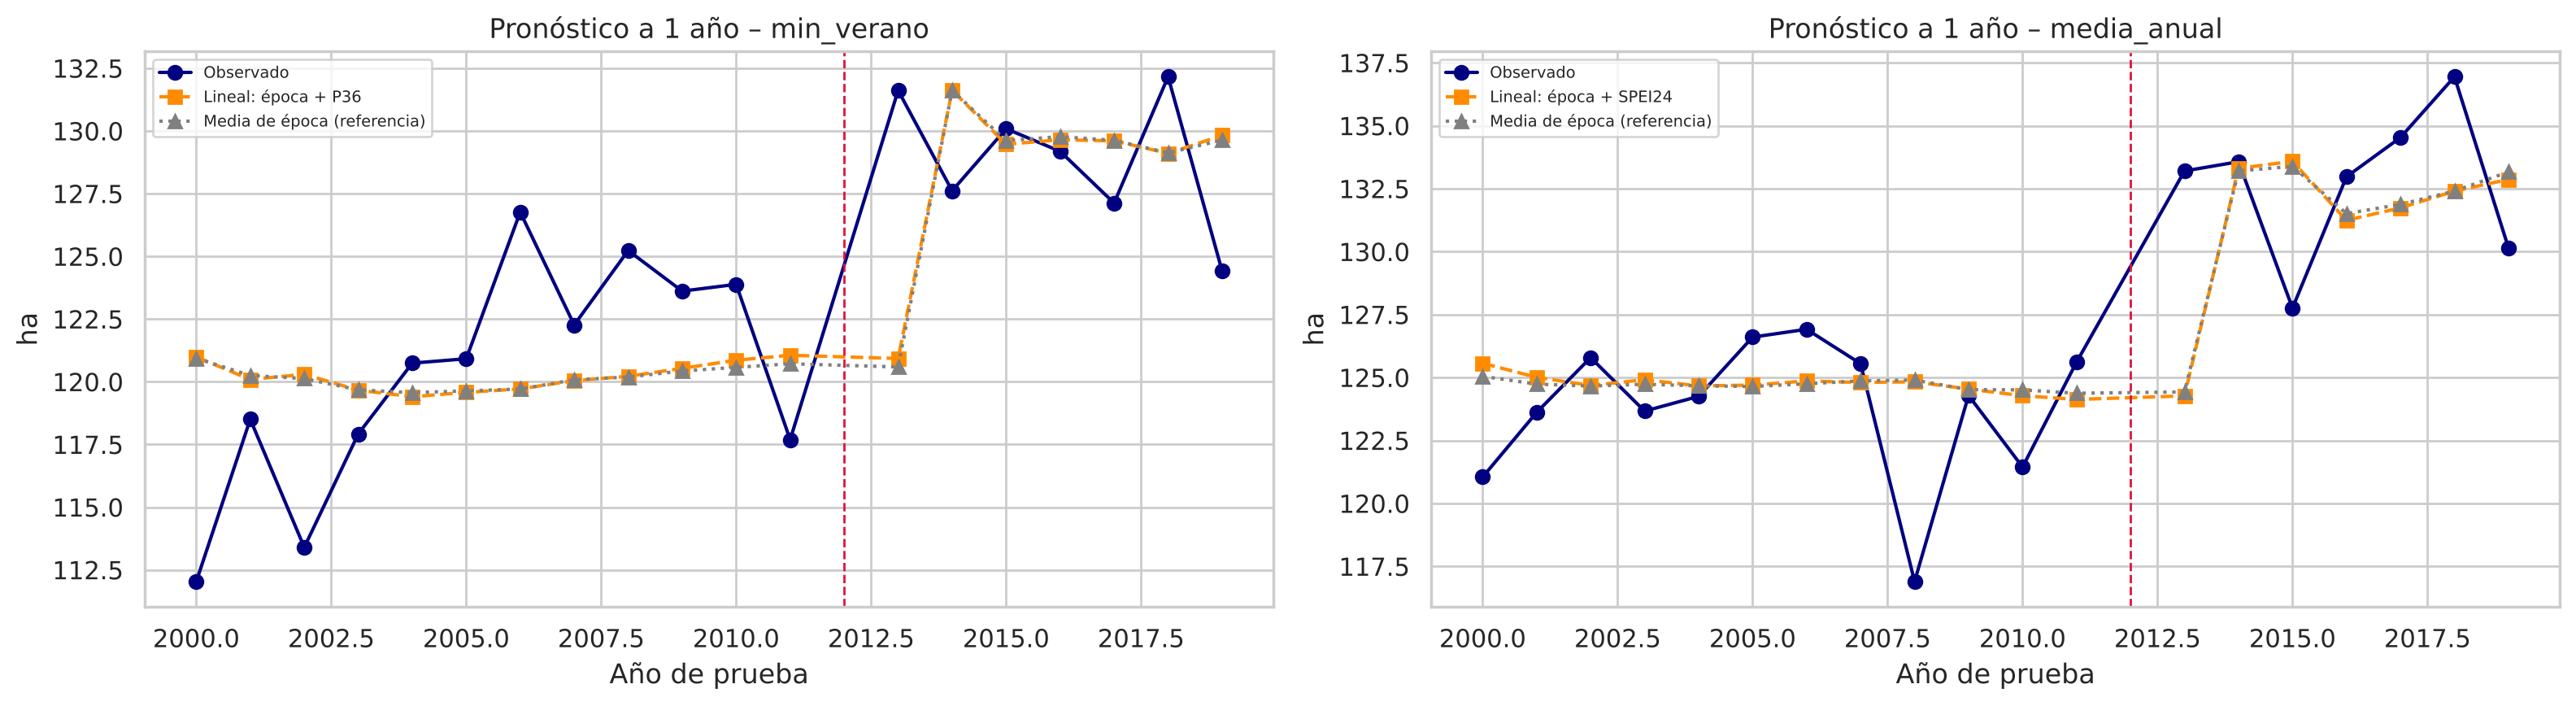

In [32]:
# ---- 12.6 Validación hacia adelante (1 año) con referencias
REF_EPOCA, REF_PERS = "Media de época (referencia)", "Persistencia: año anterior (referencia)"


def modelos_anuales_12():
    m = {REF_EPOCA: (LinearRegression(), ["epoca"])}     # con solo `epoca` predice la media de la época
    for v in PRED_CLIMA:
        m[f"Lineal: época + {v}"] = (LinearRegression(), ["epoca", v])
    todas = ["epoca"] + PRED_CLIMA + EXTRA_12
    m["Ridge: época + todas"] = (make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 20))), todas)
    m["Random Forest: época + todas"] = (RandomForestRegressor(n_estimators=500, min_samples_leaf=3,
                                                               random_state=SEMILLA, n_jobs=-1), todas)
    return m


def cv_anual_12(objetivo, desde=2000, min_entren=12):
    d = datos_objetivo(objetivo)
    preds = {}
    for anio in d.index[d.index >= desde]:
        tr = d[d.index < anio]
        if len(tr) < min_entren:
            continue
        fila = {"y": d.loc[anio, "y"], REF_PERS: tr["y"].iloc[-1]}
        for nombre, (mod, vars_) in modelos_anuales_12().items():
            fila[nombre] = clone(mod).fit(tr[vars_], tr["y"]).predict(d.loc[[anio], vars_])[0]
        preds[anio] = fila
    preds = pd.DataFrame(preds).T.astype(float)
    err = preds.drop(columns="y").sub(preds["y"], axis=0)
    tabla = pd.DataFrame({"RMSE": np.sqrt((err ** 2).mean()), "MAE": err.abs().mean(), "n_años": err.count()})
    tabla = tabla.sort_values("RMSE")
    mejor_ref = tabla.loc[[REF_EPOCA, REF_PERS], "RMSE"].idxmin()
    tabla["ganancia_vs_mejor_ref_ha"] = tabla.loc[mejor_ref, "RMSE"] - tabla["RMSE"]
    return tabla.round(2), preds, err, mejor_ref


def veredicto_12(tabla, err, mejor_ref, n_boot=5000):
    con_clima = [i for i in tabla.index if "(referencia)" not in i]
    mejor_cl = tabla.loc[con_clima, "RMSE"].idxmin()
    e_cl, e_ref = err[mejor_cl].values, err[mejor_ref].values
    rng = np.random.default_rng(SEMILLA)
    idx = rng.integers(0, len(e_cl), size=(n_boot, len(e_cl)))
    dif = np.sqrt((e_ref[idx] ** 2).mean(axis=1)) - np.sqrt((e_cl[idx] ** 2).mean(axis=1))
    lo, hi = np.percentile(dif, [2.5, 97.5])
    gana = lo > 0
    print(f"Mejor referencia: {mejor_ref} (RMSE {tabla.loc[mejor_ref, 'RMSE']:.2f} ha)")
    print(f"Mejor con clima:  {mejor_cl} (RMSE {tabla.loc[mejor_cl, 'RMSE']:.2f} ha)")
    print(f"RMSE referencia − RMSE clima = {tabla.loc[mejor_ref, 'RMSE'] - tabla.loc[mejor_cl, 'RMSE']:+.2f} ha "
          f"(IC 95 % bootstrap pareado {lo:+.2f} a {hi:+.2f}) → "
          + ("el clima MEJORA el pronóstico de forma demostrable." if gana else
             "el intervalo incluye el cero o es negativo: el clima NO mejora el pronóstico de forma demostrable."))
    return gana, mejor_cl


resultados_cv12 = {}
for objetivo in OBJETIVOS_12:
    print(f"\n=== Objetivo: {objetivo} (fuente {FUENTE_12}) ===")
    tabla, preds, err, mejor_ref = cv_anual_12(objetivo)
    display(tabla)
    gana, mejor_cl = veredicto_12(tabla, err, mejor_ref)
    resultados_cv12[objetivo] = {"tabla": tabla, "preds": preds, "gana": gana, "mejor_clima": mejor_cl, "mejor_ref": mejor_ref}

fig, axes = plt.subplots(1, len(OBJETIVOS_12), figsize=(16, 4.5))
for ax, (objetivo, r) in zip(axes, resultados_cv12.items()):
    p = r["preds"]
    ax.plot(p.index, p["y"], "o-", color="navy", label="Observado")
    ax.plot(p.index, p[r["mejor_clima"]], "s--", color="darkorange", label=r["mejor_clima"])
    ax.plot(p.index, p[r["mejor_ref"]], "^:", color="gray", label=r["mejor_ref"])
    ax.axvline(pd.Timestamp(QUIEBRE_SENSOR).year, color="crimson", ls="--", lw=1)
    ax.set(title=f"Pronóstico a 1 año – {objetivo}", xlabel="Año de prueba", ylabel="ha")
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

### 12.7 Proyección 2025-2095 con el modelo anual

Se proyecta `min_verano` con el mejor modelo con clima de 12.6, entrenado con todos los años, usando el mismo método delta por GCM de la sección 8. La serie de cada GCM parte en 2006 para tener los 36 meses de historia que necesitan P36 y SPEI-24 antes de 2025. El SPEI futuro se estandariza contra la distribución histórica de CR2MET: un SPEI de −1 en 2080 significa "tan seco como un año seco de 1979-2019".

- `epoca = 1`: la proyección queda en la escala de Landsat 8/9.
- `ndvi_cuenca` (si se usa) se fija en el promedio de los últimos 5 años observados: no hay escenarios de uso de suelo.
- **Control:** el mismo modelo con clima constante (climatología CR2MET 1986-2005). La diferencia escenario − control es lo único atribuible al cambio climático según el modelo.

Si 12.6 no mostró que el clima mejora el pronóstico, esta proyección es un **análisis de sensibilidad**, no una predicción con respaldo estadístico.

Modelo proyectado: Lineal: época + P36 | entrenado con 31 años | RMSE de validación 4.71 ha


RCP26: 26 GCMs


RCP85: 37 GCMs
RCP26: fracción de años-GCM fuera del rango de entrenamiento → P36 4%
RCP85: fracción de años-GCM fuera del rango de entrenamiento → P36 13%


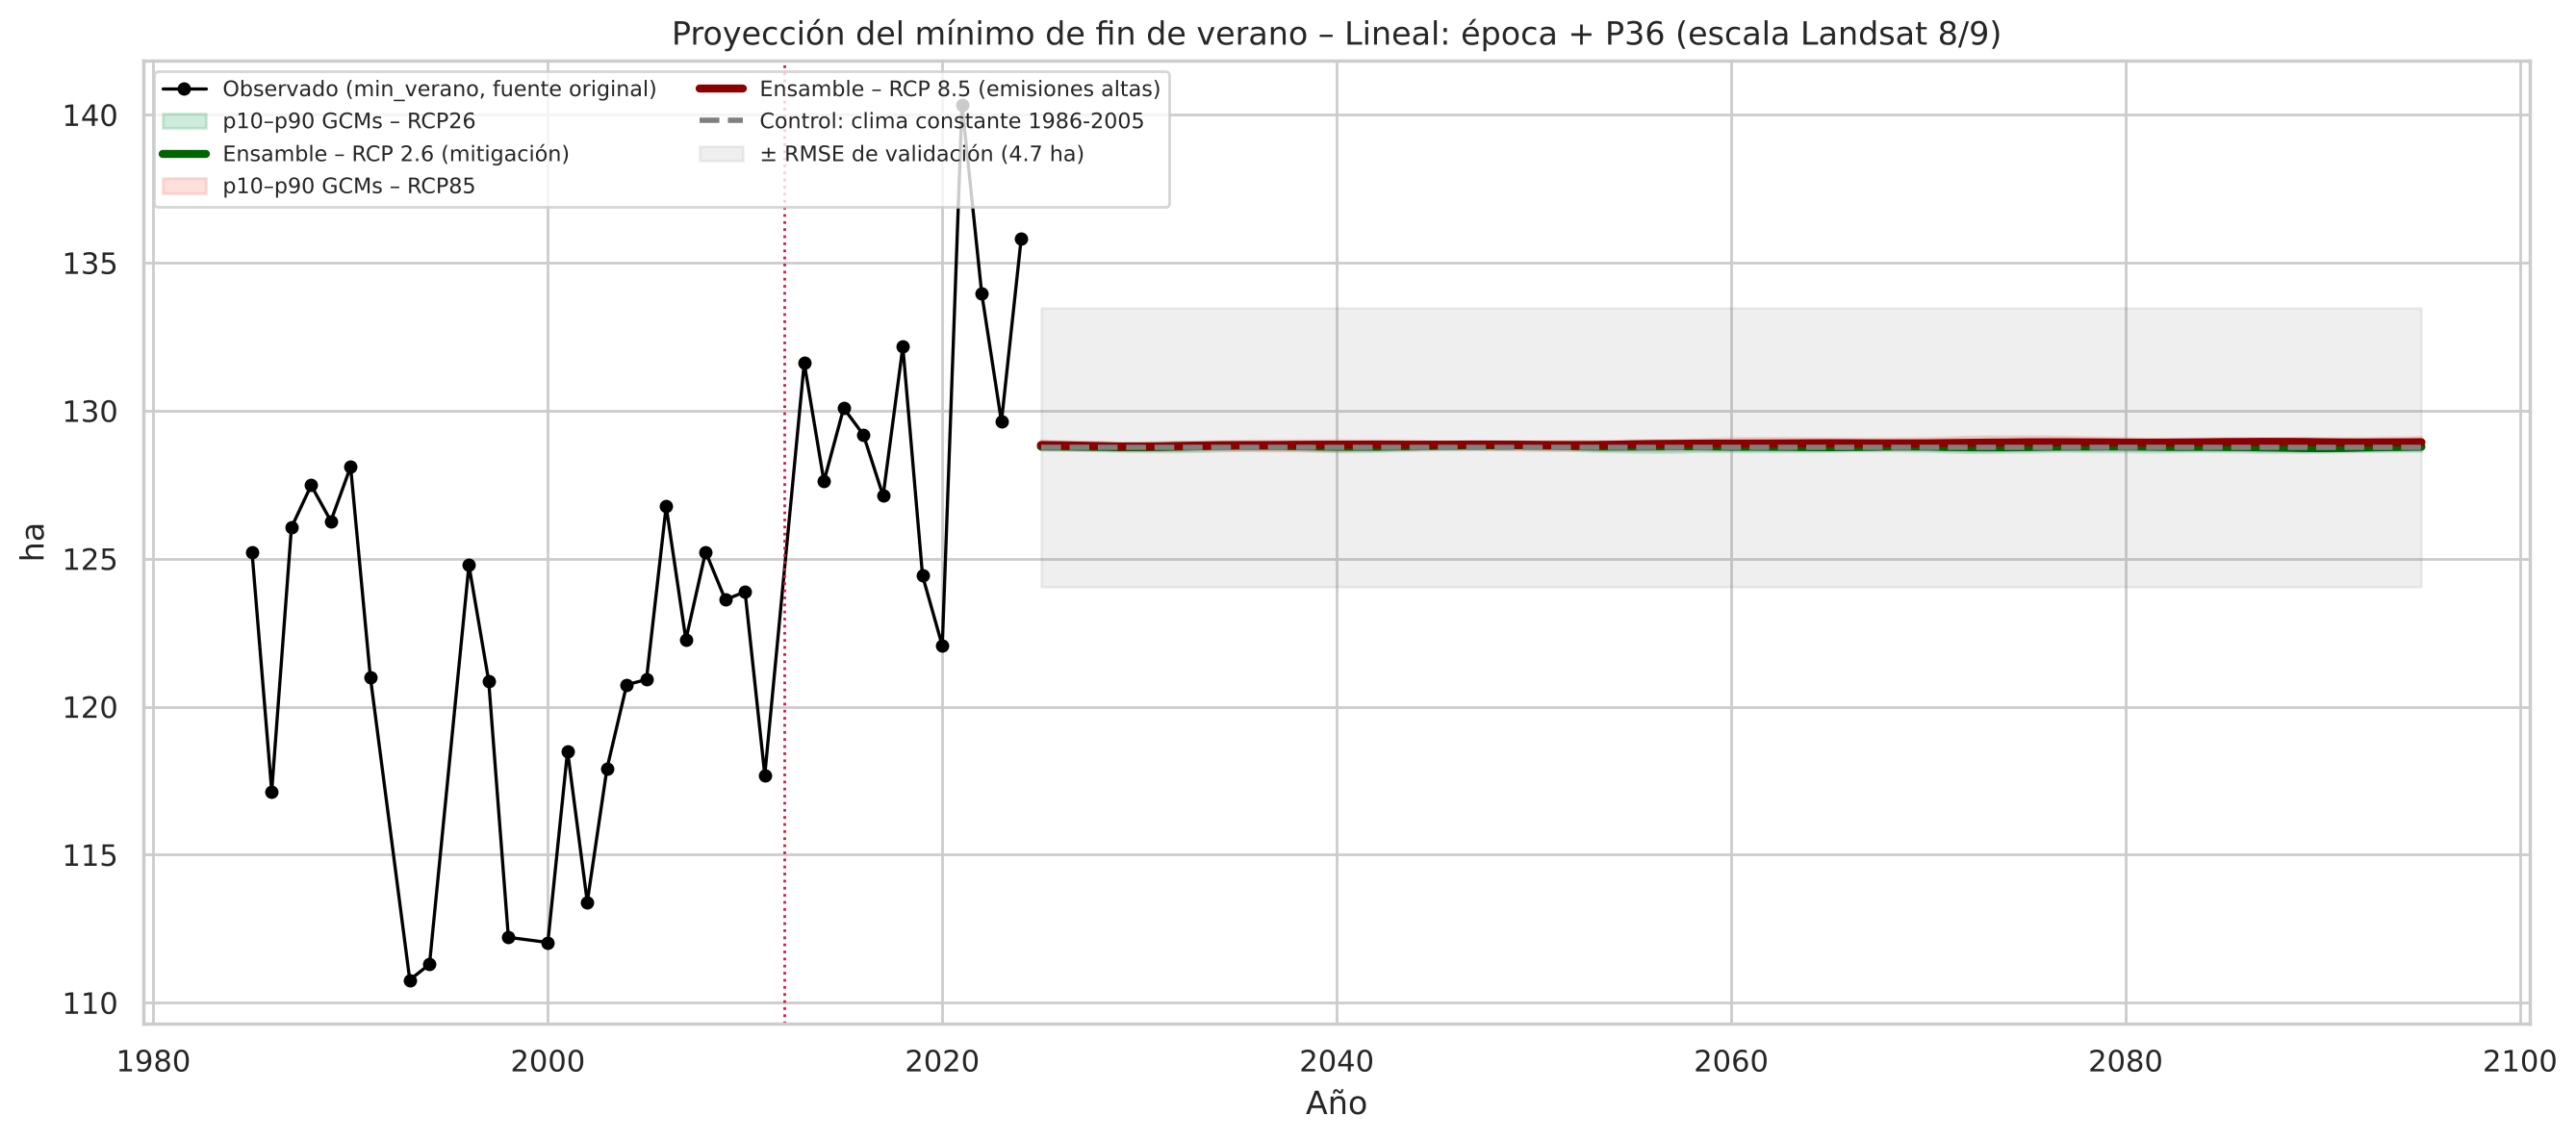

,RCP26_ha,RCP85_ha,RCP85_menos_RCP26_ha,efecto_RCP26_vs_control_ha,efecto_RCP85_vs_control_ha,RCP85_p10_gcms,RCP85_p90_gcms
horizonte,,,,,,,
Corto plazo (2025-2040),128.79,128.83,0.04,0.04,0.07,128.75,128.92
Mediano plazo (2041-2070),128.79,128.87,0.08,0.04,0.12,128.78,128.99
Largo plazo (2071-2095),128.77,128.93,0.16,0.01,0.18,128.78,129.04


ADVERTENCIA: en 12.6 el clima no mejoró el pronóstico de forma demostrable. Estas curvas son un análisis de sensibilidad del modelo, no una predicción con respaldo estadístico.
Un efecto del escenario menor que el RMSE de validación (4.7 ha) no se distingue del error del modelo.


In [33]:
# ---- 12.7 Proyección anual por GCM (método delta, igual que la sección 8, pero desde 2006)
OBJETIVO_PROY = "min_verano"
DESDE_GCM = "2006-01-01"


def clima_gcm_desde(gcm, escenario, desde=DESDE_GCM):
    """Mismo método delta que `clima_gcm` (sección 8), con la serie desde `desde`."""
    cols = {}
    for var in VARS_CLIMA:
        suf, df = SUFIJO_VAR[var], proy[var]
        ref = df[f"{gcm}_{suf} historical"].loc["1986":"2005"]
        ref_m = ref.groupby(ref.index.month).mean()
        ser = df[f"{gcm}_{suf} {escenario}"].loc[desde:]
        m = ser.index.month
        base = CLIM_BASE[var].reindex(m).values
        if var == "precip":
            cols[var] = pd.Series(base * np.clip(ser.values / np.maximum(ref_m.reindex(m).values, 1.0), 0, 3), index=ser.index)
        else:
            cols[var] = pd.Series(base + (ser.values - ref_m.reindex(m).values), index=ser.index)
    return pd.DataFrame(cols)


def X_futuro(clima, objetivo=OBJETIVO_PROY):
    """Predictores anuales desde 2025, en la escala de Landsat 8/9."""
    pm, _ = predictores_mensuales(clima, referencia=REF_BALANCE)
    dic = pm[pm.index.month == 12].copy()
    dic.index = dic.index.year
    anios = pd.Index(np.arange(pd.Timestamp(INICIO_PROY).year, clima.index.year.max() + 1))
    X = pd.DataFrame({"epoca": 1}, index=anios)
    for v in PRED_CLIMA:
        X[v] = dic[v].reindex(anios - OBJETIVOS_12[objetivo]).values
    X["Tx_verano"] = dic["Tx_verano"].reindex(anios).values
    if "ndvi_cuenca" in EXTRA_12:
        X["ndvi_cuenca"] = anual_12["ndvi_cuenca"].dropna().iloc[-5:].mean()
    return X.dropna()


r_proy = resultados_cv12[OBJETIVO_PROY]
NOMBRE_MOD_12 = r_proy["mejor_clima"]
mod_12, vars_12 = modelos_anuales_12()[NOMBRE_MOD_12]
d_proy = datos_objetivo(OBJETIVO_PROY)
mod_12 = clone(mod_12).fit(d_proy[vars_12], d_proy["y"])
RMSE_CV_12 = r_proy["tabla"].loc[NOMBRE_MOD_12, "RMSE"]
print(f"Modelo proyectado: {NOMBRE_MOD_12} | entrenado con {len(d_proy)} años | RMSE de validación {RMSE_CV_12:.2f} ha")

proy_12, X_12 = {}, {}
for esc in ("rcp26", "rcp85"):
    gcms = gcms_completos(esc, desde=DESDE_GCM)
    X_12[esc] = {g: X_futuro(clima_gcm_desde(g, esc)) for g in gcms}
    proy_12[esc] = pd.DataFrame({g: pd.Series(mod_12.predict(X[vars_12]), index=X.index) for g, X in X_12[esc].items()})
    print(f"{esc.upper()}: {len(gcms)} GCMs")

idx_ctrl = pd.date_range(DESDE_GCM, proy["precip"].index.max(), freq="MS")
clima_ctrl_12 = pd.DataFrame({v: CLIM_BASE[v].reindex(idx_ctrl.month).values for v in VARS_CLIMA}, index=idx_ctrl)
X_ctrl_12 = X_futuro(clima_ctrl_12)
control_12 = pd.Series(mod_12.predict(X_ctrl_12[vars_12]), index=X_ctrl_12.index)

# ¿Cuánto se sale el clima futuro del rango con que se entrenó el modelo?
vars_cl = [v for v in vars_12 if v in PRED_CLIMA + ["Tx_verano"]]
for esc in ("rcp26", "rcp85"):
    Xf = pd.concat(X_12[esc].values())
    fuera = ((Xf[vars_cl] < d_proy[vars_cl].min()) | (Xf[vars_cl] > d_proy[vars_cl].max())).mean()
    print(f"{esc.upper()}: fracción de años-GCM fuera del rango de entrenamiento → " +
          ", ".join(f"{v} {f:.0%}" for v, f in fuera.items()))

fig, ax = plt.subplots(figsize=(16, 6.5))
hist_12 = anual_12[OBJETIVO_PROY].dropna()
ax.plot(hist_12.index, hist_12.values, "o-", color="black", ms=4, lw=1.2, label=f"Observado ({OBJETIVO_PROY}, fuente {FUENTE_12})")
for esc, (c_fino, c_grueso, etiqueta) in COLORES.items():
    q10, q90 = proy_12[esc].quantile(0.1, axis=1), proy_12[esc].quantile(0.9, axis=1)
    ax.fill_between(q10.index, q10.rolling(5, center=True, min_periods=1).mean(),
                    q90.rolling(5, center=True, min_periods=1).mean(), color=c_fino, alpha=0.25, label=f"p10–p90 GCMs – {esc.upper()}")
    ax.plot(proy_12[esc].index, proy_12[esc].mean(axis=1).rolling(5, center=True, min_periods=1).mean(),
            color=c_grueso, lw=3, label=f"Ensamble – {etiqueta}")
ax.plot(control_12.index, control_12.rolling(5, center=True, min_periods=1).mean(), color="gray", ls="--", lw=2,
        label="Control: clima constante 1986-2005")
ax.fill_between(control_12.index, control_12 - RMSE_CV_12, control_12 + RMSE_CV_12, color="gray", alpha=0.12,
                label=f"± RMSE de validación ({RMSE_CV_12:.1f} ha)")
ax.axvline(pd.Timestamp(QUIEBRE_SENSOR).year, color="crimson", ls=":", lw=1)
ax.set(title=f"Proyección del mínimo de fin de verano – {NOMBRE_MOD_12} (escala Landsat 8/9)", xlabel="Año", ylabel="ha")
ax.legend(fontsize=8, loc="upper left", ncol=2)
plt.show()

filas = []
for nombre_h, (a, b) in HORIZONTES.items():
    a, b = int(a), int(b)
    ctrl = control_12.loc[a:b].mean()
    m = {esc: proy_12[esc].loc[a:b].mean() for esc in ("rcp26", "rcp85")}
    filas.append((nombre_h, m["rcp26"].mean(), m["rcp85"].mean(), m["rcp85"].mean() - m["rcp26"].mean(),
                  m["rcp26"].mean() - ctrl, m["rcp85"].mean() - ctrl, m["rcp85"].quantile(0.1), m["rcp85"].quantile(0.9)))
resumen_proy_12 = pd.DataFrame(filas, columns=["horizonte", "RCP26_ha", "RCP85_ha", "RCP85_menos_RCP26_ha",
                                               "efecto_RCP26_vs_control_ha", "efecto_RCP85_vs_control_ha",
                                               "RCP85_p10_gcms", "RCP85_p90_gcms"]).set_index("horizonte").round(2)
display(resumen_proy_12)
if not r_proy["gana"]:
    print("ADVERTENCIA: en 12.6 el clima no mejoró el pronóstico de forma demostrable. Estas curvas son un análisis de "
          "sensibilidad del modelo, no una predicción con respaldo estadístico.")
print(f"Un efecto del escenario menor que el RMSE de validación ({RMSE_CV_12:.1f} ha) no se distingue del error del modelo.")

In [34]:
# ---- 12.8 Exportación y resumen de la sección 12
tabla_saltos.to_csv(DIR_PROC / "anual12_saltos_por_fuente.csv")
pd.concat(pares_12, names=["fuente"]).to_csv(DIR_PROC / "anual12_pares_L5_L7.csv")
anual_12.to_csv(DIR_PROC / "anual12_base_anual.csv")
tabla_corr_12.to_csv(DIR_PROC / "anual12_correlaciones.csv")
pd.concat({o: r["tabla"] for o, r in resultados_cv12.items()}, names=["objetivo", "modelo"]).to_csv(DIR_PROC / "anual12_validacion.csv")
resumen_proy_12.to_csv(DIR_PROC / "anual12_resumen_proyecciones.csv")
for esc, df in proy_12.items():
    df.to_csv(DIR_PROC / f"anual12_proyeccion_{esc}.csv")
if tabla_veg is not None:
    tabla_veg.to_csv(DIR_PROC / "anual12_agua_vs_vegetacion.csv")
print("Archivos de la sección 12 guardados en:", DIR_PROC.resolve())

print("\n===== RESUMEN DE LA SECCIÓN 12 =====")
print(f"• Fuente del área: {FUENTE_12}" + (" (L7 corregido)" if L7_CORREGIDO_12 else ""))
print(f"• Sesgo Landsat 7 vs Landsat 5 (pares, serie original): {sesgos_l7['original']:+.1f} ha")
print("• Salto entre épocas (ajustado por lluvia), por fuente: " +
      ", ".join(f"{f} {s:+.1f} ha" for f, s in tabla_saltos["salto_ajustado_lluvia_ha"].items()))
if tabla_veg is not None:
    print(f"• Agua vs vegetación: rho de anomalías = {r_av:+.2f}; variabilidad de agua+vegetación / agua = {ratio:.2f}")
print(f"• Mayor |rho| anual sin época con lluvia acumulada o SPEI: {RHO_MAX_12:.2f}")
for o, r in resultados_cv12.items():
    t = r["tabla"]
    print(f"• {o}: mejor con clima {r['mejor_clima']} ({t.loc[r['mejor_clima'], 'RMSE']:.2f} ha) vs "
          f"{r['mejor_ref']} ({t.loc[r['mejor_ref'], 'RMSE']:.2f} ha) → "
          + ("el clima mejora de forma demostrable" if r["gana"] else "el clima no mejora de forma demostrable"))
lp = [h for h in resumen_proy_12.index if h.startswith("Largo")][0]
print(f"• Proyección {lp}: RCP 8.5 − RCP 2.6 = {resumen_proy_12.loc[lp, 'RCP85_menos_RCP26_ha']:+.1f} ha "
      f"(RMSE de validación {RMSE_CV_12:.1f} ha)")

Archivos de la sección 12 guardados en: /home/claude/work/data/processed

===== RESUMEN DE LA SECCIÓN 12 =====
• Fuente del área: original (L7 corregido)
• Sesgo Landsat 7 vs Landsat 5 (pares, serie original): -3.2 ha
• Salto entre épocas (ajustado por lluvia), por fuente: original +8.7 ha
• Mayor |rho| anual sin época con lluvia acumulada o SPEI: 0.20
• min_verano: mejor con clima Lineal: época + P36 (4.71 ha) vs Media de época (referencia) (4.73 ha) → el clima no mejora de forma demostrable
• media_anual: mejor con clima Lineal: época + SPEI24 (3.70 ha) vs Media de época (referencia) (3.64 ha) → el clima no mejora de forma demostrable
• Proyección Largo plazo (2071-2095): RCP 8.5 − RCP 2.6 = +0.2 ha (RMSE de validación 4.7 ha)


### Cómo leer la sección 12

| Si se observa… | Lectura |
|---|---|
| El salto de 2012 se achica mucho en la serie armonizada o en JRC | El salto era sobre todo del sensor; conviene usar esa fuente (`FUENTE_AREA_12`) en todo el análisis |
| El salto se mantiene en todas las fuentes | Es un cambio real de la laguna (o un artefacto común a todas). `epoca` deja de ser solo una corrección y pasa a ser parte de la historia |
| Anomalías de agua y vegetación con correlación negativa fuerte, y agua + vegetación mucho más estable | Lo que varía es la cobertura de vegetación sobre una cubeta casi fija. El área de agua no es buen indicador del volumen |
| \|rho\| sin época ≥ 0.5 y el clima gana en 12.6 | La laguna sí responde a la lluvia a escala anual: la proyección RCP tiene respaldo |
| \|rho\| bajo y el clima no gana en 12.6 | El clima local, aun a escala anual y con ventanas largas, no explica el área. Lo más probable es que la regulen su conexión con el sistema lacustre del que forma parte, el manejo o el agua subterránea. La proyección es solo un análisis de sensibilidad |

Este último caso es un resultado válido y defendible: los estudios donde la relación clima–superficie funciona son lagos endorreicos con grandes variaciones (Aculeo, Chungará, Bakhtegan). La Torca no cumple esas condiciones.

**Lo que esta sección no incluye:** nivel de agua medido (DGA), batimetría, extracciones o derechos de agua, Sentinel-2 y escenarios de uso de suelo.

## Notas metodológicas (para la discusión de la tesis)

- **Clima.** CR2MET v2.0 mensual (0.05°, 1979-2019) en el píxel más cercano a la laguna; reemplaza la estación (107 meses de precipitación y 57 de temperatura). El análisis con clima cubre hasta 2019; las escenas Landsat de 2020-2024 se usan solo para el análisis del área.
- **Sin imputación.** Se eliminó MICE y el suavizado Savitzky-Golay. La imputación con clima creaba circularidad (el clima "explicaba" valores construidos a partir de él), y el suavizado centrado filtra meses futuros hacia la validación.
- **Cambio de sensor.** Landsat 5/7 y Landsat 8/9 difieren en nivel y no se traslapan (2012 sin escenas válidas). El salto no se puede atribuir ni a hidrología ni a sensor con estos datos. Por eso el modelo incluye `epoca` y se evalúa también sobre anomalías. Sentinel-2 (desde 2015, traslapa con Landsat 8) permitiría calibrar la época reciente, pero no la antigua.
- **Landsat 7 posterior a 2003.** Se excluye porque el SLC-off corta la laguna en varias escenas.
- **MICE.** La sección 9 compara entrenar con la serie imputada contra entrenar solo con meses observados; la imputación se ajusta dentro de cada pliegue y el error se mide siempre contra área observada.
- **Modelo anual (sección 10).** Es el modelo del notebook original. Su diferencia entre escenarios se descompone por variable y se valida contra el área observada; las correcciones de unidades de precipitación y emparejamiento de GCMs están documentadas ahí.
- **Validación.** Ventana expansiva, bloques de 12-24 meses observados, siempre fuera de la muestra, y comparación explícita con la climatología y la persistencia. El RMSE de un modelo solo tiene sentido frente a esas referencias.
- **Predictores concurrentes.** En la validación se entrega el clima real del mismo mes, más favorable que pronosticar a ciegas. Los escenarios RCP aportan clima futuro con la incertidumbre propia de los GCMs.
- **Método delta y control.** El efecto del escenario se mide contra una corrida de clima constante; es lo único atribuible al cambio climático según el modelo.
- **Horizonte.** Los archivos CR2 llegan a 2095, no a 2100.
- **Extrapolación.** Los árboles no extrapolan fuera del rango de entrenamiento y Ridge puede producir valores imposibles. La sección 8 informa qué fracción de las predicciones cae fuera del rango observado.
- **Periodo del proyecto.** El documento usa 1985-2023 en el título y 2004-2023 en las preguntas; `PERIODO_INFORME` y `FECHA_INICIO/FECHA_FIN` están en la sección 0 para unificarlos.
- **No incluido.** Holt-Winters/ARIMA (serie irregular), Sentinel-2, nivel/caudal medido (DGA), marea o nivel del mar.